# Маркетплейс: здоровье продукта, юнит-экономика каналов и A/B-тест бонуса

- Автор: Ненаглядов Александр

### Запрос бизнеса

Маркетплейс быстро растет, нашел свою нишу и вышел в прибыль. До сих пор решения принимались по отчетам в Excel, бухгалтерским сводкам и интуиции - продуктовые данные системно не анализировались.

Запрос руководства: понять, как чувствует себя продукт - кто приходит, кто остается, кто платит и кто уходит; на каких каналах держится рост; какие категории товаров приносят деньги, а какие нет. Нужна не сводка значений метрик, а объяснение их динамики и приоритизированные точки роста.

Данные: выгрузка за 2024 год - пользователи, события, заказы и маркетинговые расходы по каналам.

### Описание данных

#### Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

#### Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

#### Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


#### Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



### Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


### Цель проекта

Оценить здоровье продукта и его экономику: кто приходит и остается, как продукт монетизируется, окупается ли привлечение - и на основе этого дать заказчику приоритизированные точки роста.

### План проекта
- Загрузка данных и их предобработка
- Верхнеуровневый обзор здоровья продукта
- Анализ монетизации и юнит-экономики
- Сегментация и поиск точек роста
- Анализ A/B-эксперимента
- Выводы 

### Система метрик

#### Приоритизация метрик

**Ключевая метрика бизнеса - Revenue (комиссионная выручка, 5% от оборота).** Это вершина дерева метрик и главный измеритель бизнес-результата. Однако выручка - запаздывающий индикатор: она отражает уже случившиеся изменения, но не предупреждает о них заранее. Поэтому для оценки здоровья продукта и раннего обнаружения проблем выручка раскладывается на драйверы, которые сгруппированы по приоритету.

| Уровень | Ключевые метрики | Вспомогательные |
|---|---|---|
| **1. Здоровье и активность**  | Retention, Активность (MAU), CR в заказ | WAU / DAU, Stickiness (DAU/MAU), Воронка (CTR) |
| **2. Монетизация**  | LTV, ARPPU | AOV, число плательщиков, частота заказов |
| **3. Маркетинговая эффективность**  | CAC, ROI | Payback period, бюджет по каналам |

**Ключевые метрики** двигают стратегические решения, **вспомогательные** уточняют картину и помогают в диагностике.

- На уровне 1 Retention, MAU и CR показывают, живой ли продукт; WAU/DAU и stickiness - тот же сигнал активности под другим углом.
- На уровне 2 LTV и ARPPU отвечают, сколько приносит платящий клиент; AOV, число плательщиков и частота заказов раскладывают выручку на множители (выручка = плательщики x частота x чек) и показывают, какой из них определяет ее динамику.
- На уровне 3 CAC и ROI решают главный вопрос - окупается ли привлечение; Payback period и разрез по каналам добавляют деталь.

#### Описание метрик

- **GMV** - оборот, суммарная стоимость заказов (сумма total_price). Проходит через площадку, но не является ее доходом.
- **Revenue** - выручка бизнеса, 5% комиссии от GMV. Это уже деньги площадки.
- **Retention** - удержание: доля пользователей, вернувшихся в продукт спустя N дней после регистрации.
- **MAU / WAU / DAU** - уникальные активные пользователи за месяц / неделю / день. **Stickiness** = DAU/MAU, насколько "ежедневный" продукт.
- **CR в заказ** - конверсия: доля зарегистрированных пользователей, дошедших до оплаченного заказа. **CTR** - конверсия между шагами продуктовой воронки.
- **AOV** - средний чек, средняя сумма одного заказа.
- **ARPPU** - средняя выручка на платящего пользователя.
- **LTV** - суммарная выручка с одного клиента за наблюдаемый период его жизни в продукте.
- **CAC** - стоимость привлечения одного клиента (бюджет / привлеченные).
- **ROI** - возврат на маркетинг: (LTV - CAC) / CAC. Положительный - привлечение окупается.
- **Payback period** - срок окупаемости привлечения: за сколько времени клиент отбивает свой CAC.

## Загрузка данных и их предобработка

### Загрузка данных

In [1]:
# Загрузка библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns 
import scipy.stats as st
from datetime import datetime, timedelta
from matplotlib.ticker import PercentFormatter
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import t
from scipy.stats import ttest_ind

# Создаем цветовую карту
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

In [2]:
df_orders = pd.read_csv('../datasets/marketplace_orders.csv', low_memory=False, parse_dates= ['order_date', 'order_week', 'order_month'])
df_campaign_costs = pd.read_csv('../datasets/marketplace_campaign_costs.csv', low_memory=False,  index_col=0, parse_dates= ['spend_month'])
df_users = pd.read_csv('../datasets/marketplace_users.csv', low_memory=False, parse_dates= ['registration_date', 'cohort_week', 'cohort_month'])
df_events = pd.read_csv('../datasets/marketplace_events.csv', low_memory=False, parse_dates= ['event_date', 'event_week', 'event_month'])
display('Данные загружены локально')


'Данные загружены локально'

### Знакомство с данными и предобработка

#### Общее знакомство с данными и проверка на дубликаты

In [3]:
# Общая информация о таблицах и проверка на явные дубликаты
datasets = {
    'df_users': df_users,
    'df_orders': df_orders,
    'df_events': df_events,
    'df_campaign_costs': df_campaign_costs,
}
for name, data in datasets.items():
    display(f" Информация о {name} :")
    display(data.head())
    display(data.info())
    display(f'явных дубликатов: {data.duplicated().sum()}')
    display('-'*50)

' Информация о df_users :'

,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB


None

'явных дубликатов: 0'

'--------------------------------------------------'

... (14 outputs left out)

<class 'pandas.core.frame.DataFrame'>
Index: 88 entries, 0 to 87
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   acq_channel  88 non-null     object        
 1   spend_month  88 non-null     datetime64[ns]
 2   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 2.8+ KB


None

'явных дубликатов: 0'

'--------------------------------------------------'

Пропуски присутствуют в таблице events в колонке product_name. Скорее всего они носят структурный характер и связаны с типом аналитического события, которому они соответствуют. Точно узнаем после проверки категориальных данных, сопоставив количество пропусков с событиями, не ссылающихся на название продукта.

In [4]:
# Неявные дубликаты в df_orders по связке 'user_id', 'order_date', 'product_name', 'quantity'
df_orders.duplicated(subset=['user_id', 'order_date', 'product_name', 'quantity']).sum()

np.int64(270)

In [5]:
# Найденные дубликаты
df_orders[df_orders.duplicated(subset=['user_id', 'order_date', 'product_name', 'quantity'], keep=False)].sort_values(by='user_id')

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
232,233,203,2024-02-07 22:19:44,Тетрадь общая,1,2829.81,2829.81,Книги и канцтовары,2024-02-05,2024-02-01
233,234,203,2024-02-07 22:19:44,Тетрадь общая,1,2829.81,2829.81,Книги и канцтовары,2024-02-05,2024-02-01
459,460,362,2024-01-26 02:59:13,Свечи зажигания,3,7696.64,23089.92,Автотовары,2024-01-22,2024-01-01
460,461,362,2024-01-26 02:59:13,Свечи зажигания,3,7696.64,23089.92,Автотовары,2024-01-22,2024-01-01
562,563,420,2024-01-13 19:39:50,Чайник электрический,3,6254.47,18763.41,Товары для кухни,2024-01-08,2024-01-01
...,...,...,...,...,...,...,...,...,...,...
30863,31095,41025,2024-12-07 21:50:56,Бинт эластичный,1,1152.21,1152.21,Медицинские товары,2024-12-02,2024-12-01
31092,31368,42209,2024-12-12 08:18:11,Подушки декоративные,1,6717.61,6717.61,Декор и освещение,2024-12-09,2024-12-01
31093,31369,42209,2024-12-12 08:18:11,Подушки декоративные,1,6717.61,6717.61,Декор и освещение,2024-12-09,2024-12-01
31253,31572,43300,2024-12-31 07:53:21,Рубашка классическая,3,2356.25,7068.75,Мужская одежда,2024-12-30,2024-12-01


Часть заказов задублирована при логировании. Дубликаты удаляются с сохранением первого вхождения.

In [6]:
initial_row_count = df_orders.shape[0]
df_orders = (df_orders
             .drop_duplicates(subset=['user_id', 'order_date', 'product_name', 'quantity'], keep='first')
             .reset_index(drop=True))
final_row_count = df_orders.shape[0]
deleted = initial_row_count - final_row_count
deleted_share = round(100*deleted / initial_row_count, 2) 
display(f'Удалено строк с дубликатами: {deleted}, что составило {deleted_share}% данных')

'Удалено строк с дубликатами: 270, что составило 0.86% данных'

Аналогичная проверка по `df_events` невозможна: дата логируется без времени. Проверяется только уникальность `event_id`.

In [7]:
df_events['event_id'].duplicated().sum()

np.int64(0)

#### Проверка категориальных данных

In [8]:
# Категориальные данные в df_users
for column in ['gender', 'region', 'acq_channel', 'buyer_segment']:
    display(df_users[column].value_counts())

gender
F    22126
M    22025
Name: count, dtype: int64

region
Другие регионы        14516
Москва                10959
Санкт-Петербург        6690
Московская область     3549
Екатеринбург           2145
Нижний Новгород        1748
Новосибирск            1723
Ростов-на-Дону         1423
Краснодар              1398
Name: count, dtype: int64

acq_channel
TikTok             19228
Google Ads          9319
Affiliate           6069
Social Media        4179
SEO                 3312
Email Marketing     2044
Name: count, dtype: int64

buyer_segment
medium      16421
rare        13256
regular      7773
one_time     6701
Name: count, dtype: int64

In [9]:
# Категориальные данные в df_orders
for column in ['product_name', 'category_name']:
    display(df_orders[column].value_counts())

product_name
Гречка ядрица           532
Рис длиннозерный        519
Масло подсолнечное      509
Макароны                506
Чай черный              500
                       ... 
Запонки классические    106
Пила циркулярная        106
Кольцо с бриллиантом    106
Чехлы на сиденья        104
Кровать двуспальная      98
Name: count, Length: 200, dtype: int64

category_name
Продукты питания                   4010
Детская одежда                     1405
Зоотовары                          1387
Книги и канцтовары                 1301
Аксессуары для гаджетов            1242
Одежда для спорта                  1239
Обувь мужская                      1238
Товары для кухни                   1216
Обувь женская                      1197
Женская одежда                     1174
Сумки и аксессуары                 1173
Средства для ухода                 1164
Товары для новорожденных           1151
Детские игрушки                    1124
Косметика и парфюмерия             1050
Декор и освещение                  1046
Автотовары                         1035
Бытовая техника                    1023
Украшения и часы                   1015
Мужская одежда                     1012
Спортивный инвентарь                989
Инструменты и садовый инвентарь     987
Мебель для дома                     975
Медицинские товары                  972
Товары для туризма        

In [10]:
# Категориальные данные в df_events
for column in ['event_type', 'os', 'device', 'product_name']:
    display(df_events[column].value_counts())

event_type
page_view            125663
product_view         125318
product_click        121946
add_to_cart          110675
checkout_start        92401
checkout_complete     84012
filter_apply          14243
user_login            14109
category_view         14040
remove_from_cart      14034
user_logout           13981
promo_view            13935
search                13909
banner_click          13826
wishlist_add          13767
Name: count, dtype: int64

os
Windows    200499
Android    197945
iOS        195551
macOS      191864
Name: count, dtype: int64

device
mobile     263495
tablet     261288
desktop    261076
Name: count, dtype: int64

product_name
Коврик для йоги         2030
Угги зимние             2018
Кроссовки для бега      2017
Пальто зимнее           2014
Макароны                2013
                        ... 
Лопата штыковая         1837
Микроволновка           1832
Ботинки классические    1832
Секатор садовый         1813
Брюки чино              1776
Name: count, Length: 200, dtype: int64

In [11]:
# Категориальные данные в df_campaign_costs
display(df_campaign_costs['acq_channel'].value_counts())

acq_channel
Affiliate          13
Direct             13
Email Marketing    13
Social Media       13
SEO                13
TikTok             13
Google Ads         10
Name: count, dtype: int64

In [12]:
# Google Ads встречается реже остальных: бюджет по месяцам и каналам
display(df_campaign_costs.pivot_table(
    index='spend_month', columns='acq_channel', values='budget', aggfunc='sum'))

acq_channel,Affiliate,Direct,Email Marketing,Google Ads,SEO,Social Media,TikTok
spend_month,,,,,,,
2024-01-01,179343.387500,11890.803750,44263.61250,559875.8125,59683.725000,152268.487500,1.701311e+05
2024-02-01,175488.487500,9668.378750,47437.34000,498879.1500,49700.156250,124426.180000,1.557862e+05
2024-03-01,164543.475000,8940.163125,44617.01250,567998.5000,58565.332500,151372.025000,1.716439e+05
2024-04-01,186869.975000,9747.635000,49127.68000,568075.3125,54648.922500,128261.031250,1.510094e+05
2024-05-01,166443.775000,7708.370000,42642.00000,598193.2500,55766.360000,147329.500000,2.072390e+05
2024-06-01,138644.762500,6878.835500,36863.13750,469291.9375,48464.902500,116984.718750,3.133115e+05
2024-07-01,184554.112500,9398.223750,54301.49250,583428.3125,69410.212500,165811.812500,7.095424e+05
2024-08-01,155895.562500,7997.881875,43567.90625,439754.7750,55351.077500,142327.050000,9.667835e+05
2024-09-01,138939.400000,8826.665000,40080.25750,281265.7750,48213.825000,123947.531250,1.179445e+06


С ноября записи о бюджете канала Google Ads отсутствуют.

#### Проверка количественных данных

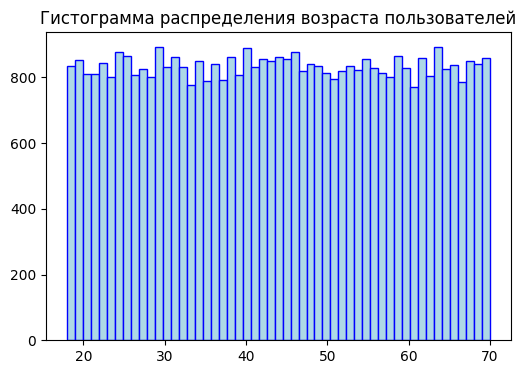

In [13]:
# Гистограмма распределения возраста пользователей
plt.figure(figsize=(6, 4))
plt.hist(df_users['age'], bins=df_users['age'].max()-df_users['age'].min()+1, color='lightblue', edgecolor='blue')
plt.title('Гистограмма распределения возраста пользователей')
plt.show()

count     31087.000000
mean      14038.536028
std       18688.925397
min         339.000000
1%          532.730000
25%        3776.740000
50%        7554.640000
75%       17657.460000
95%       47093.640000
99%       94444.830000
max      191797.140000
Name: total_price, dtype: float64

'total_price <= 0:'

np.int64(0)

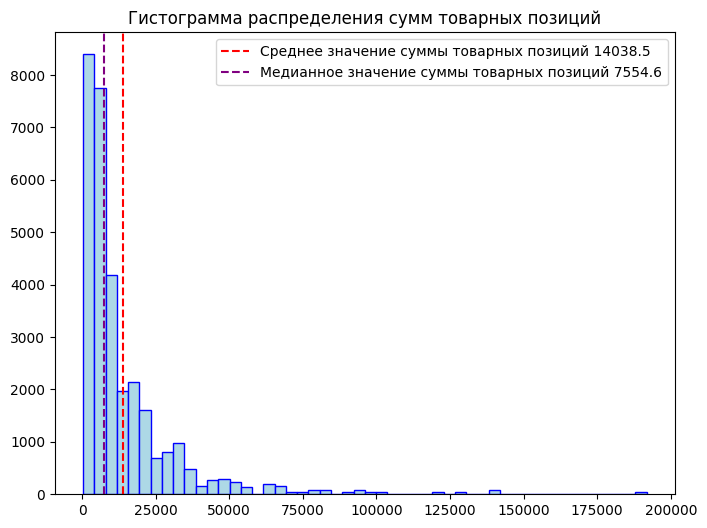

In [14]:
display(df_orders['total_price'].describe(
    percentiles=[.01, .25, .5, .75, .95, .99]))
display('total_price <= 0:', (df_orders['total_price'] <= 0).sum())
# Гистограмма распределения сумм заказов
plt.figure(figsize=(8, 6))
plt.hist(df_orders['total_price'], bins=50, color='lightblue', edgecolor='blue')
plt.title('Гистограмма распределения сумм товарных позиций')
plt.axvline(df_orders['total_price'].mean(), color='red', ls='--', label=f"Среднее значение суммы товарных позиций {df_orders['total_price'].mean():.1f}")
plt.axvline(df_orders['total_price'].median(), color='purple', ls='--', label=f"Медианное значение суммы товарных позиций {df_orders['total_price'].median():.1f}")
plt.legend()
plt.show()

In [15]:
# Согласованность суммы заказа с ценой товара и количеством в таблице df_orders
diff = (df_orders['total_price'] - df_orders['quantity'] * df_orders['unit_price']).abs()
display(f"Расхождений сверх 0.01: {(diff > 0.01).sum()} | максимальное: {diff.max():.2e}")

'Расхождений сверх 0.01: 74 | максимальное: 1.00e-02'

Расхождения минимальны и, скорее всего, связаны с округлением сумм до копейки

#### Проверка временных периодов

In [16]:
periods = {
    'users.registration_date': df_users['registration_date'],
    'orders.order_date': df_orders['order_date'],
    'events.event_date': df_events['event_date'],
    'costs.spend_month': df_campaign_costs['spend_month'],
}
for name, s in periods.items():
    display(f"{name}: {s.min()} - {s.max()} | месяцев: {s.dt.to_period('M').nunique()}")

'users.registration_date: 2024-01-01 00:07:00 - 2024-12-31 23:44:00 | месяцев: 12'

'orders.order_date: 2024-01-01 08:03:45 - 2024-12-31 23:00:53 | месяцев: 12'

'events.event_date: 2024-01-01 00:00:00 - 2024-12-31 00:00:00 | месяцев: 12'

'costs.spend_month: 2024-01-01 00:00:00 - 2025-01-01 00:00:00 | месяцев: 13'

Временной период совпадает с заявленным кроме таблицы с маркетинговыми затратами (в нее попали данные за январь 2025г)

#### Проверка связности таблиц по user_id

In [17]:
# Пользователи, присутствующие в событиях и заказах, но отсутствующие в витрине users
mask_e = ~df_events['user_id'].isin(df_users['user_id'])
mask_o = ~df_orders['user_id'].isin(df_users['user_id'])
orphans = df_events.loc[mask_e, 'user_id'].unique()

display(f"событий без профиля: {mask_e.sum()} ({mask_e.mean():.1%})")
display(f"строк заказов без профиля: {mask_o.sum()} ({mask_o.mean():.1%})")
display(f"пользователей без профиля: {len(orphans)}, диапазон id: {orphans.min()}-{orphans.max()}")
display(f"диапазон user_id в users: {df_users['user_id'].min()}-{df_users['user_id'].max()}, "
        f"пропусков в нумерации: {df_users['user_id'].max() - df_users['user_id'].min() + 1 - len(df_users)}")

# Однородность доли по типам событий: признак дефекта выгрузки, а не отдельной популяции
share = df_events.assign(orphan=mask_e).groupby('event_type')['orphan'].mean()
display(f"доля событий без профиля по типам: от {share.min():.1%} до {share.max():.1%}")

'событий без профиля: 34933 (4.4%)'

'строк заказов без профиля: 898 (2.9%)'

'пользователей без профиля: 536, диапазон id: 9-44727'

'диапазон user_id в users: 1-44963, пропусков в нумерации: 812'

'доля событий без профиля по типам: от 4.0% до 4.7%'

В событиях и заказах присутствуют пользователи, которых нет в витрине `users`: 536 идентификаторов, 34 933 события (4,4%) и 898 строк заказов (2,9%).

Их `user_id` распределены по всему диапазону витрины (9-44 727 при диапазоне users 1-44 963) вперемешку с существующими, а в нумерации `users` обнаружено 812 пропусков. Поскольку идентификаторы присваиваются последовательно по дате регистрации, пользователи, зарегистрированные до периода наблюдения, имели бы идентификаторы ниже всего диапазона. Следовательно, это пользователи, зарегистрированные в 2024 году, чьи строки не попали в выгрузку, а не более ранняя когорта.

Доля таких событий однородна по всем типам событий, что исключает версию о технической активности или сбое трекинга на отдельных шагах воронки.

Строки не удаляются: это реальная активность и реальная выручка. Они будут присутствовать в общих данных, но при когортном анализе и сегментировании по каналу привлечения отфильтруются за неимением данных

In [18]:
# Покупатели без записей в витрине событий
no_events = set(df_orders['user_id']) - set(df_events['user_id'])
display(f"покупателей без единого события: {len(no_events)}")
display(f"доля покупателей без единого события: {len(no_events)/df_orders['user_id'].nunique():.1%}")
display(f"активных пользователей: {df_events['user_id'].nunique()} | "
        f"покупателей: {df_orders['user_id'].nunique()}")

'покупателей без единого события: 1624'

'доля покупателей без единого события: 18.2%'

'активных пользователей: 22138 | покупателей: 8922'

Витрины `events` и `orders` не связаны между собой: 1 624 покупателя (18,2% от 8 922) не имеют в таблице событий ни одной записи, включая просмотры страниц. В реально логируемом продукте оплата без предшествующей активности невозможна, поэтому таблицы следует считать сформированными независимо друг от друга.

Практические следствия:

- Сквозная воронка от просмотра до оплаты не строится. Событийная воронка рассчитывается внутри `events` и завершается на `checkout_complete`; конверсия в оплаченный заказ рассчитывается отдельно по таблице `orders`. Сопоставлять число событий `checkout_complete` с числом заказов нельзя - их соотношение отражает способ формирования данных, а не отвал пользователей на этапе оплаты
- Множества пользователей в таблицах не вложены друг в друга, поэтому конверсия в заказ не рассчитывается как отношение числа покупателей к числу активных пользователей: числитель содержал бы людей, отсутствующих в знаменателе. Числитель и знаменатель одной метрики всегда берутся из одного подмножества, а знаменатель указывается явно при каждом значении конверсии

### Вывод по этапу загрузки и предобработки

**Общий взгляд**
- Данные охватывают полный 2024 год: регистрации, события и заказы укладываются в период с 01.01.2024 по 31.12.2024. Таблица маркетинговых затрат выходит за границы периода - в нее попал январь 2025, который исключается из расчетов
- Объем: 44 151 пользователь, 785 859 событий, 31 357 строк заказов, 88 записей о бюджете
- Явных дубликатов не обнаружено ни в одной таблице. В `orders` найдено 270 неявных дубликатов по связке `user_id` + `order_date` + `product_name` + `quantity` - артефакт логирования, удалены с сохранением первого вхождения (0,86% данных)
- Пропуски присутствуют только в `events.product_name` (400 119). Они носят структурный характер и полностью объясняются типом события: поле заполнено ровно для пяти событий, работающих с конкретным товаром - `product_view`, `product_click`, `add_to_cart`, `remove_from_cart`, `wishlist_add` (в сумме 385 740). Удалению и заполнению нулями не подлежат
- Типы данных корректны, даты распарсены при загрузке
- Заказы логируются построчно: одна строка соответствует товарной позиции, а не заказу целиком. Заказ идентифицируется связкой `user_id` + `order_date`, поле `order_id` нумерует позиции. Метрики уровня заказа (средний чек, число заказов, число товаров в заказе) рассчитываются после свертки до логического уровня
- `total_price` согласован с `quantity x unit_price`: расхождения выявлены в 74 строках (0,24%) и не превышают одной копейки - следствие округления денежных величин. Источником истины по суммам заказов принят `total_price`

**Категориальные данные**
- Пол сбалансирован: F 22 126 против M 22 025
- Регионы: "Другие регионы" 14 516 (33%), Москва 10 959 (25%), Санкт-Петербург 6 690 (15%), далее города-миллионники
- Каналы привлечения: доминирует TikTok - 19 228 (43,5%), затем Google Ads 9 319 (21%), Affiliate 6 069 (14%), Social Media, SEO и Email Marketing суммарно 22%
- Сегменты покупателей: medium 16 421, rare 13 256, regular 7 773, one_time 6 701
- 200 товаров в 25 категориях; лидируют "Продукты питания" - 4 010 заказов, кратно больше любой другой категории
- 15 типов событий; операционные системы и типы устройств распределены практически равномерно (~25% на четыре ОС и ~33% на три типа устройств), что делает эти признаки слабыми кандидатами на сегментацию
- Справочники каналов не совпадают: в `campaign_costs` присутствует канал `Direct` с ежемесячным бюджетом, которому не соответствует ни один пользователь в `users`

**Количественные данные**
- Возраст распределен равномерно от 18 до 70 лет, выбросов и аномалий нет
- Суммы товарных позиций: медиана 7 555 руб при среднем 14 039 руб, максимум 191 797 руб - выраженная правосторонняя асимметрия. Нулевых и отрицательных значений нет. При сравнении групп предпочтительны медианы и устойчивые к выбросам методы

**Ограничения для дальнейшего анализа**
- Витрина `users` неполна: в нумерации `user_id` отсутствуют 812 идентификаторов внутри диапазона 1-44 963, из которых 536 проявляют активность (34 933 события, 4,4%; 898 строк заказов, 2,9%). Метрики активности и выручки рассчитываются по полной выборке `events` и `orders`, метрики в разрезе атрибутов пользователя (канал, регион, сегмент, когорта, retention) - по подмножеству с профилем. Числитель и знаменатель одной метрики всегда берутся из одного подмножества
- Расчет CAC для канала `Direct` невозможен: бюджет есть, атрибутированных пользователей нет
- Витрины `events` и `orders` не связаны между собой: 1 624 покупателя (18,2% от 8 922) не имеют в таблице событий ни одной записи, включая просмотры страниц. В реально логируемом продукте оплата без предшествующей активности невозможна, поэтому таблицы следует считать сформированными независимо друг от друга. Сквозная воронка от просмотра до оплаты не строится: событийная воронка рассчитывается внутри `events`, конверсия в оплаченный заказ - отдельно по таблице `orders`
- `checkout_complete` не гарантирует оплату, поэтому источником истины по выручке и числу заказов служит таблица `orders`. Сопоставлять число событий оформления с числом заказов нельзя
- `event_date` логируется с точностью до дня, поэтому внутридневная последовательность событий недоступна: воронка строится по факту наступления события за день, а не по фактическому порядку действий
- Регистрации продолжаются до последнего дня периода наблюдения, поэтому поздние когорты наблюдаются существенно меньше ранних. При расчете retention и LTV окно наблюдения фиксируется явно, иначе поздние когорты покажут заниженные значения

**Итого:** Данные пригодны для анализа с учетом перечисленных ограничений. Предобработка ограничилась проверками и удалением 0,86% дублирующихся строк в заказах. 

**Ключевые уточнения структуры данных, которые учитываются далее:** 

- построчное логирование заказов
- неполнота витрины пользователей
- независимость витрин `events` и `orders`


## Верхнеуровневый обзор здоровья продукта

### Обзор ключевых метрик

Цель блока - быстрая целостная оценка состояния продукта по ключевым метрикам, без сегментации и глубоких срезов: соответствует ли продукт базовым ожиданиям, есть ли рост, есть ли тревожные сигналы.

Выручка бизнеса - 5% комиссии от стоимости каждой продажи.

#### Общая выручка

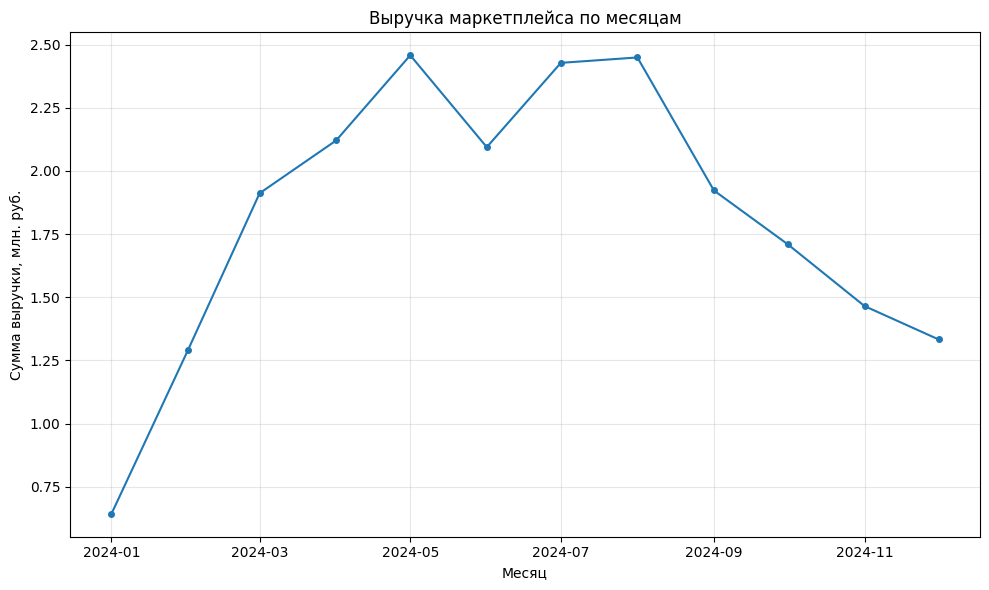

In [19]:
df_orders['revenue'] = df_orders['total_price'] * 0.05
monthly_revenue = df_orders.groupby('order_month')['revenue'].sum().rename('monthly_revenue')

plt.figure(figsize=(10, 6))
plt.plot(monthly_revenue.index, monthly_revenue.values/1e6, marker='o', ms=4) # значения переведены в миллионы руб. для удобного чтения графика
plt.title('Выручка маркетплейса по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Сумма выручки, млн. руб.')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Выручка - ключевая метрика бизнеса - прошла пик в середине года и снижается.** Комиссионная выручка (5% от оборота) растет в первом полугодии с пиком в мае (~ 2,46 млн руб), после локального провала в июне выходит на второе плато в июле-августе, а затем устойчиво снижается к декабрю до ~1,33 млн руб - около -45% от майского пика. Второе полугодие не формирует нового пика - августовское плато не превышает майского уровня.

Таким образом, продукт завершает год со снижающейся выручкой.

#### Вовлеченность пользователей

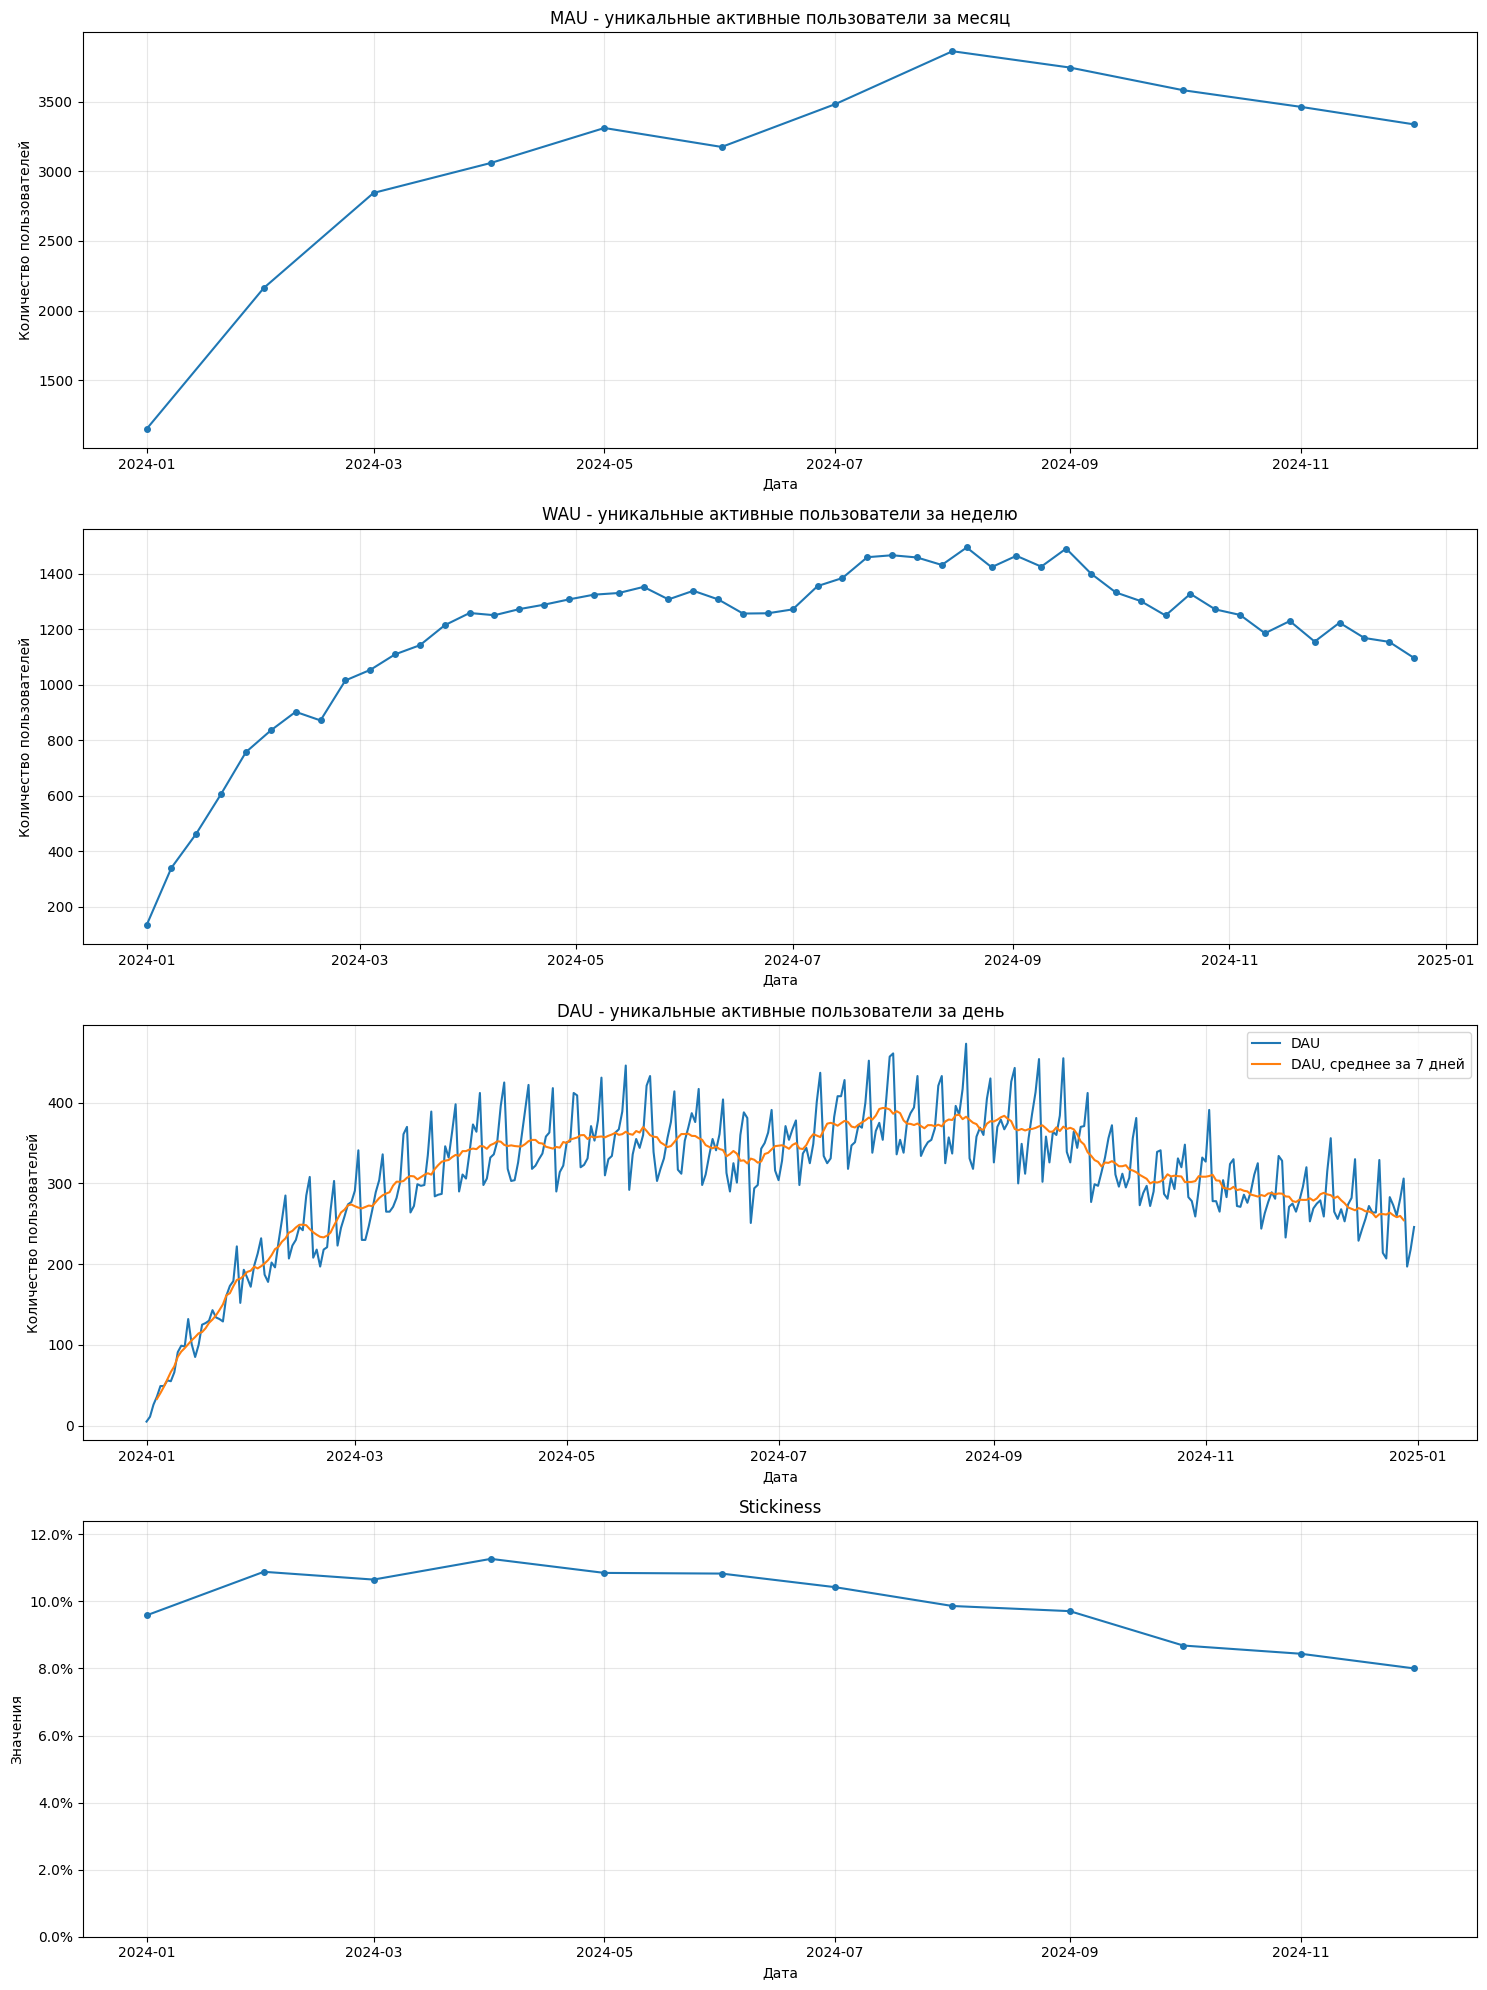

In [20]:
mau = df_events.groupby('event_month')['user_id'].nunique().reset_index(name='mau')
wau = df_events.groupby('event_week')['user_id'].nunique().reset_index(name='wau')
dau = df_events.groupby('event_date')['user_id'].nunique().reset_index(name='dau')
dau['event_month'] = dau['event_date'].dt.to_period('M').dt.to_timestamp()
dau_monthly_average = dau.groupby('event_month')['dau'].mean().reset_index(name='dau_monthly_average')
stickiness_table = pd.merge(dau_monthly_average, mau, on='event_month')
stickiness_table['stick'] = 100*(stickiness_table['dau_monthly_average'] / stickiness_table['mau'])

fig, axes = plt.subplots(4, 1, figsize=(15, 20))

# mau
axes[0].plot(mau['event_month'], mau['mau'], marker='o', ms=4)
axes[0].set_title('MAU - уникальные активные пользователи за месяц')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Количество пользователей')

# wau
wau_plot = wau.iloc[:-1] # отрезаем последнюю неполную неделю
axes[1].plot(wau_plot['event_week'], wau_plot['wau'], marker='o', ms=4)
axes[1].set_title('WAU - уникальные активные пользователи за неделю')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Количество пользователей')

# dau
axes[2].plot(dau['event_date'], dau['dau'], label='DAU')
axes[2].plot(dau['event_date'], dau['dau'].rolling(7, center=True).mean(), label='DAU, среднее за 7 дней')
axes[2].set_title('DAU - уникальные активные пользователи за день')
axes[2].set_xlabel('Дата')
axes[2].set_ylabel('Количество пользователей')
axes[2].legend()

# stickiness
axes[3].plot(stickiness_table['event_month'], stickiness_table['stick'], marker='o', ms=4)
axes[3].set_title('Stickiness')
axes[3].set_xlabel('Дата')
axes[3].set_ylabel('Значения')
axes[3].yaxis.set_major_formatter(PercentFormatter(100))
axes[3].set_ylim(0, stickiness_table['stick'].max()*1.1)


for ax in axes:
    ax.grid(alpha=0.3)
    
plt.tight_layout()
plt.show()

**MAU разворачивается в августе.** Рост до ~ 3800 в августе, дальше монотонное снижение до ~ 3300 в декабре. Это около -13% от пика за четыре месяца. WAU и DAU (по скользящему среднему) повторяют форму: пик в конце августа (~ 1500 и ~390), к декабрю ~ 1100 и ~ 250

В DAU отчетливо выражена недельная сезонность, поэтому показатель следует читать по скользящему среднему за 7 дней, а не по отдельным дням. Последняя неделя декабря содержит только два календарных дня и из графика WAU исключена.

**Вовлеченность снижается с апреля** - раньше, чем размер аудитории. Stickiness (DAU/MAU) растет до 11,3% в апреле, после чего устойчиво снижается до 8,0% в декабре

#### Удержание пользователей
Прежде чем оценивать удержание, нужно понять, какая часть зарегистрированных пользователей вообще доходит до продукта. Регистрация в витрине событий не логируется - среди пятнадцати типов событий отсутствует создание аккаунта, а факт регистрации поступает из витрины `users` как свершившийся. Поэтому попадание в когорту не порождает записи в `events`, и пользователь, не совершивший ни одного действия, в таблице событий просто отсутствует.

Это означает, что нулевой период когортной матрицы не будет равен 100% по построению. Чтобы корректно интерпретировать ее значения, требуется знать долю активировавшихся: без нее невозможно отделить потери на входе в продукт от последующего оттока.


In [21]:
events_reg = pd.merge(df_events[['user_id', 'event_date']],
    df_users[['user_id', 'registration_date', 'cohort_month']],
    on='user_id', how='left')
display(f"событий без данных о регистрации: {events_reg['registration_date'].isna().sum()}")
events_reg = events_reg.dropna(subset=['registration_date'])

activated = events_reg['user_id'].nunique()
display(f"активировались хотя бы раз: {activated} из {len(df_users)} "
        f"({activated / len(df_users):.1%})")

'событий без данных о регистрации: 34933'

'активировались хотя бы раз: 21602 из 44151 (48.9%)'

Доля зарегистрированных, совершивших хотя бы одно действие за весь период наблюдения (48.9%), задает верхнюю границу для всей когортной матрицы: удержание не может превысить активацию.

'Матрица Retention Rate:'

n_period,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,0.369179,0.369179,0.177219,0.081742,0.041206,0.018425,0.008710,0.004020,0.000335,0.000670,0.000335,0.000335
2024-02,0.360384,0.405017,0.178901,0.090373,0.047215,0.018443,0.008853,0.003689,0.001107,0.000369,0.000738,NaN
2024-03,0.379764,0.376054,0.191568,0.092749,0.042833,0.020911,0.008094,0.002698,0.000675,0.000675,NaN,NaN
2024-04,0.384509,0.393115,0.193804,0.093632,0.048193,0.022719,0.010671,0.006885,0.003098,NaN,NaN,NaN
2024-05,0.372472,0.369211,0.171885,0.077299,0.036204,0.016308,0.004566,0.002283,NaN,NaN,NaN,NaN
2024-06,0.334875,0.343060,0.170107,0.076157,0.037722,0.017794,0.005338,NaN,NaN,NaN,NaN,NaN
2024-07,0.319964,0.327484,0.148815,0.070875,0.035552,0.012762,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,0.310991,0.301738,0.141954,0.074475,0.032724,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,0.275414,0.285266,0.139498,0.057098,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


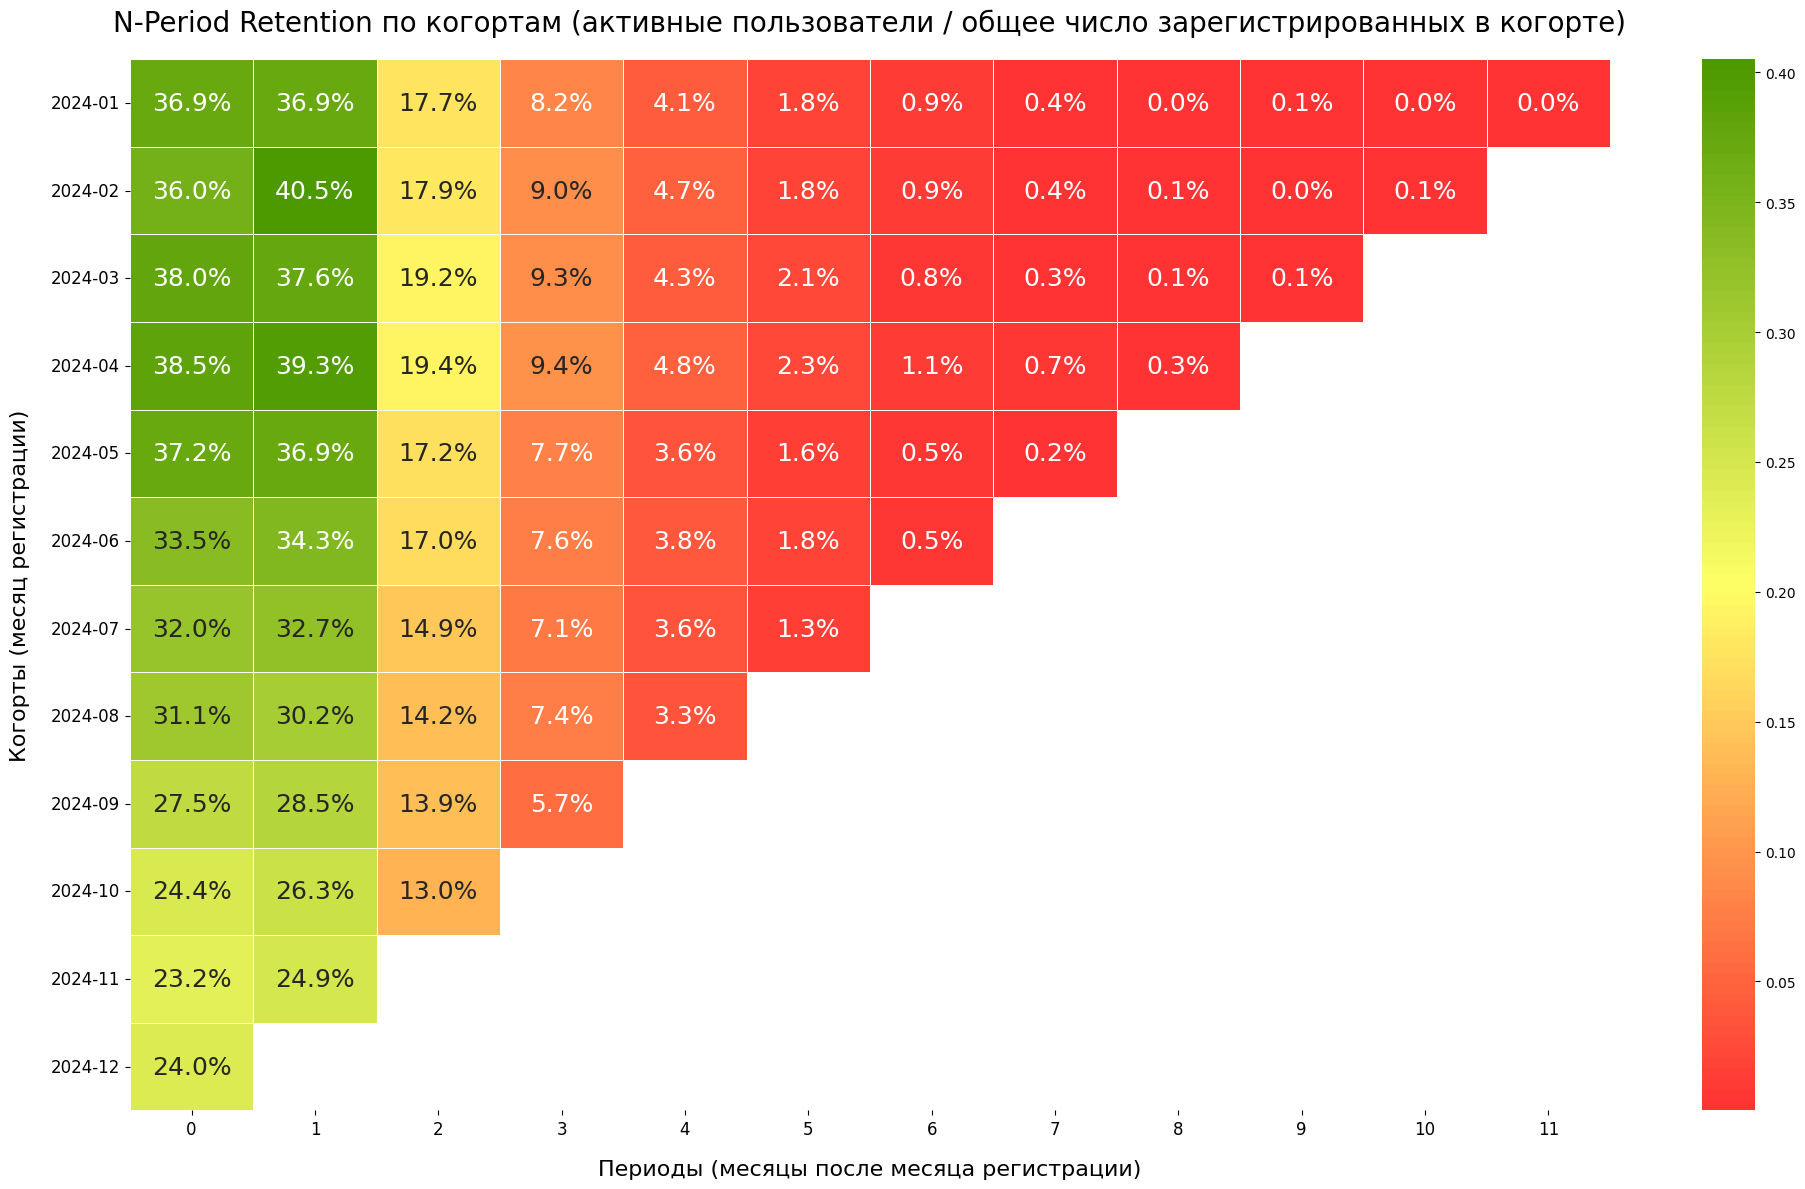

In [22]:
events_reg['n_period'] = events_reg['event_date'].dt.to_period('M').astype('int64') - events_reg['registration_date'].dt.to_period('M').astype('int64')
ret_pivot = pd.pivot_table(events_reg,
                           values='user_id',
                           index='cohort_month',
                           columns='n_period',
                           aggfunc='nunique'
                          )

cohort_size = df_users.groupby('cohort_month')['user_id'].nunique()
cohort_size.index = pd.to_datetime(cohort_size.index).strftime('%Y-%m')
ret_pivot.index = pd.to_datetime(ret_pivot.index).strftime('%Y-%m')
ret_pivot = ret_pivot.div(cohort_size, axis=0)                                                 

# Выводим результат
display("Матрица Retention Rate:")
display(ret_pivot)

# Создаем визуализацию
plt.subplots(figsize=(20, 12))
sns.heatmap(ret_pivot,
           cmap=cmap,
           annot=True,
           fmt='.1%',
           linewidth=0.5,
           annot_kws={"size": 18})

# Настройки графика
plt.title('N-Period Retention по когортам (активные пользователи / общее число зарегистрированных в когорте)', fontsize=20, pad=20)
plt.xlabel('Периоды (месяцы после месяца регистрации)', fontsize=16, labelpad=15)
plt.ylabel('Когорты (месяц регистрации)', fontsize=16, labelpad=15)
plt.yticks(rotation=0)
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

**Удержание падает от когорты к когорте начиная с июня.** Доля активных в месяце регистрации держится на уровне 36-38% с января по май, после чего монотонно снижается до 23-25% к концу года - сокращение примерно на треть. Та же динамика прослеживается в первом и втором периодах жизни, то есть поздние когорты слабее ранних на всем наблюдаемом горизонте, а не только на входе. 

Форма кривой удержания при этом одинакова у всех когорт: между первым и вторым периодом активная часть сокращается примерно вдвое, далее теряется около половины оставшихся ежемесячно. К шестому периоду активными остаются менее 1% когорты. Кривая не выходит на плато - устойчивого ядра постоянных пользователей в продукте не сформировалось.

Определяющим фактором является отсутствие активации как таковой: хотя бы одно событие за весь период наблюдения совершают 48.9% зарегистрированных. Потери на входе в продукт превышают все последующие потери от оттока.

Равенство значений в периодах 0 и 1 объясняется разной длиной окон: период 0 охватывает только остаток месяца регистрации, тогда как период 1 - полный месяц. Содержательным сигналом это не является.

#### Продуктовая воронка

In [23]:
# Функция для добавления подписи значений на столбцы
def add_bar_labels(ax, bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom')

,event_type,users,conversion_from_first_%,conversion_from_previous_%
0,page_view,22098,100.0,NaN
1,product_view,22069,99.9,99.9
2,product_click,21745,98.4,98.5
3,add_to_cart,20411,92.4,93.9
4,checkout_start,16769,75.9,82.2
5,checkout_complete,13897,62.9,82.9


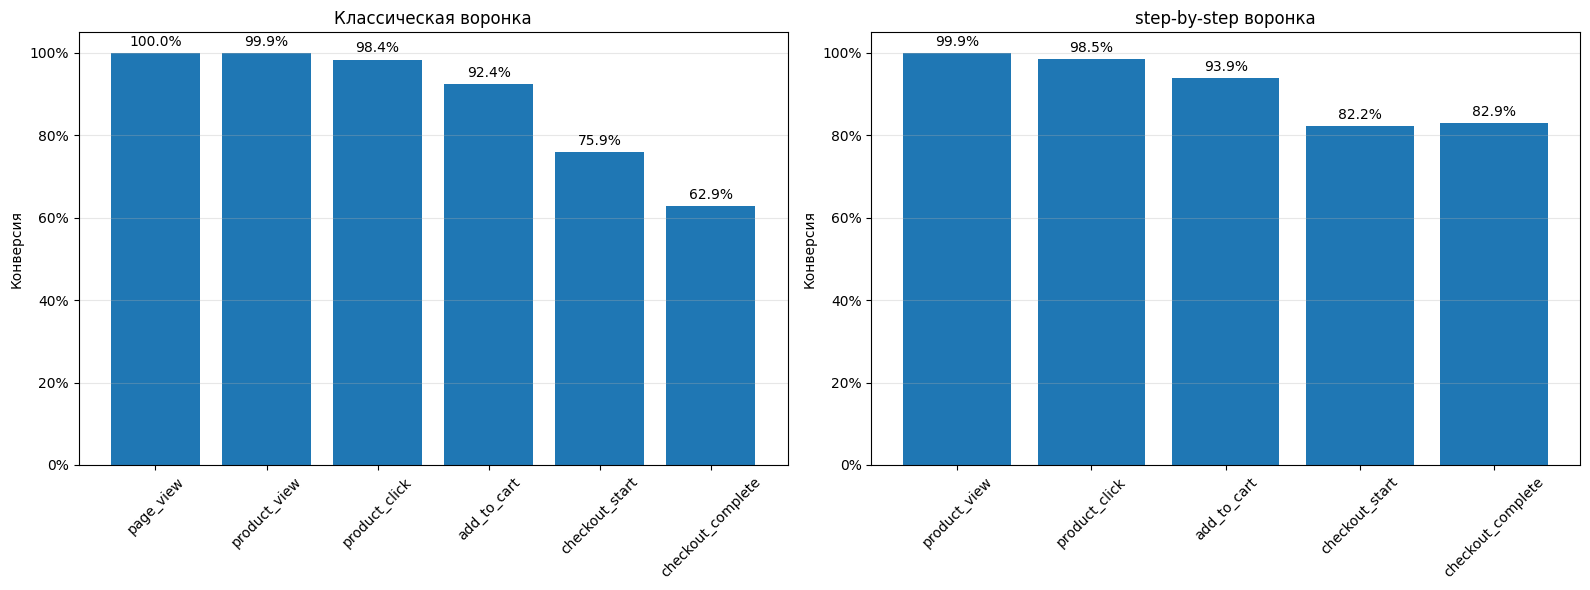

In [24]:
# Порядок шагов воронки
funnel_steps = ['page_view', 'product_view', 'product_click',
                'add_to_cart', 'checkout_start', 'checkout_complete']

# Число уникальных пользователей на каждом шаге
funnel_df = df_events[df_events['event_type'].isin(funnel_steps)].groupby('event_type')['user_id'].nunique().reindex(funnel_steps).reset_index(name='users')

# Добавляем конверсии
funnel_df['conversion_from_first_%'] = (funnel_df['users'] / funnel_df['users'].iloc[0] * 100).round(1)
funnel_df['conversion_from_previous_%'] = (funnel_df['users'] / funnel_df['users'].shift(1) * 100).round(1)

display(funnel_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Классическая воронка: 
bars1 = axes[0].bar(funnel_df['event_type'], funnel_df['conversion_from_first_%'])
axes[0].set_title('Классическая воронка')
axes[0].set_ylabel('Конверсия')
axes[0].set_ylim(0, 105)


# step-by-step воронка: 
bars2 = axes[1].bar(funnel_df['event_type'], funnel_df['conversion_from_previous_%'])
axes[1].set_title('step-by-step воронка')
axes[1].set_ylabel('Конверсия')
axes[1].set_ylim(0, 105)


# Поворачиваем подписи событий, переводим шкалу в % и добавляем сетку
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    
add_bar_labels(axes[0], bars1)
add_bar_labels(axes[1], bars2)
plt.tight_layout()
plt.show()

**Основные потери сосредоточены на этапе оформления.** Верхние переходы воронки (page_view -> product_view -> product_click -> add_to_cart) держатся выше 92%, однако эти значения отражают длину окна наблюдения: за год почти каждый активный пользователь хотя бы раз просматривает товары и добавляет их в корзину. Содержательны два нижних перехода: add_to_cart -> checkout_start (82,2%) и checkout_start -> checkout_complete (82,9%) - на каждом теряется около пятой части пользователей. Именно переход от корзины к оформлению и само оформление являются точками роста, тогда как верх воронки близок к насыщению.

#### Конверсия из регистрации в заказ

Прежде чем рассчитывать конверсионные метрики, определим, в каком временном окне пользователи совершают целевое действие после регистрации.

'событий без данных о регистрации: 898'

'заказов раньше регистрации: 0'

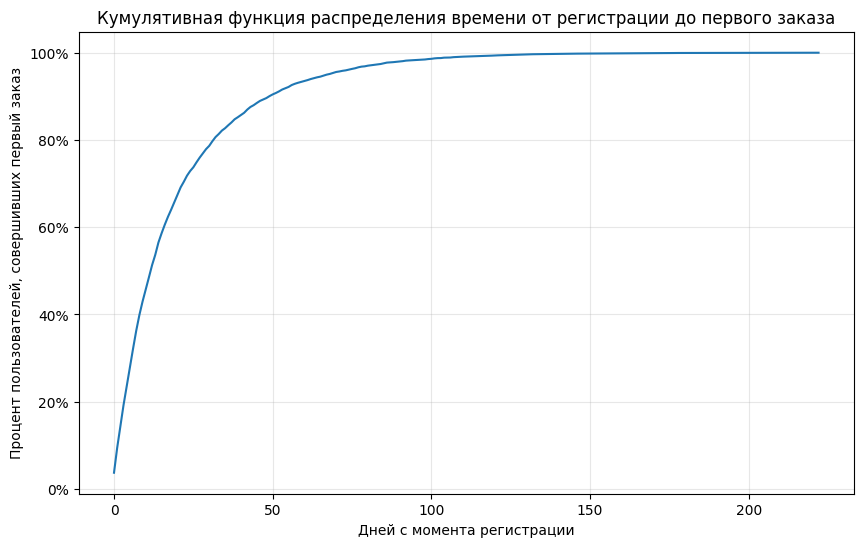

' CDF на 30 день:78.6,  на 60 день:93.5'

count    8654.0
mean       20.0
std        23.2
min         0.0
50%        12.0
80%        32.0
90%        49.0
95%        68.0
max       222.0
Name: diff_days, dtype: float64

In [25]:
orders_reg = df_orders.merge(df_users[['user_id','registration_date', 'cohort_month']], on='user_id', how='left')
display(f"событий без данных о регистрации: {orders_reg['registration_date'].isna().sum()}")
orders_reg = orders_reg.dropna(subset=['registration_date'])

first_orders = orders_reg.groupby(['user_id', 'registration_date', 'cohort_month'], as_index=False)['order_date'].min()
first_orders['diff_days'] = (first_orders['order_date'].dt.to_period('D').astype('int64') - 
                             first_orders['registration_date'].dt.to_period('D').astype('int64'))

display(f"заказов раньше регистрации: {(first_orders['diff_days'] < 0).sum()}")
first_orders = first_orders[first_orders['diff_days'] >= 0]  # оставляем только положительные разницы

#строим кумулятивную функцию распределения CDF
days = sorted(first_orders['diff_days'].unique())
percentiles = [ (first_orders[first_orders['diff_days'] <= day].shape[0] / first_orders.shape[0]) * 100 for day in days ]


# визуализация CDF
plt.figure(figsize=(10,6))
plt.plot(days, percentiles)
plt.title('Кумулятивная функция распределения времени от регистрации до первого заказа')
plt.xlabel('Дней с момента регистрации')
plt.ylabel('Процент пользователей, совершивших первый заказ')
plt.grid(alpha=0.3)
plt.gca().yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

display(f" CDF на 30 день:{percentiles[30]:.1f},  на 60 день:{percentiles[60]:.1f}")
display(first_orders['diff_days'].describe(percentiles=[.5, .8, .9, .95]).round(1))


78.6% пользователей, совершивших ключевое действие, уложились в 30 дней, а к 60 дню уже 93.5%

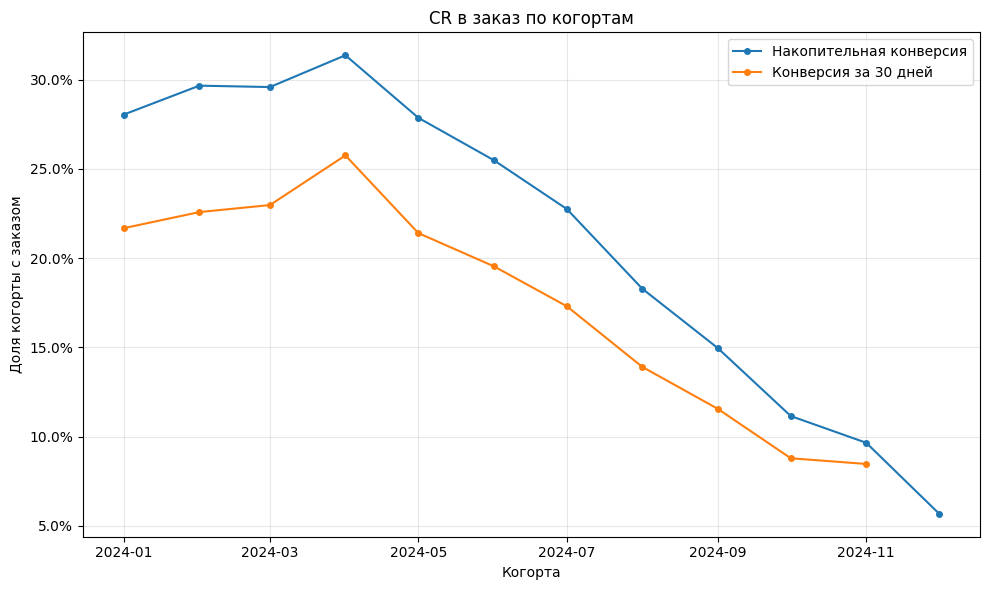

,cr_to_order,cr_30d
cohort_month,,
2024-01-01,28.0,21.7
2024-02-01,29.7,22.6
2024-03-01,29.6,23.0
2024-04-01,31.4,25.7
2024-05-01,27.9,21.4
2024-06-01,25.5,19.5
2024-07-01,22.7,17.3
2024-08-01,18.3,13.9
2024-09-01,15.0,11.6


In [26]:
# Накопительная конверсия (поздние когорты с заниженными результатами из-за малой продолжительности наблюдений для них)
buyers_by_cohort = orders_reg.groupby('cohort_month')['user_id'].nunique()
cohort_size = df_users.groupby('cohort_month')['user_id'].nunique()
cr_cohort = (buyers_by_cohort / cohort_size).rename('cr_to_order')
# Конверсия за 30 дней
cr_30d = (first_orders[first_orders['diff_days'] <= 30]
          .groupby('cohort_month')['user_id'].nunique()
          / cohort_size).rename('cr_30d')

plt.figure(figsize=(10, 6))
plt.plot(cr_cohort.index, cr_cohort.values, label='Накопительная конверсия', marker='o', ms=4) 
plt.plot(cr_30d.index[:-1], cr_30d.values[:-1], label='Конверсия за 30 дней', marker='o', ms=4) # без декабрьской когорты, т.к. ее срок жизни меньше 30 дней
plt.title('CR в заказ по когортам')
plt.xlabel('Когорта')
plt.ylabel('Доля когорты с заказом')
plt.grid(alpha=0.3)
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.legend()
plt.show()


df_cr = pd.concat([cr_cohort, cr_30d], axis=1)
display((df_cr * 100).round(1))

**Конверсия в заказ снижается от когорты к когорте.** Накопительная доля когорты, совершившей заказ, падает с ~30% (январь-апрель) до значений ниже 10% у поздних когорт. Часть этого падения у последних когорт вызвана правой цензурой - они наблюдались меньше времени. Чтобы отделить цензуру от реальной динамики, конверсия пересчитана на сопоставимом окне в 30 дней после регистрации (окно выбрано по CDF времени до первого заказа: в 30 дней укладывается 78,6% первых покупок).

На сопоставимом окне падение сохраняется: с 25,7% у апрельской когорты до 13,9% у августовской - это когорты с полными данными. Следовательно, снижение конверсии реально, а не является артефактом наблюдения.

### Промежуточный вывод: здоровье и активность

**Ключевая метрика - комиссионная выручка** - прошла пик в мае и снизилась к декабрю почти вдвое от пика. За этим стоит не одна причина, а согласованное ухудшение нескольких драйверов, проявившееся в течение года.

Метрики первого уровня рассматривались в порядке приоритета - от вовлеченности к удержанию и конверсии. Все три указывают на общую причину.

**Активность растет до середины года, затем разворачивается.** MAU увеличивается до августа, после чего снижается примерно на 13% к декабрю. WAU и DAU повторяют форму. Сам по себе рост абсолютной аудитории не является достаточным признаком здоровья: его источник разбирается ниже через удержание когорт

**Вовлеченность подает сигнал на четыре месяца раньше размера аудитории.** Stickiness (DAU/MAU) разворачивается уже в апреле - с 11,3% до 8,0% к декабрю. Это ведущий индикатор: каждый активный пользователь заходит реже задолго до того, как это станет заметно по абсолютному MAU.

**Удержание падает от когорты к когорте начиная с июня.** Доля активных в месяце регистрации держится на 36-38% с января по май, затем снижается до 23-25% - на треть. Падение видно во всех периодах жизни когорты, а не только на входе: поздние когорты объективно слабее ранних. При этом форма кривой удержания у всех когорт одинакова, то есть изменился не продукт, а качество приходящих пользователей. Устойчивого ядра постоянных пользователей не сформировалось - кривая удержания не выходит на плато.

**Конверсия в заказ снижается синхронно с удержанием.** Накопительная конверсия когорты падает с ~30% до значений ниже 10%, но часть этого спада у поздних когорт вызвана правой цензурой. На сопоставимом окне в 30 дней (в него укладывается 78,6% первых заказов) падение сохраняется - с 25,7% у апрельской когорты до 13,9% у августовской. Это когорты с полными данными, поэтому снижение реально, а не артефакт наблюдения.

**Узкое место в воронке - оформление заказа.** Верх продуктовой воронки близок к насыщению, но два нижних перехода теряют примерно по пятой части пользователей каждый: add_to_cart -> checkout_start (82%) и checkout_start -> checkout_complete (83%). Это единственная точка воронки, где потери поддаются продуктовой оптимизации.

**Отдельная проблема - активация.** Хотя бы одно действие совершают лишь 48,9% зарегистрированных. Потери на входе в продукт превышают все последующие потери от оттока: половина привлеченных не доходит до продукта ни разу.

**Общая картина.** Снижение выручки во втором полугодии согласовано с деградацией драйверов: вовлеченность слабеет с апреля, удержание и конверсия когорт - с июня, размер активной аудитории разворачивается в августе. Форма кривых удержания и конверсии одинакова у всех когорт, то есть менялся не продукт, а качество приходящих пользователей. Падение выручки - итоговое проявление этого процесса на уровне денег.

Что именно ухудшило качество поздних когорт, метрики уровня активности не показывают. Ответ требует анализа источников привлечения и их стоимости и выполняется на этапе монетизации.

## Оценка метрик монетизации и юнит-экономики

Сколько продукт зарабатывает с клиента и во сколько обходится его привлечение.

### Метрики монетизации

#### ARPPU - выручка на платящего пользователя

,revenue,payers,arppu
order_month,,,
2024-01-01,642661.0,454,1416.0
2024-02-01,1291004.0,839,1539.0
2024-03-01,1911340.0,1165,1641.0
2024-04-01,2120328.0,1324,1601.0
2024-05-01,2457460.0,1404,1750.0
2024-06-01,2093764.0,1230,1702.0
2024-07-01,2427411.0,1385,1753.0
2024-08-01,2448760.0,1385,1768.0
2024-09-01,1922230.0,1163,1653.0


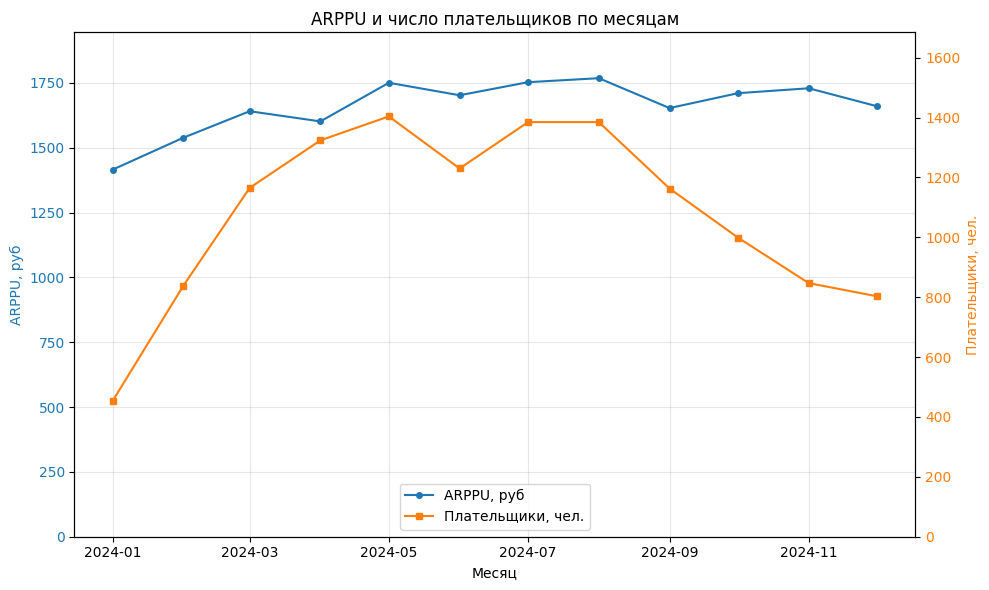

In [27]:
arppu = df_orders.groupby('order_month').agg(
    revenue=('revenue', 'sum'),
    payers=('user_id', 'nunique'))
arppu['arppu'] = arppu['revenue'] / arppu['payers']
display(arppu.round(0))

fig, ax1 = plt.subplots(figsize=(10, 6))

# Левая ось ARPPU
l1, = ax1.plot(arppu.index, arppu['arppu'], marker='o', ms=4,
               color='tab:blue', label='ARPPU, руб')
ax1.set_ylabel('ARPPU, руб', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, arppu['arppu'].max()*1.1)
ax1.set_xlabel('Месяц')

# Правая ось: плательщики
ax2 = ax1.twinx()
l2, = ax2.plot(arppu.index, arppu['payers'], marker='s', ms=4,
               color='tab:orange', label='Плательщики, чел.')
ax2.set_ylabel('Плательщики, чел.', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax2.set_ylim(0, arppu['payers'].max()*1.2)

# Общая легенда из обеих осей 
ax1.legend(handles=[l1, l2], loc='lower center')

# Сетка только у левой оси 
ax1.grid(alpha=0.3)
ax2.grid(False)

plt.title('ARPPU и число плательщиков по месяцам')
plt.tight_layout()
plt.show()

**ARPPU растет в первом полугодии и стабилизируется на ~1 700 руб,** но это эффект состава базы, а не роста монетизации. Стабильный ARPPU на фоне сжимающейся вдвое базы плательщиков означает не улучшение, а асимметричный отток: уходят слабые плательщики, а активные с высоким чеком остаются, удерживая средний. Выручка на пользователя не растет даже при концентрации самых ценных клиентов.

#### AOV - средний чек

Заказы логируются построчно (см. предобработку): одна строка соответствует товарной позиции, а не заказу целиком. Заказ идентифицируется связкой `user_id` + `order_date`, поле `order_id` нумерует позиции.

Для расчета среднего чека позиции сворачиваются до уровня заказа.

count     18016.000000
mean      24223.799373
std       30898.944169
min         339.000000
1%          618.000000
25%        5938.620000
50%       13864.310000
75%       31015.582500
95%       81175.700000
99%      149901.081000
max      454042.390000
Name: order_sum, dtype: float64

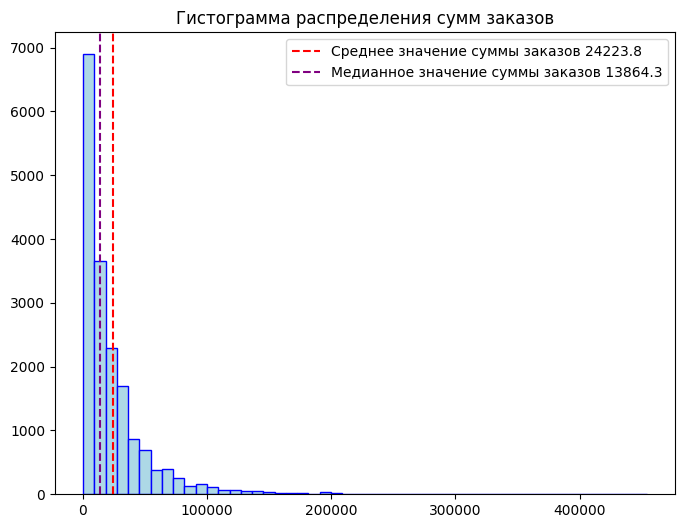

In [28]:
full_orders = df_orders.groupby(['user_id', 'order_date']).agg(order_quantity = ('quantity', 'sum'),
                                                               order_sum = ('total_price', 'sum'),
                                                               order_month = ('order_month', 'first')
).reset_index()
display(full_orders['order_sum'].describe(
    percentiles=[.01, .25, .5, .75, .95, .99]))

# Гистограмма распределения сумм заказов
plt.figure(figsize=(8, 6))
plt.hist(full_orders['order_sum'], bins=50, color='lightblue', edgecolor='blue')
plt.title('Гистограмма распределения сумм заказов')
plt.axvline(full_orders['order_sum'].mean(), color='red', ls='--', label=f"Среднее значение суммы заказов {full_orders['order_sum'].mean():.1f}")
plt.axvline(full_orders['order_sum'].median(), color='purple', ls='--', label=f"Медианное значение суммы заказов {full_orders['order_sum'].median():.1f}")
plt.legend()
plt.show()

Распределение сумм логических заказов сильно правостороннее: медиана 13,9 тыс. руб. при среднем 24,2 тыс., 95-й перцентиль 81 тыс., максимум 454 тыс. Средний чек завышен относительно типичного заказа за счет небольшого числа крупных покупок

,aov,items_per_order
order_month,,
2024-01-01,23075.8,3.4
2024-02-01,23240.4,3.4
2024-03-01,23758.1,3.5
2024-04-01,23022.0,3.4
2024-05-01,24319.2,3.4
2024-06-01,24066.3,3.5
2024-07-01,25089.5,3.5
2024-08-01,25494.6,3.5
2024-09-01,23968.0,3.4


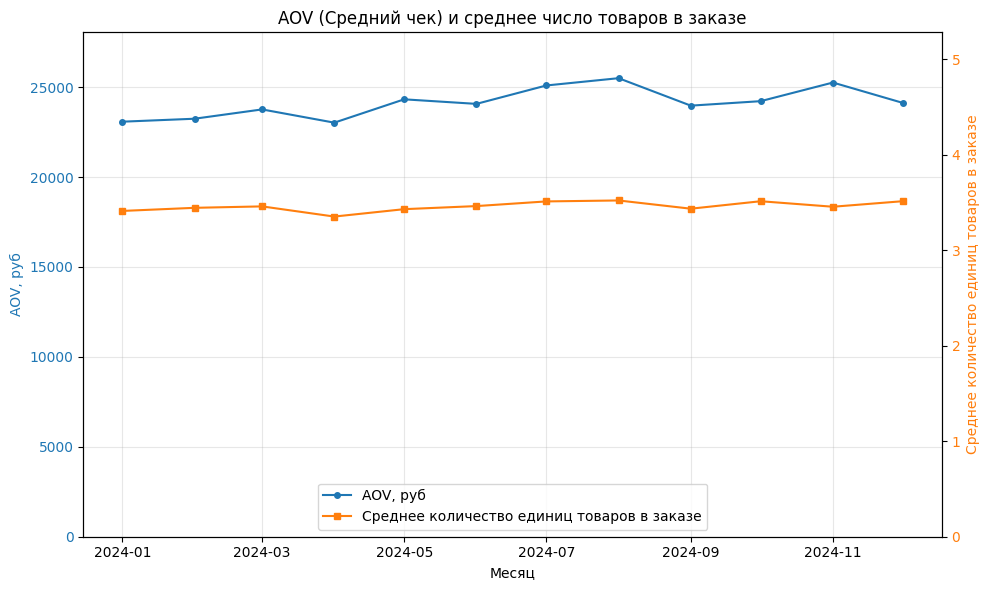

In [29]:
# Средний чек и среднее количество единиц товаров в заказе по месяцам
aov = full_orders.groupby('order_month').agg(aov=('order_sum', 'mean'),
                                             items_per_order=('order_quantity', 'mean'))
 
display(aov.round(1))

# Визуализация
fig, ax1 = plt.subplots(figsize=(10, 6))

# Левая ось: AOV
l1, = ax1.plot(aov.index, aov['aov'], marker='o', ms=4,
               color='tab:blue', label='AOV, руб')
ax1.set_ylabel('AOV, руб', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, aov['aov'].max()*1.1)
ax1.set_xlabel('Месяц')

# Правая ось: Среднее количество единиц товаров в заказе
ax2 = ax1.twinx()
l2, = ax2.plot(aov.index, aov['items_per_order'], marker='s', ms=4,
               color='tab:orange', label='Среднее количество единиц товаров в заказе')
ax2.set_ylabel('Среднее количество единиц товаров в заказе', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax2.set_ylim(0, aov['items_per_order'].max()*1.5)

# Общая легенда из обеих осей 
ax1.legend(handles=[l1, l2], loc='lower center')

# Сетка только у левой оси 
ax1.grid(alpha=0.3)
ax2.grid(False)

plt.title('AOV (Средний чек) и среднее число товаров в заказе')
plt.tight_layout()
plt.show()

Средний чек стабилен весь год (~24 тыс. руб), среднее количество единиц товара в заказе неизменно (3,4-3,5). Ни стоимость заказа, ни его наполнение не имеют выраженного тренда - экономика отдельной покупки за год не изменилась.

In [30]:
# Среднее число заказов на платящего пользователя
opp = full_orders.groupby('order_month').agg(
    orders=('user_id', 'count'),
    payers=('user_id', 'nunique'))
opp['orders_per_payer'] = opp['orders'] / opp['payers']
display(opp.round(2))

,orders,payers,orders_per_payer
order_month,,,
2024-01-01,557,454,1.23
2024-02-01,1111,839,1.32
2024-03-01,1609,1165,1.38
2024-04-01,1842,1324,1.39
2024-05-01,2021,1404,1.44
2024-06-01,1740,1230,1.41
2024-07-01,1935,1385,1.40
2024-08-01,1921,1385,1.39
2024-09-01,1604,1163,1.38


Частота заказов на плательщика стабильна: с февраля по декабрь держится на уровне 1,32-1,44 заказа в месяц. Пониженное значение января (1,23) приходится на первый месяц наблюдения с наименьшей базой плательщиков и на общий вывод не влияет.

#### Промежуточный вывод: монетизация

Метрики монетизации раскладывают ключевую метрику (выручку) на составляющие. Выручку логического заказа определяют три множителя: число плательщиков, частота их заказов и средний чек.

**Выручка за второе полугодие снизилась почти вдвое, и это падение целиком объясняется одним множителем - числом плательщиков.** Два других стабильны на всем периоде:

- **Средний чек** - ~ 24 тыс. руб (типичный заказ ниже - медиана ~14 тыс. руб, среднее завышено за счет небольшого числа крупных покупок), без тренда; среднее количество единиц в заказе неизменно (3,4-3,5).
- **Частота заказов на плательщика** - ~ 1,4 в месяц, без тренда.
- **Число плательщиков** - растет до апреля-августа (пик ~1 400), затем сокращается вдвое к декабрю (803).

**ARPPU (выручка на платящего) при этом обманчиво стабилен - ~ 1 700 руб во втором полугодии.** Это не признак здоровой монетизации, а следствие асимметричного оттока: продукт теряет прежде всего слабых плательщиков, а активные покупатели остаются, удерживая средний показатель. Расхождение видно на графике ARPPU и числа плательщиков - с сентября база сокращается, а ARPPU за ней не следует. Стабильный ARPPU на сжимающейся базе означает, что выручка на пользователя не растет даже при концентрации наиболее ценных клиентов.

**Вывод.** Экономика отдельной покупки за год не изменилась - ни чек, ни частота, ни наполнение заказа. Изменилось только число платящих клиентов. Продукт не потерял в способности зарабатывать с клиента - он потерял самих клиентов. Это переводит в деньги вывод предыдущего блока: деградация удержания и конверсии когорт сокращает приток активных пользователей, а вслед за ними - плательщиков и выручку. Причина снижения выручки лежит в удержании, а не в монетизации.

#### LTV, CAC, ROI

In [31]:
# Доля расходов на канал Direct, у которого нет атрибутированных пользователей в витрине users
direct = df_campaign_costs.loc[df_campaign_costs['acq_channel'] == 'Direct', 'budget'].sum()
total = df_campaign_costs['budget'].sum()
display(f"бюджет Direct: {direct:,.0f} ({direct/total:.1%} от общего)")

'бюджет Direct: 108,711 (0.6% от общего)'

,users,budget,revenue,cac,ltv,roi
2024-01-01,2985,1.165566e+06,2.096538e+06,390.474426,702.357716,0.798729
2024-02-01,2711,1.051718e+06,2.025392e+06,387.944504,747.101321,0.925794
2024-03-01,2965,1.158740e+06,2.449056e+06,390.806141,825.988445,1.113550
2024-04-01,2905,1.137992e+06,2.436117e+06,391.735726,838.594649,1.140715
2024-05-01,3066,1.217614e+06,2.235008e+06,397.134348,728.965532,0.835564
2024-06-01,2810,1.123561e+06,1.879207e+06,399.843749,668.756971,0.672546
2024-07-01,4388,1.767048e+06,2.466805e+06,402.700178,562.170699,0.396003
2024-08-01,4431,1.803680e+06,1.867090e+06,407.059325,421.369894,0.035156
2024-09-01,4466,1.811892e+06,1.438159e+06,405.708053,322.024066,-0.206267
2024-10-01,4440,1.804128e+06,1.098986e+06,406.335241,247.519447,-0.390849


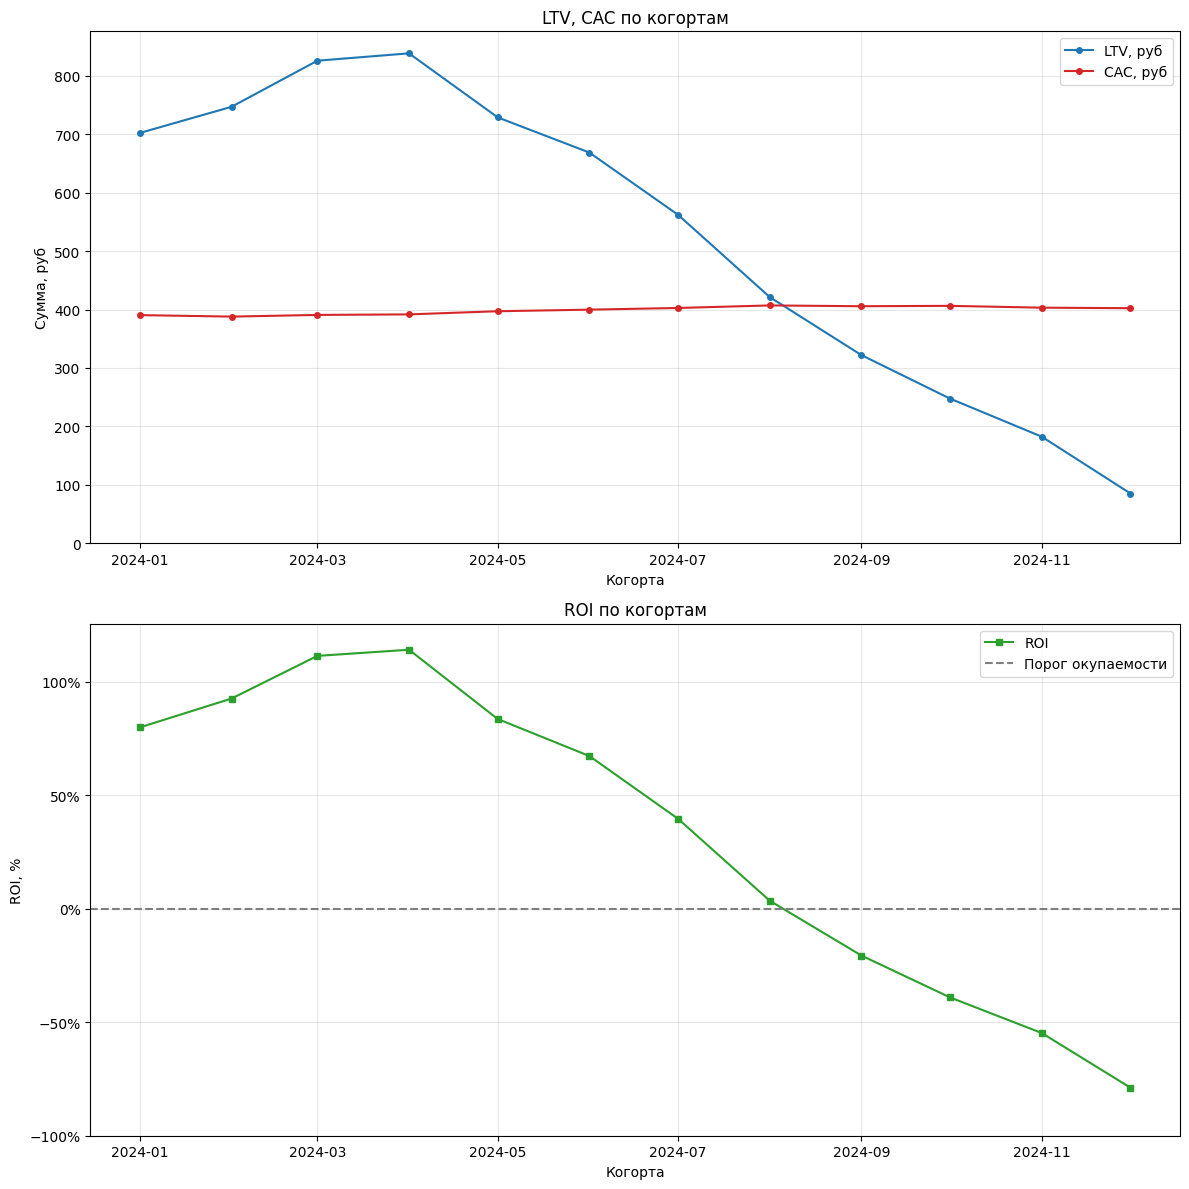

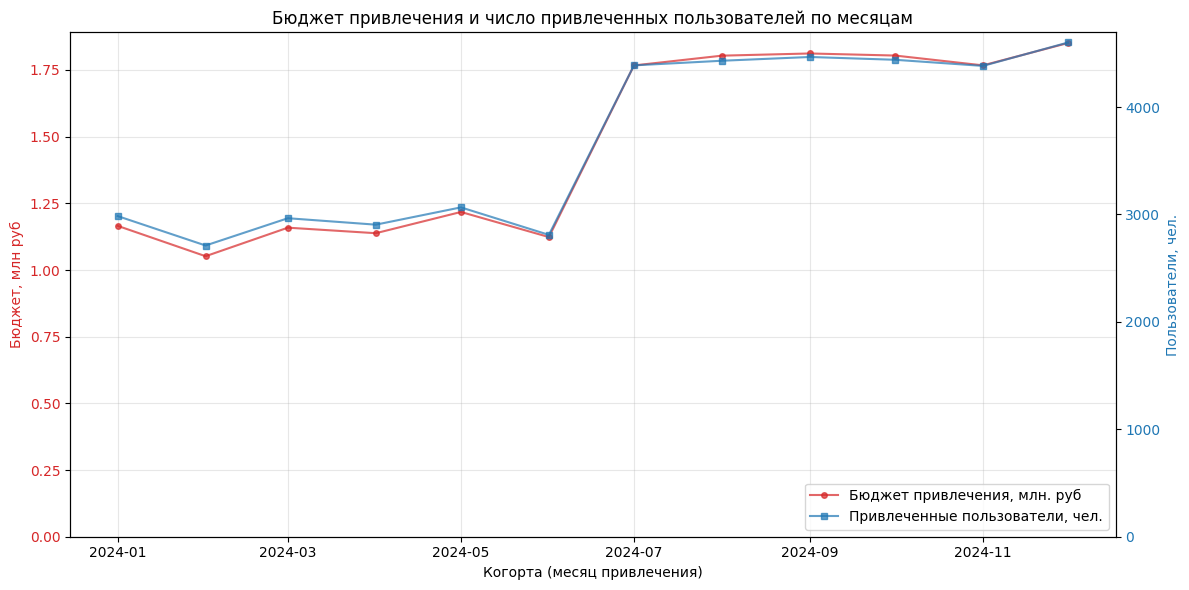

In [32]:
# Средний LTV (за весь период наблюдения), CAC и ROI по зарегистрированным пользователям по когортам
df_campaign_costs = df_campaign_costs[df_campaign_costs['spend_month'] < '2025-01-01']
cohort_size = df_users.groupby('cohort_month')['user_id'].nunique().rename('users')
budget = (df_campaign_costs[df_campaign_costs['acq_channel'] != 'Direct']
          .groupby('spend_month')['budget'].sum().rename('budget'))
revenue = orders_reg.groupby('cohort_month')['revenue'].sum().rename('revenue')
df_ltv_cac = pd.concat([cohort_size, budget, revenue], axis=1)
df_ltv_cac['cac'] = df_ltv_cac['budget'] / df_ltv_cac['users']       
df_ltv_cac['ltv'] = df_ltv_cac['revenue'] / df_ltv_cac['users']      
df_ltv_cac['roi'] = (df_ltv_cac['ltv'] - df_ltv_cac['cac']) / df_ltv_cac['cac']

display(df_ltv_cac)

# Визуализация
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

#LTV и CAC
axes[0].plot(df_ltv_cac.index, df_ltv_cac['ltv'], marker='o', ms=4,
               color='tab:blue', label='LTV, руб')
axes[0].plot(df_ltv_cac.index,df_ltv_cac['cac'], marker='o', ms=4,
               color='tab:red', label='CAC, руб')
axes[0].set_title('LTV, CAC по когортам')
axes[0].set_xlabel('Когорта')
axes[0].set_ylabel('Сумма, руб')
axes[0].grid(alpha=0.3)
axes[0].set_ylim(0, None)
axes[0].legend()

# ROI
axes[1].plot(df_ltv_cac.index, df_ltv_cac['roi'], marker='s', ms=4,
               color='tab:green', label='ROI')
axes[1].axhline(0, color='tab:grey', ls='--', label='Порог окупаемости')
axes[1].set_title('ROI по когортам')
axes[1].set_xlabel('Когорта')
axes[1].set_ylabel('ROI, %')
axes[1].grid(alpha=0.3)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_ylim(-1, df_ltv_cac['roi'].max()*1.1)
axes[1].legend()

plt.tight_layout()
plt.show()

# Размер бюджета и кол-во привлеченных пользователей
fig, ax1 = plt.subplots(figsize=(12, 6))

# Левая ось: бюджет
l1, = ax1.plot(df_ltv_cac.index, df_ltv_cac['budget']/1e6, marker='o', ms=4,
               color='tab:red', label='Бюджет привлечения, млн. руб', alpha=0.7)
ax1.set_ylabel('Бюджет, млн руб', color='tab:red')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_ylim(0, None)
ax1.set_xlabel('Когорта (месяц привлечения)')

# Правая ось: привлеченные пользователи
ax2 = ax1.twinx()
l2, = ax2.plot(df_ltv_cac.index, df_ltv_cac['users'], marker='s', ms=4,
               color='tab:blue', label='Привлеченные пользователи, чел.', alpha=0.7)
ax2.set_ylabel('Пользователи, чел.', color='tab:blue')
ax2.tick_params(axis='y', labelcolor='tab:blue')
ax2.set_ylim(0, None)

ax1.legend(handles=[l1, l2], loc='lower right')
ax1.grid(alpha=0.3)
ax2.grid(False)

plt.title('Бюджет привлечения и число привлеченных пользователей по месяцам')
plt.tight_layout()
plt.show()

**CAC не растет, а ROI падает целиком со стороны LTV.** Стоимость привлечения стабильна весь год (~ 390-405 руб): несмотря на кратный рост бюджета во втором полугодии, число привлеченных росло синхронно, поэтому цена привлеченного не изменилась. LTV при этом падает с ~840 руб (апрель) до ~85 руб (декабрь), и ROI переходит из плюса в минус между августом и сентябрем. Поскольку знаменатель (CAC) постоянен, все движение ROI определяется падением LTV - привлечение не подорожало, ухудшилось качество привлекаемых пользователей. Часть падения LTV у поздних когорт вызвана правой цензурой (они наблюдались меньше) - разделение реального спада и цензуры изучим на когортных тепловых картах ниже.

График бюджет/привлечение подтверждает механизм стабильности CAC: бюджет привлечения и число привлеченных пользователей растут строго синхронно - обе величины делают ступенчатый скачок в июле и далее удерживаются на повышенном уровне, двигаясь параллельно. Поскольку CAC есть отношение этих двух величин, их синхронный рост оставляет стоимость привлечения неизменной. Рост маркетинговых расходов во втором полугодии не привел к удорожанию привлеченного пользователя - он сопровождался пропорциональным ростом их числа.

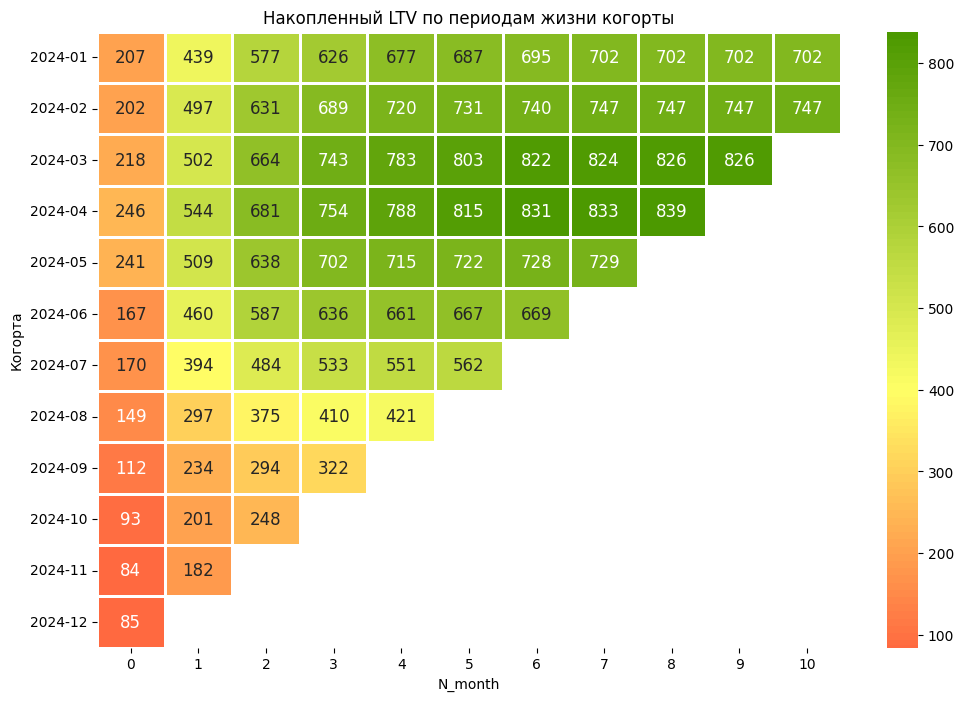

In [33]:
orders_reg['n_month'] = orders_reg['order_month'].dt.month - orders_reg['cohort_month'].dt.month
# помесячная выручка пользователя
mr = orders_reg.groupby(['user_id', 'cohort_month', 'n_month'])['revenue'].sum().reset_index()

# суммарная помесячная выручка когорты в каждом периоде (не накопленная)
cohort_monthly = mr.groupby(['cohort_month', 'n_month'])['revenue'].sum().unstack(fill_value=0)

# накопление по периодам на уровне когорты, затем делим на размер когорты
cohort_cum = cohort_monthly.cumsum(axis=1)                    
ltv_pivot = cohort_cum.div(cohort_size, axis=0)
ltv_pivot.index = pd.to_datetime(ltv_pivot.index).strftime('%Y-%m')

# для корректной отрисовки периодов для каждой когорты
max_month = orders_reg['n_month'].max()
for cohort in ltv_pivot.index:
    cohort_start = pd.Period(cohort, freq='M')
    available = (pd.Period('2024-12', freq='M') - cohort_start).n
    ltv_pivot.loc[cohort, ltv_pivot.columns > available] = float('nan')


plt.figure(figsize=(12, 8))
# Построим heatmap с серой палитрой
sns.heatmap(ltv_pivot,
           cmap=cmap,
           annot=True,
           center=400,
           fmt='.0f',
           linewidths=2,
           annot_kws={"size": 12})

# Заголовок и подписи осей
plt.title('Накопленный LTV по периодам жизни когорты')
plt.xlabel('N_month')
plt.ylabel('Когорта')
plt.show()

**Накопленный LTV по периодам жизни когорты.** Каждая строка монотонно растет и выходит на плато к 3-4 месяцу - после этого новых заказов почти нет. Сравнение когорт на сопоставимом окне (один и тот же период жизни, где цензура не влияет) показывает реальную деградацию: к третьему месяцу апрельская когорта накапливает ~ 750 руб, августовская  ~ 410 руб, почти вдвое меньше. Форма кривой накопления у всех когорт одинакова - меняется не скорость, а итоговый уровень. 

Центр цветовой шкалы установлен на уровне 400 руб - примерного среднего CAC по когортам. Ячейки зеленее центра соответствуют когортам, окупившим привлечение к данному периоду жизни, краснее - еще не окупившим. Точная окупаемость по каждой когорте (с ее индивидуальным CAC) показана на следующей тепловой карте ROI.

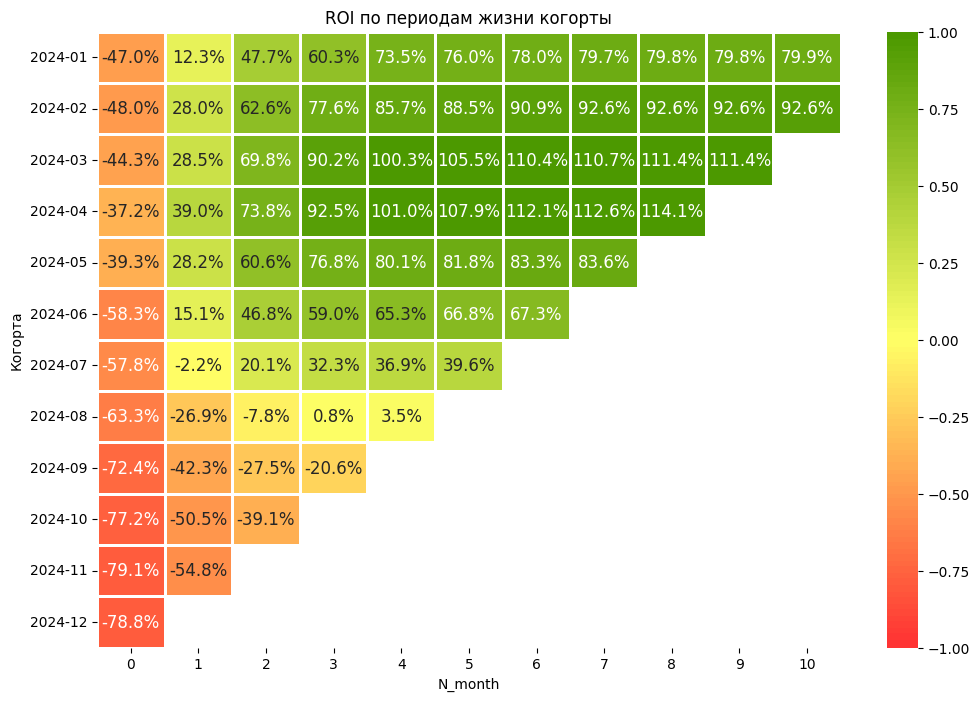

In [34]:
cac_by_cohort = df_ltv_cac['cac'].copy()
cac_by_cohort.index = df_ltv_cac.index.strftime('%Y-%m')

# ROI = (накопленный LTV - CAC) / CAC, CAC вычитается построчно
roi_pivot = ltv_pivot.sub(cac_by_cohort, axis=0).div(cac_by_cohort, axis=0)

plt.figure(figsize=(12, 8))
# Построим heatmap с серой палитрой
sns.heatmap(roi_pivot,
           cmap=cmap,
           annot=True,
           center=0,
           fmt='.1%',
           linewidths=2,
           vmin= -1,
           vmax= 1,
           annot_kws={"size": 12})

# Заголовок и подписи осей
plt.title('ROI по периодам жизни когорты')
plt.xlabel('N_month')
plt.ylabel('Когорта')
plt.show()

**Окупаемость по периодам жизни когорты.** Переход цвета из красного в зеленый - месяц окупаемости (Payback period). Ранние когорты (январь-май) окупаются за 1 месяц, июль за 2, август за 3, а когорты с сентября к концу наблюдения не окупились. Деградация видна и на сопоставимом окне: на первом месяце жизни ROI падает с +39% (апрель) до -42% (сентябрь). Для поздних когорт сделать вывод окупятся ли они за горизонтом данных, по имеющимся наблюдениям определить нельзя.

#### Промежуточный вывод: юнит-экономика

Юнит-экономика сопоставляет ценность привлеченного пользователя (LTV) со стоимостью его привлечения (CAC).

**Стоимость привлечения стабильна весь год - ~390-405 руб на пользователя.** Несмотря на кратный рост маркетингового бюджета во втором полугодии, число привлеченных росло синхронно с расходами, поэтому цена привлеченного не изменилась.

Окупаемость ухудшается с мая, а с сентября теряется полностью. Пик приходится на апрельскую когорту (ROI +114%), после чего окупаемость каждой следующей когорты монотонно снижается: май +84%, июнь +67%, июль +40%, август +3,5%. С сентября ROI уходит в минус - поздние когорты к концу наблюдения не окупились. При этом скорость окупаемости растягивается: ранние когорты окупались за 1 месяц, августовская - только за 3. Поскольку CAC постоянен, все падение определяется снижением LTV: привлечение не подорожало, ухудшилось качество привлекаемых пользователей.

**Снижение LTV реально, а не только следствие цензуры.** На сопоставимом окне (один и тот же месяц жизни) поздние когорты накапливают почти вдвое меньше ранних: к третьему месяцу апрельская когорта - ~750 руб, августовская - ~410 руб. При этом обрыв поздних когорт на правом крае тепловых карт - это недожитие: окупятся ли они за пределами наблюдения, по имеющимся данным определить нельзя.

**Вывод.** Продукт привлекает пользователей по стабильной цене, но каждая следующая когорта приносит меньше и окупается медленнее - а с сентября перестает окупаться вовсе. Это замыкает картину обзора: та же деградация качества когорт, что снижала удержание и конверсию, здесь проявляется в юнит-экономике - привлечение перестало окупаться не из-за роста затрат, а из-за падения отдачи.

### Выводы: здоровье продукта и юнит-экономика

#### **Главное**

Выручка прошла пик в мае и к декабрю снизилась почти вдвое. Это не разовый спад, а следствие одного процесса: **качество привлекаемых пользователей падает начиная со второго квартала, и к концу года привлечение перестает окупаться.** Продукт не потерял способность зарабатывать с клиента - он привлекает все более слабых клиентов.

#### **Что показывают метрики**

**Половина привлеченных не доходит до продукта.** Лишь 48,9% зарегистрированных совершают хотя бы одно действие - остальные не открывают продукт ни разу. Это потолок для всех последующих метрик: удержание и конверсия считаются от базы, половина которой неактивна изначально. Потери на входе крупнее, чем весь последующий отток вместе взятый.

**Выручку тянет вниз не экономика покупки, а потеря клиентов.** Средний чек (~24 тыс. руб; типичный заказ ниже - медиана ~14 тыс. руб, среднее завышено за счет небольшого числа крупных покупок), наполнение заказа и частота покупок стабильны весь год. Единственный меняющийся множитель - число плательщиков, которое во втором полугодии сократилось вдвое. Стабильный ARPPU при этом обманчив: он держится не потому, что монетизация улучшается, а потому что уходят слабые плательщики, а сильные остаются.

**Причина потери клиентов - деградация удержания и конверсии по когортам.** Удержание в месяце регистрации держалось на 36-38% до мая, затем снизилось до 23-25%. Конверсия в заказ на сопоставимом окне упала с ~26% (апрель) до ~14% (август). Поздние когорты слабее ранних на всем горизонте жизни, при неизменной форме кривых - то есть изменился не продукт, а пользователи.

**Ведущие индикаторы предупредили заранее.** Вовлеченность (stickiness) развернулась еще в апреле, качество когорт - с мая-июня, и лишь затем, в августе, развернулась активная аудитория и выручка. Метрики здоровья опередили падение денег на несколько месяцев.

**Привлечение не подорожало - упала отдача.** CAC стабилен весь год (~390-405 руб): бюджет рос, но число привлеченных росло синхронно. Окупаемость же ухудшается с каждой когортой - пик на апрельской (ROI +114%), далее спад, а с сентября когорты уходят в минус и к концу наблюдения не окупаются. Поскольку затраты постоянны, весь провал ROI идет со стороны ценности пользователя.

**Конкретная точка роста - оформление заказа.** Независимо от качества трафика, воронка теряет около пятой части пользователей на переходе от корзины к оформлению и столько же на самом оформлении. Это единственная потеря, устранимая улучшением продукта, а не каналов привлечения.

#### **Вывод для бизнеса**

Рост во втором полугодии был количественным, а не качественным: продукт масштабировал привлечение по стабильной цене, но приводил все менее ценных пользователей. Проблема лежит не в монетизации и не в стоимости привлечения, а в удержании и качестве привлекаемого трафика. При этом уже на входе теряется половина привлеченных - активация 48,9% ограничивает эффективность любых вложений в привлечение сверху. Ключевой вопрос для следующего блока - что именно в привлечении поставляет неактивных пользователей и слабые когорты. Это и определит точку приложения усилий.

#### **Оговорки к данным**

Выводы по поздним когортам (с сентября) ограничены правой цензурой - они наблюдались меньше, и часть падения LTV и ROI отражает недожитие, а не только деградацию. Сам факт ухудшения подтвержден на сопоставимых окнах, но окончательная окупаемость поздних когорт лежит за горизонтом наблюдения. Метрики в разрезе атрибутов пользователя считались по подмножеству с профилем; событийная и заказная витрины анализировались раздельно ввиду их независимости.

## Поиск инсайтов, точек роста и сегментация

Верхнеуровневый обзор показал, что выручка падает из-за деградации качества привлекаемых пользователей: поздние когорты хуже удерживаются, хуже конвертируются и не окупаются. Задача этого блока - локализовать источник деградации и сформировать обоснованные гипотезы:

- какие сегменты работают лучше, а какие хуже остальных;
- на каких этапах воронки теряются пользователи;
- какие группы можно масштабировать;
- куда стоит направить внимание и ресурсы.

**Принцип анализа - единица измерения определяет способ сегментации.** Атрибуты данных лежат на трех разных уровнях, и смешивать их нельзя:

- **Атрибуты пользователя** (`acq_channel`, `region`) - по одному на человека, в витрине `users`. Только по ним строится когортная сегментация: retention, конверсия и LTV по когортам привлечения. Отвечают на вопрос, какие сегменты работают лучше и хуже и что масштабировать.
- **Атрибут заказа** (`category_name`) - у каждого заказа свой. Анализируется по заказам и выручке (структура, концентрация, сдвиг ассортимента), но не как сегмент пользователей.
- **Атрибуты сессии** (`device`, `os`) - в `events`, один пользователь заходит с разных устройств. Анализируются только через воронку - отвечают на вопрос, где теряются пользователи.

Поле `buyer_segment` рассматривается отдельно: прежде чем использовать его как измерение, необходимо проверить его происхождение (ниже).

**План**

От важного к контрольным измерениям:

1. **Каналы привлечения** - когортная сегментация динамики привлечения, retention, конверсии и LTV. Основной кандидат: рост привлечения во втором полугодии пришелся преимущественно на один канал, что совпадает по времени с началом деградации когорт.
2. **Регионы** - те же метрики, контрольное измерение: не связано ли ухудшение с географией.
3. **Категории товаров** - структура и концентрация выручки, сдвиг ассортимента у поздних когорт.
4. **Устройства и ОС** - воронка по типам устройств: где теряются пользователи.

Для когортных измерений (1-2) метрики считаются на фиксированном окне и по когортам привлечения, а не по календарным месяцам, чтобы отделить качество привлеченных от эффекта изменения их числа во времени.

Итог блока - аналитическая записка с выводами и гипотезами о том, какие группы масштабировать, какие сворачивать и куда направить ресурсы.

In [35]:
# Если buyer_segment производен от заказов - он должен монотонно связываться с их числом
seg_orders = df_orders.groupby('user_id').size().reset_index(name='n_orders')
seg_orders = pd.merge(seg_orders, df_users[['user_id', 'buyer_segment']], on='user_id', how = 'left')
display(seg_orders.groupby('buyer_segment')['n_orders'].describe())

,count,mean,std,min,25%,50%,75%,max
buyer_segment,,,,,,,,
medium,3692.0,2.029794,1.485660,1.0,1.0,1.0,3.0,17.0
one_time,258.0,1.333333,0.692745,1.0,1.0,1.0,1.0,4.0
rare,988.0,1.517206,0.921821,1.0,1.0,1.0,2.0,7.0
regular,3716.0,5.611410,5.503966,1.0,2.0,4.0,7.0,63.0


Проверка показала, что поле `buyer_segment` коррелирует с покупательской активностью (среднее число заказов растет от one_time к regular), но не является ее однозначной функцией: диапазоны числа заказов у сегментов пересекаются (в каждую категорию, включая regular, попадают пользователи с одним заказом). Правило присвоения сегмента неизвестно и не сводится к покупательской активности, которая измеряется напрямую. Поэтому `buyer_segment` как измерение сегментации не используется - покупательская активность анализируется через число и частоту заказов.

### Сегментация по каналам привлечения

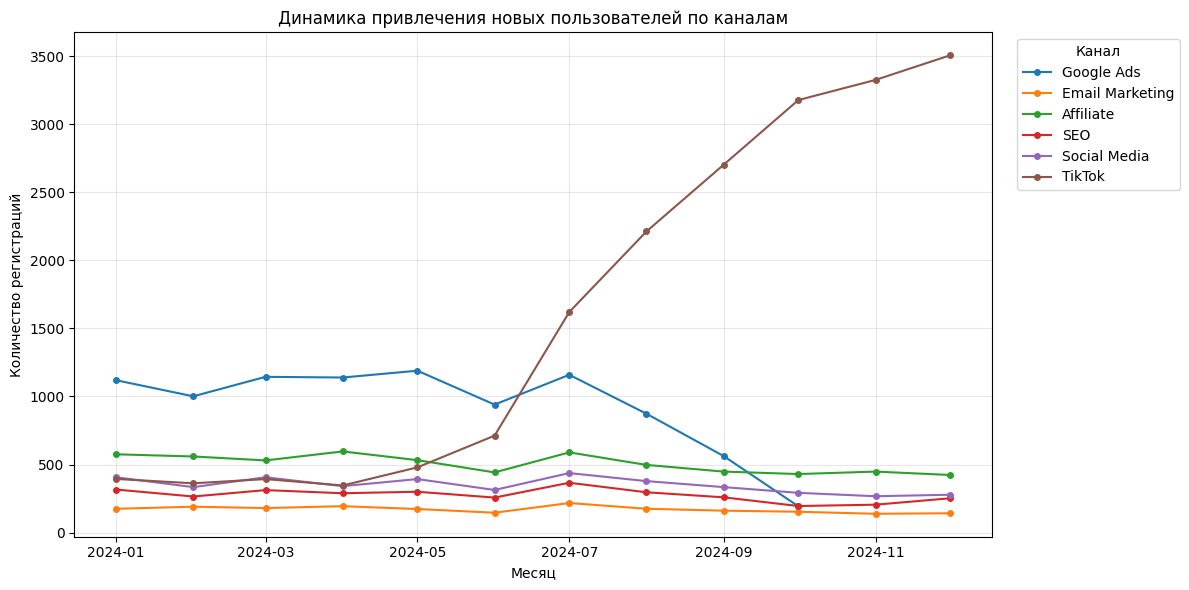

In [36]:
channels = df_users['acq_channel'].unique()
new_users_by_channel = df_users.groupby(['acq_channel', 'cohort_month'])['user_id'].nunique().reset_index(name='new_users')

plt.figure(figsize=(12, 6))
for c in channels:
    df_plot = new_users_by_channel[new_users_by_channel['acq_channel'] == c]
    plt.plot(df_plot['cohort_month'], df_plot['new_users'], marker='o', ms=4, label = c) 
plt.title('Динамика привлечения новых пользователей по каналам')
plt.xlabel('Месяц')
plt.ylabel('Количество регистраций')
plt.legend(title='Канал', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Структура привлечения резко изменилась в середине года.** До июня каналы распределены сравнительно равномерно: Google Ads - крупнейший (~ 1100 регистраций в месяц), TikTok - один из младших (~ 300-400, наравне с SEO и Social Media). С июля структура переламывается: привлечение через TikTok растет вертикально (с ~ 700 в июне до ~ 3500 в декабре), а Google Ads сворачивается с сентября и в ноябре-декабре не дает ни одной регистрации (в этих месяцах канал отсутствует в данных, поскольку привлечение через него прекращено). Остальные каналы (SEO, Affiliate, Email Marketing, Social Media) остаются стабильными весь год.

Таким образом, во втором полугодии произошел не пропорциональный рост привлечения, а замена структуры: крупнейший канал (Google Ads) выключен, а основной объем переведен на TikTok. К декабрю TikTok обеспечивает более трех четвертей всех регистраций против одной седьмой в начале года. Как этот сдвиг сказался на качестве привлеченных пользователей посмотрим в следующих разрезах.

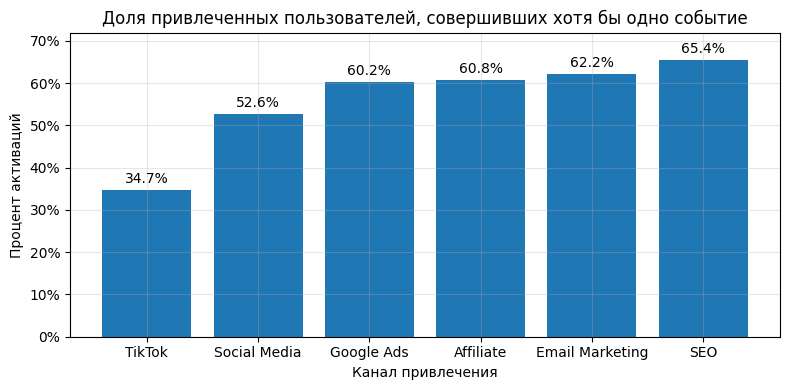

In [37]:
# активация по каналам: доля привлеченных, совершивших хотя бы одно событие
activated = (df_events.merge(df_users[['user_id','acq_channel']], on='user_id', how='inner')
             .groupby('acq_channel')['user_id'].nunique())
attracted = df_users.groupby('acq_channel')['user_id'].nunique()
activation = (activated / attracted).sort_values()

plt.figure(figsize=(8, 4))
bars = plt.bar(activation.index, activation.values*100)
plt.title('Доля привлеченных пользователей, совершивших хотя бы одно событие')
plt.ylabel('Процент активаций')
plt.xlabel('Канал привлечения')
plt.grid(alpha=0.3)
plt.gca().yaxis.set_major_formatter(PercentFormatter(100))
add_bar_labels(plt.gca(), bars)
plt.ylim(0, activation.values.max()*110)
plt.tight_layout()
plt.show()

**TikTok проваливает уже первый шаг - активацию.** Доля привлеченных, совершивших хотя бы одно действие, резко расслаивает каналы: TikTok активирует лишь 34,7% - почти вдвое ниже лучших каналов (SEO 65,4%, Email Marketing 62,2%, Affiliate 60,8%, Google Ads 60,2%) и заметно ниже ближайшего (Social Media 52,6%). Из привлеченных через TikTok две трети не открывают продукт ни разу.

Это объясняет низкий общий уровень активации по продукту (48,9%): показатель придавлен именно TikTok. Качественные каналы активируют 60-65% привлеченных, и общая цифра ниже только потому, что значительную долю привлечения составляет TikTok с его 35%.


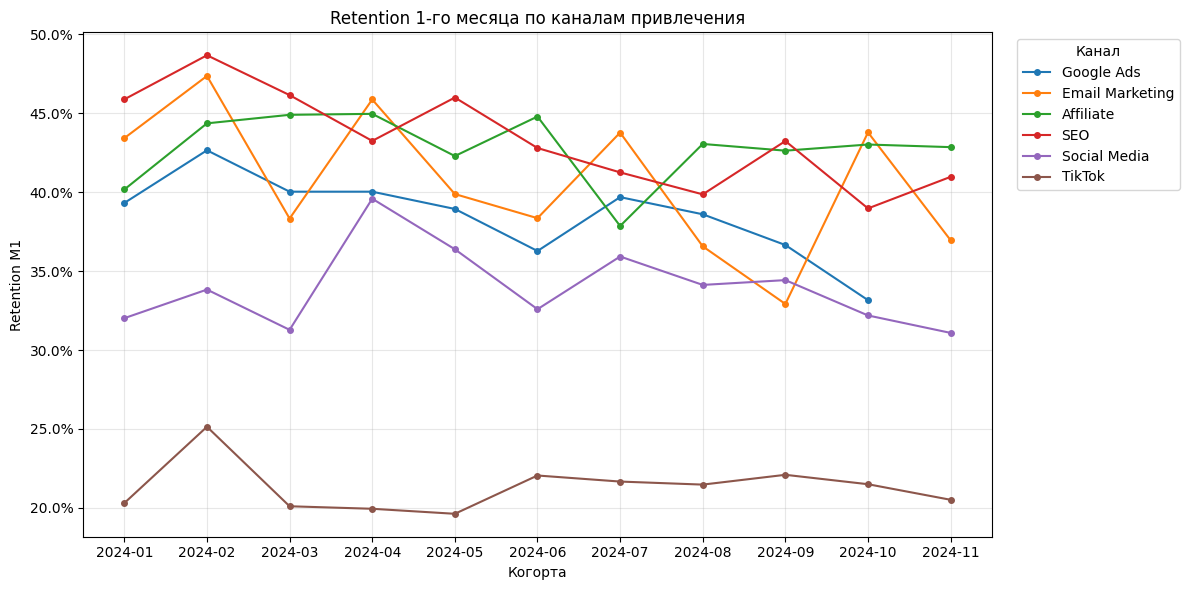

In [38]:
events_atr = df_events.merge(
    df_users[['user_id', 'registration_date', 'cohort_month', 'acq_channel']],
    on='user_id', how='inner')  # inner: только пользователи с профилем (у сирот нет канала)

events_atr['n_month'] = ((events_atr['event_date'].dt.to_period('M').astype('int64')
                      - events_atr['registration_date'].dt.to_period('M').astype('int64')))

# Вернувшиеся на первом месяце (n_month == 1)
m1 = (events_atr[events_atr['n_month'] == 1]
      .groupby(['cohort_month', 'acq_channel'])['user_id'].nunique())

# Размер когорт в разрезе каналов привлечения
size = df_users.groupby(['cohort_month', 'acq_channel'])['user_id'].nunique()

ret_m1 = (m1 / size).unstack()
ret_m1.index = pd.to_datetime(ret_m1.index).strftime('%Y-%m')

plt.figure(figsize=(12, 6))
for c in channels:
    с_plot = ret_m1[c]
    plt.plot(с_plot.index[:-1], с_plot.values[:-1], marker='o', ms=4, label = c)  # без декабрьской когорты
plt.title('Retention 1-го месяца по каналам привлечения')
plt.xlabel('Когорта')
plt.ylabel('Retention M1')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend(title='Канал', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Каналы устойчиво различаются по качеству удержания.** Retention первого месяца расслаивает каналы на две группы. TikTok весь год держится на уровне 20-22% - заметно ниже остальных. Прочие каналы (Google Ads, SEO, Affiliate, Email Marketing, Social Media) удерживают 35-48%, колеблясь от месяца к месяцу, но не опускаясь до уровня TikTok. Разрыв между TikTok и остальными сохраняется на всем периоде наблюдения и не сокращается - то есть это устойчивая характеристика канала, а не временное отклонение.

Внутри каждого канала качество удержания во времени стабильно: линии колеблются, но не показывают системного снижения. Отдельные помесячные скачки прочих каналов объясняются малым размером групп в разрезе "канал x когорта" и не складываются в тренд. Значимо лишь устойчивое положение TikTok ниже всех остальных.

In [39]:
first_orders

,user_id,registration_date,cohort_month,order_date,diff_days
0,3,2024-01-01 04:13:00,2024-01-01,2024-01-19 01:52:52,18
1,5,2024-01-01 08:29:00,2024-01-01,2024-01-04 22:41:27,3
2,6,2024-01-01 20:44:00,2024-01-01,2024-01-29 11:19:24,28
3,8,2024-01-01 12:23:00,2024-01-01,2024-01-05 10:40:54,4
4,12,2024-01-01 07:56:00,2024-01-01,2024-01-09 07:20:40,8
...,...,...,...,...,...
8649,44708,2024-12-30 03:12:00,2024-12-01,2024-12-30 03:12:00,0
8650,44717,2024-12-30 13:12:00,2024-12-01,2024-12-31 05:33:54,1
8651,44719,2024-12-30 02:21:00,2024-12-01,2024-12-30 02:21:00,0
8652,44777,2024-12-30 17:45:00,2024-12-01,2024-12-30 17:45:00,0


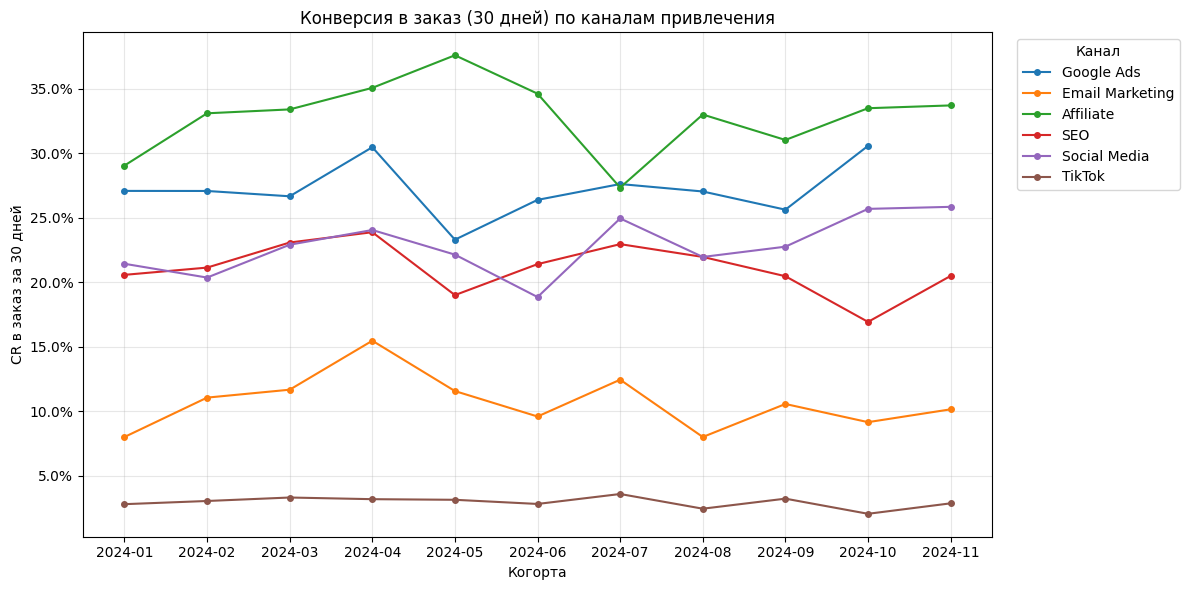

In [40]:
# CR в заказ за 30 дней по каналам и когортам
cr30 = (first_orders[first_orders['diff_days'] <= 30]
        .merge(df_users[['user_id', 'acq_channel']], on='user_id', how='inner')
        .groupby(['cohort_month', 'acq_channel'])['user_id'].nunique())

size = df_users.groupby(['cohort_month', 'acq_channel'])['user_id'].nunique()

cr_ch = (cr30 / size).unstack()
cr_ch.index = pd.to_datetime(cr_ch.index).strftime('%Y-%m')

plt.figure(figsize=(12, 6))
for c in channels:
    c_plot = cr_ch[c].iloc[:-1]   # без декабря - 30-дневное окно не закрылось
    plt.plot(c_plot.index, c_plot.values, marker='o', ms=4, label=c)
plt.title('Конверсия в заказ (30 дней) по каналам привлечения')
plt.xlabel('Когорта')
plt.ylabel('CR в заказ за 30 дней')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend(title='Канал', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**TikTok проваливает и конверсию в заказ - с наибольшим отрывом.** Конверсия привлеченных в заказ за 30 дней у TikTok держится на уровне 3-4% весь год, тогда как у остальных каналов - от 10% (Email Marketing) до 30-38% (Affiliate). Разрыв здесь наибольший из всех метрик: если по активации и удержанию TikTok уступал примерно вдвое, то по конверсии в заказ - почти в десять раз.

,ltv,cac,users,roi
acq_channel,,,,
TikTok,47.3,437.0,19228,-89.2
Email Marketing,268.4,250.4,2044,7.2
Google Ads,877.6,500.4,9319,75.4
Social Media,712.7,374.1,4179,90.5
SEO,567.8,187.6,3312,202.7
Affiliate,1102.2,312.7,6069,252.4


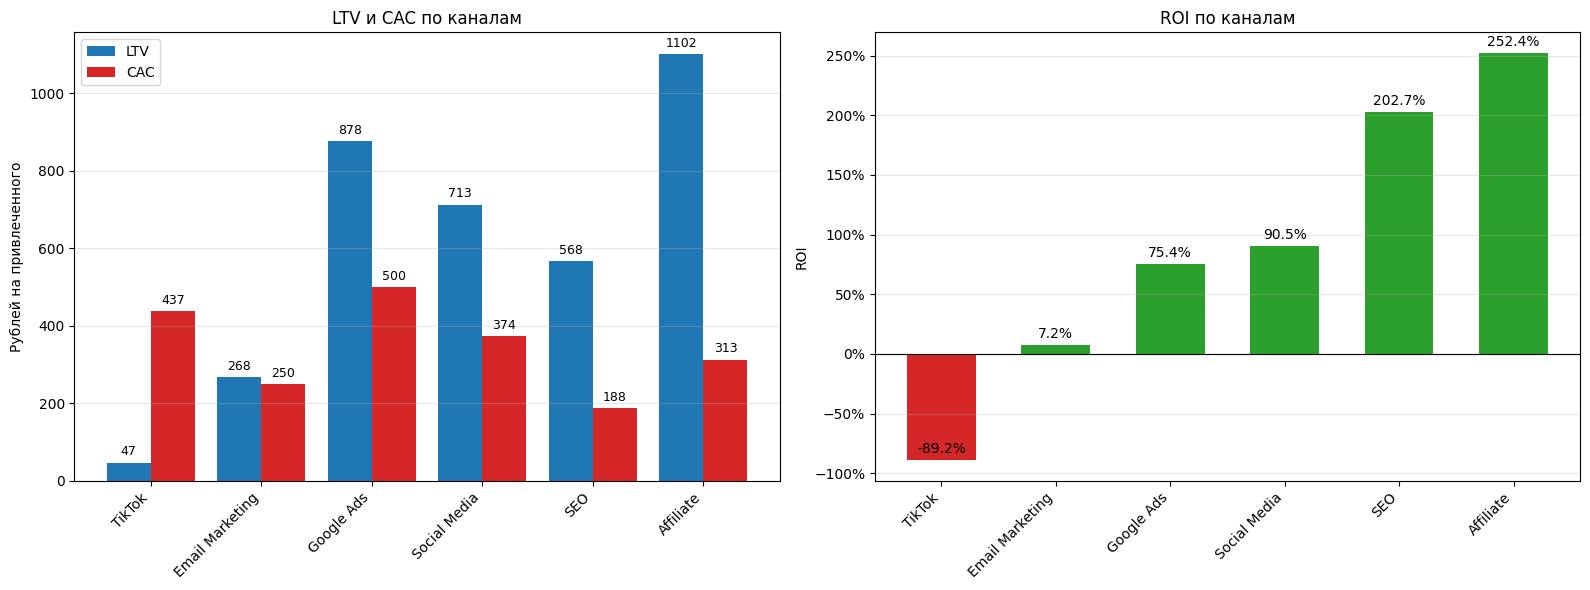

In [41]:
# LTV по каналам (накопленная выручка на привлеченного)
rev_ch = (orders_reg.merge(df_users[['user_id', 'acq_channel']], on='user_id', how='inner')
          .groupby('acq_channel')['revenue'].sum())
size_ch = df_users.groupby('acq_channel')['user_id'].nunique()
ltv_ch = (rev_ch / size_ch).rename('ltv')

# CAC по каналам (бюджет канала на привлеченных каналом)
budget_ch = (df_campaign_costs[df_campaign_costs['acq_channel'] != 'Direct']
             .groupby('acq_channel')['budget'].sum())
cac_ch = (budget_ch / size_ch).rename('cac')

# ROI по каналам
unit_ch = pd.concat([ltv_ch, cac_ch, size_ch.rename('users')], axis=1)
unit_ch['roi'] = 100*(unit_ch['ltv'] - unit_ch['cac']) / unit_ch['cac']
unit_ch = unit_ch.sort_values('roi')
display(unit_ch.round(1))

# Визуализация 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LTV CAC 
x = range(len(unit_ch))
bars1 = axes[0].bar([i-0.2 for i in x], unit_ch['ltv'], width=0.4, label='LTV', color='tab:blue')
bars2 = axes[0].bar([i+0.2 for i in x], unit_ch['cac'], width=0.4, label='CAC', color='tab:red')
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(unit_ch.index, rotation=45, ha='right')
axes[0].set_ylabel('Рублей на привлеченного')
axes[0].set_title('LTV и CAC по каналам')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

# подписи на столбцах
for bars in (bars1, bars2):
    for bar in bars:
        h = bar.get_height()
        axes[0].annotate(f'{h:.0f}', xy=(bar.get_x()+bar.get_width()/2, h),
                         xytext=(0, 3), textcoords='offset points',
                         ha='center', va='bottom', fontsize=9)

# ROI
colors = ['tab:green' if r >= 0 else 'tab:red' for r in unit_ch['roi']]
bars3 = axes[1].bar(list(x), unit_ch['roi'], color=colors, width=0.6)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(unit_ch.index, rotation=45, ha='right')
axes[1].set_ylabel('ROI')
axes[1].set_title('ROI по каналам')
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].grid(axis='y', alpha=0.3)

add_bar_labels(axes[1], bars3)

plt.tight_layout()
plt.show()

**TikTok - единственный убыточный канал, и при этом самый дорогой.** ROI по каналам расставляет их однозначно: пять из шести окупаются (от +7% у Email Marketing до +252% у Affiliate), и лишь TikTok уходит в минус на -89%. Пользователь TikTok приносит в среднем 47 руб при стоимости привлечения 437 руб - почти в десять раз меньше вложенного.

При этом CAC TikTok самый высокий из всех каналов (437 руб против 188 у SEO и 313 у Affiliate). Канал не только хуже всех окупается, но и дороже всех обходится на входе: сочетание максимальной стоимости привлечения с минимальной отдачей.

In [42]:
# Проверка LTV на сопоставимом окне первых периодов жизни когорты (0-1)
ltv30_ch = (orders_reg[orders_reg['n_month'] <= 1]
            .merge(df_users[['user_id','acq_channel']], on='user_id', how='inner')
            .groupby('acq_channel')['revenue'].sum() / size_ch)
display(ltv30_ch.round(1).sort_values())

acq_channel
TikTok              38.6
Email Marketing    192.0
SEO                402.0
Social Media       492.5
Google Ads         593.4
Affiliate          774.7
dtype: float64

Проверка на сопоставимом окне подтверждает, что низкий LTV TikTok обусловлен качеством пользователей, а не недожитием его поздних когорт: за первые 30 дней жизни пользователь TikTok приносит 38,6 руб. против 192-775 руб. у остальных каналов. Даже без учета цензуры окупаемость TikTok составляет менее 10% от стоимости привлечения, то есть канал убыточен структурно, а не временно.

### Сегментация по региону

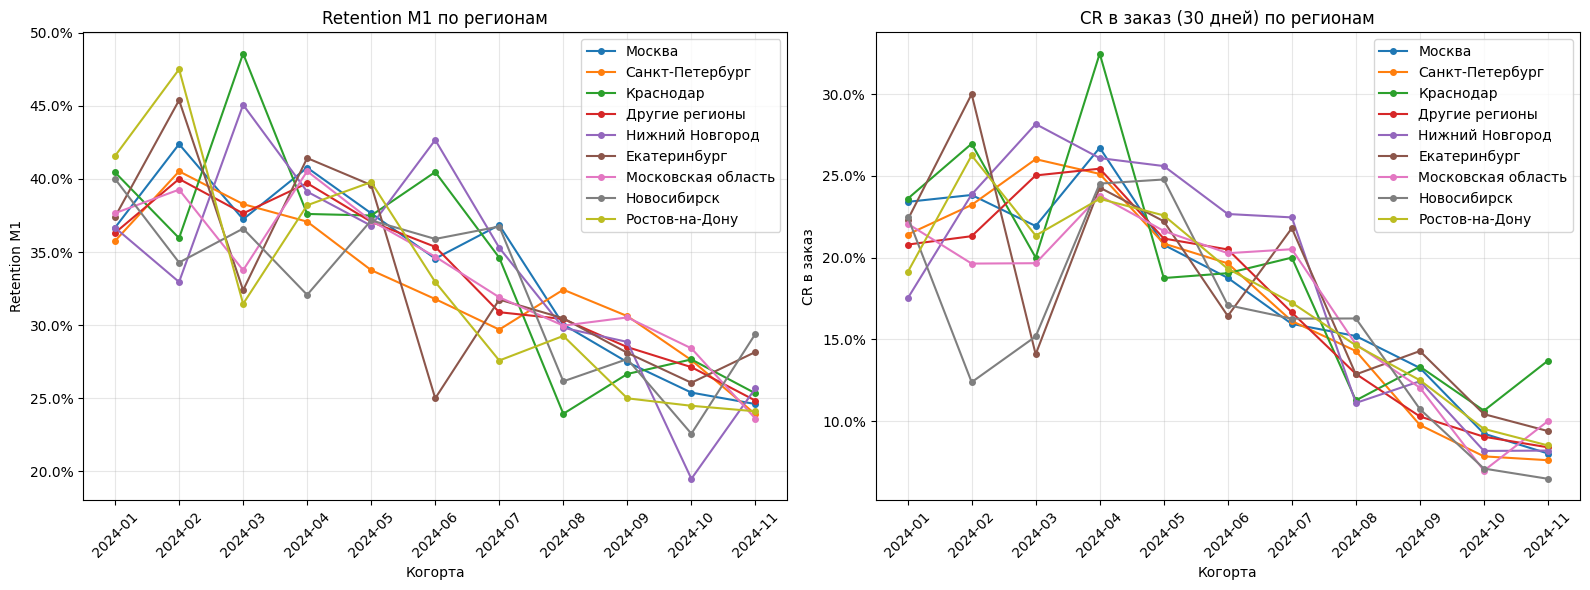

In [43]:
# Retention M1 по регионам и когортам
ev_reg_geo = df_events.merge(
    df_users[['user_id', 'registration_date', 'cohort_month', 'region']],
    on='user_id', how='inner')
ev_reg_geo['n_month'] = (ev_reg_geo['event_date'].dt.to_period('M').astype('int64')
                         - ev_reg_geo['registration_date'].dt.to_period('M').astype('int64'))

m1_geo = (ev_reg_geo[ev_reg_geo['n_month'] == 1]
          .groupby(['cohort_month', 'region'])['user_id'].nunique())
size_geo = df_users.groupby(['cohort_month', 'region'])['user_id'].nunique()
ret_geo = (m1_geo / size_geo).unstack()
ret_geo.index = pd.to_datetime(ret_geo.index).strftime('%Y-%m')

regions = df_users['region'].unique()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


for r in regions:
    col = ret_geo[r].iloc[:-1]
    axes[0].plot(col.index, col.values, marker='o', ms=4, label=r)
axes[0].set_title('Retention M1 по регионам')
axes[0].set_xlabel('Когорта'); axes[0].set_ylabel('Retention M1')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)
axes[0].legend()

# CR в заказ 30 дней
cr30_geo = (first_orders[first_orders['diff_days'] <= 30]
            .merge(df_users[['user_id', 'region']], on='user_id', how='inner')
            .groupby(['cohort_month', 'region'])['user_id'].nunique())
cr_geo = (cr30_geo / size_geo).unstack()
cr_geo.index = pd.to_datetime(cr_geo.index).strftime('%Y-%m')

for r in regions:
    col = cr_geo[r].iloc[:-1]
    axes[1].plot(col.index, col.values, marker='o', ms=4, label=r)
axes[1].set_title('CR в заказ (30 дней) по регионам')
axes[1].set_xlabel('Когорта'); axes[1].set_ylabel('CR в заказ')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

**Регион не является источником деградации.** В отличие от каналов, регионы не расслаиваются по качеству: и retention первого месяца, и конверсия в заказ у всех регионов снижаются от ранних когорт к поздним синхронно, единым пучком, без устойчивого аутсайдера. Retention падает с ~38% до ~25%, конверсия - с ~23% до ~10% одинаково во всех регионах.

Отсутствие расслоения - ожидаемый результат для контрольного измерения. Если бы деградация приходила от географии, отдельные регионы снижались бы, а другие держались. Вместо этого ухудшаются все, что указывает на общую причину, проходящую сквозь регионы, а не связанную с ними. Поскольку канал привлечения меняется во всех регионах одновременно (доля TikTok растет повсеместно), синхронная деградация регионов согласуется с канальным объяснением: качество падает не там, где привлекают, а тем, чем привлекают.

In [44]:
# Средний / медианный чек по регионам
aov_geo = (full_orders.merge(df_users[['user_id','region']], on='user_id', how='inner')
           .groupby('region')['order_sum'].agg(['median','mean','count'])
           .sort_values('median'))
display(aov_geo.round(0))

,median,mean,count
region,,,
Ростов-на-Дону,11820.0,22506.0,535
Нижний Новгород,13194.0,23877.0,695
Москва,13514.0,23701.0,4537
Другие регионы,13631.0,23947.0,5663
Санкт-Петербург,14016.0,24771.0,2714
Екатеринбург,14103.0,25478.0,897
Московская область,14345.0,24924.0,1316
Краснодар,14916.0,26390.0,550
Новосибирск,16172.0,24073.0,602


**Средний чек географически однороден.** Медианный чек по регионам укладывается в узкий коридор 11,8-16,2 тыс. руб, причем крупные регионы (Москва, Другие регионы, Санкт-Петербург) плотно сгруппированы около 13,5-14 тыс., а крайние значения приходятся на регионы с наименьшим числом заказов (Ростов, Новосибирск - по ~ 550), то есть являются шумом малых выборок. Москва не выделяется - ее чек находится в середине распределения.

Региональной дифференциации среднего чека не обнаружено. В совокупности с отсутствием региональных различий в удержании и конверсии это позволяет полностью исключить регион как значимое измерение сегментации: география не влияет ни на качество привлекаемых пользователей, ни на монетизацию покупки.

### Сегментация по категориям товаров

,выручка,доля_%
category_name,,
Мебель для дома,3457221.0,16.3
Бытовая техника,2170863.0,10.2
Украшения и часы,1643701.0,7.8
Товары для туризма,1111620.0,5.2
Спортивный инвентарь,1102211.0,5.2
Автотовары,999338.0,4.7
Товары для кухни,993144.0,4.7
Обувь мужская,891485.0,4.2
Сумки и аксессуары,842210.0,4.0


'топ-3 категории дают: 34.3% выручки'

'топ-5 категорий дают: 44.7% выручки'

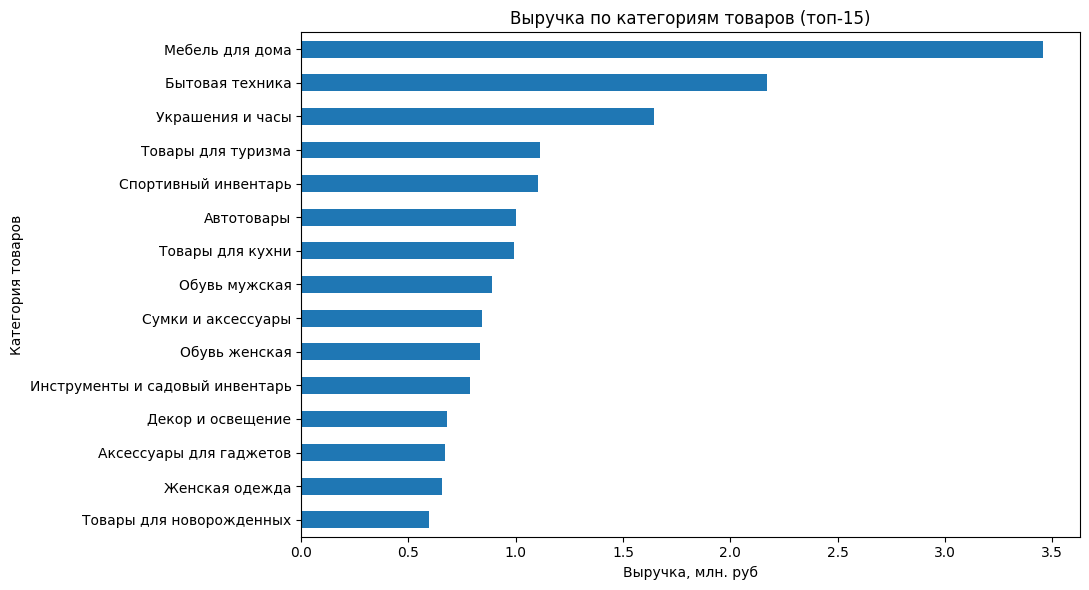

In [45]:
orders_cat = df_orders.merge(df_users[['user_id','cohort_month']], on='user_id', how='inner')

# 1. Структура и концентрация выручки по категориям
cat_rev = (orders_cat.groupby('category_name')['revenue'].sum()
           .sort_values(ascending=False))
cat_share = (cat_rev / cat_rev.sum() * 100).round(1)
display(pd.DataFrame({'выручка': cat_rev.round(0), 'доля_%': cat_share}))
display(f"топ-3 категории дают: {cat_share.head(3).sum():.1f}% выручки")
display(f"топ-5 категорий дают: {cat_share.head(5).sum():.1f}% выручки")

# график - топ-15 категорий по выручке
plt.figure(figsize=(11,6))
(cat_rev/1e6).head(15).sort_values().plot(kind='barh')
plt.title('Выручка по категориям товаров (топ-15)')
plt.xlabel('Выручка, млн. руб')
plt.ylabel('Категория товаров')
plt.tight_layout()
plt.show()

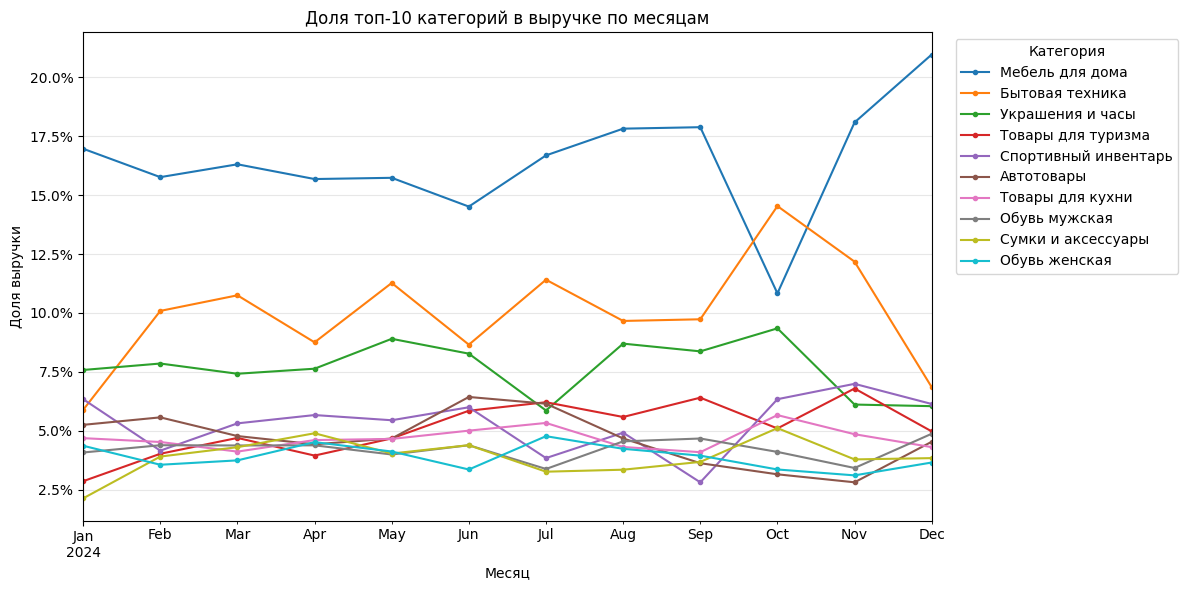

In [46]:
# Доли категорий по месяцам - менялась ли корзина
cat_month = (orders_cat.groupby(['order_month','category_name'])['revenue'].sum()
             .unstack(fill_value=0))
cat_month_share = cat_month.div(cat_month.sum(axis=1), axis=0)

# Смотрим топ-10 категорий
top10 = cat_rev.head(10).index
cat_month_share[top10].plot(figsize=(12,6), marker='o', ms=3)
plt.title('Доля топ-10 категорий в выручке по месяцам')
plt.ylabel('Доля выручки')
plt.xlabel('Месяц')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend(title='Категория', bbox_to_anchor=(1.02,1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Выручка диверсифицирована по категориям, структура стабильна во времени.** Лидируют "Мебель для дома" (16,3%), "Бытовая техника" (10,2%) и "Украшения и часы" (7,8%), но концентрация умеренная: топ-3 категории дают 34% выручки, топ-5 - 45%, остальное плавно распределено по 25 категориям. Зависимости от узкого ассортимента нет - это снижает риск для бизнеса.

Структура выручки по категориям стабильна на всем периоде: доли ведущих категорий не показывают систематического сдвига, несмотря на смену структуры привлечения во втором полугодии. Это означает, что смена доминирующего канала не изменила потребительскую корзину - деградация поздних когорт проявляется в объеме покупок, а не в ассортименте. Разовый всплеск доли бытовой техники в октябре носит характер единичного события и к декабрю нивелируется.

### Сегментация по типу устройства и ОС

In [47]:
# какие пары device + os реально встречаются и как часто
pairs = (df_events.groupby(['device', 'os'])
         .size().sort_values(ascending=False)
         .rename('events').reset_index())
pairs['share'] = (pairs['events'] / pairs['events'].sum() * 100).round(1)
display(pairs)

,device,os,events,share
0,desktop,Windows,70871,9.0
1,mobile,Android,67733,8.6
2,tablet,Android,67377,8.6
3,mobile,iOS,67067,8.5
4,tablet,Windows,66829,8.5
5,mobile,macOS,65896,8.4
6,desktop,iOS,64885,8.3
7,tablet,iOS,63599,8.1
8,tablet,macOS,63483,8.1
9,desktop,Android,62835,8.0


В данных встречаются все 12 комбинаций трех типов устройств и четырех ОС, включая технически невозможные (mobile + Windows, desktop + Android), причем с практически равными долями (8-9%). Такое распределение указывает на случайное присвоение признаков, поэтому воронка по парам `device + os` не строится. Ниже воронки построены отдельно по устройству и по ОС; значимых различий в них по той же причине не ожидается.

' Воронки по типу сегментации: device'

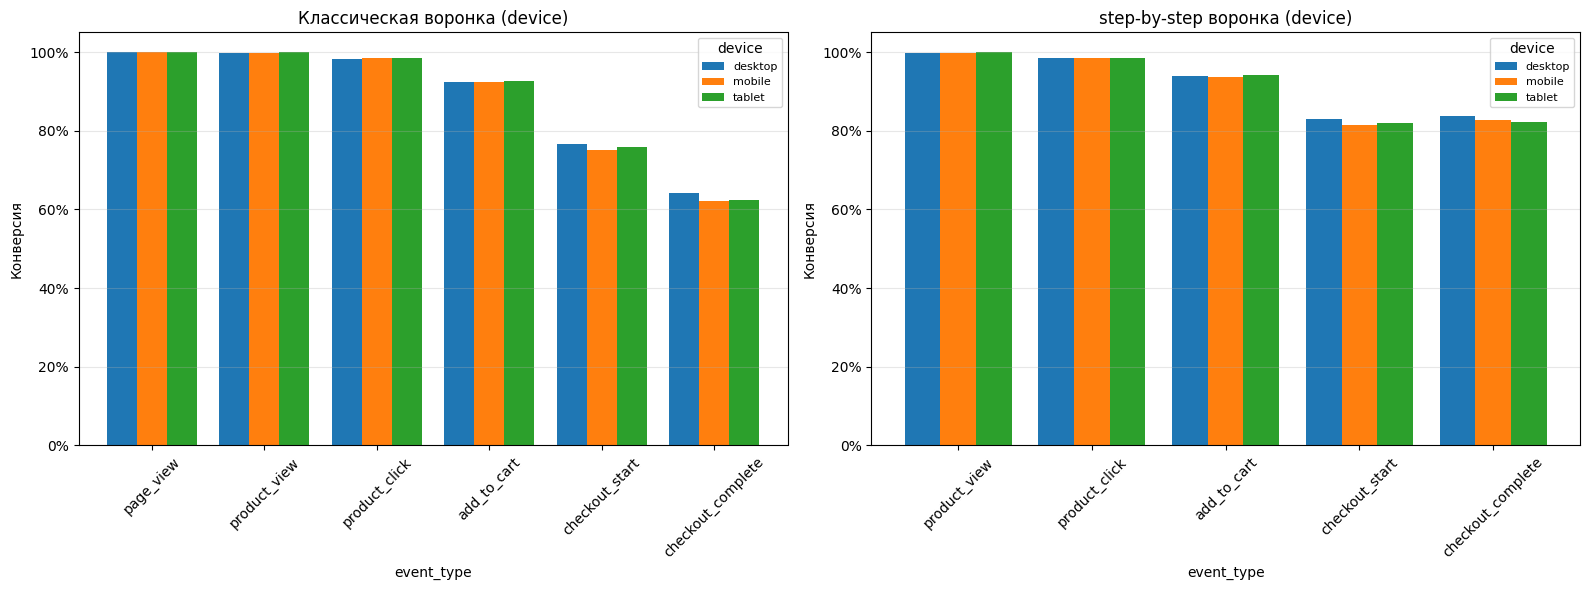

' Воронки по типу сегментации: os'

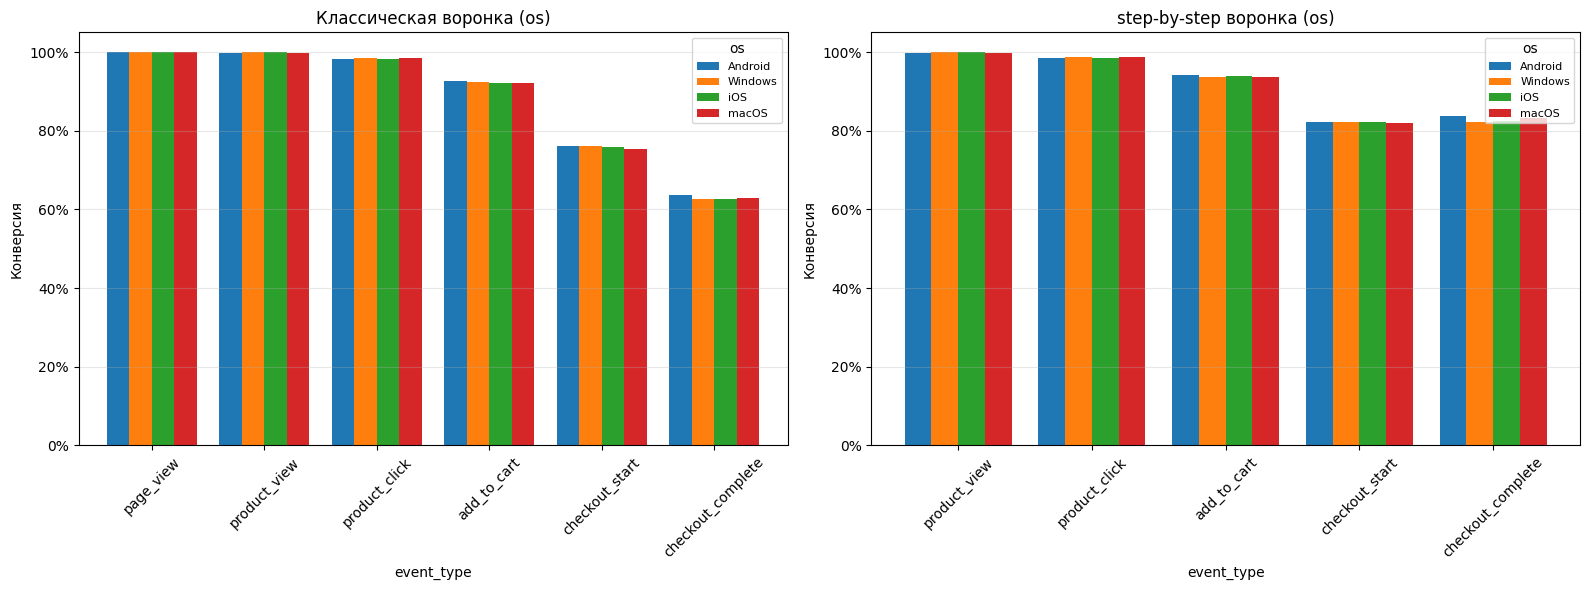

In [48]:
def build_funnel_by_segment(df, segment, steps=funnel_steps):
    funnel_df = df[df['event_type'].isin(steps)]
    counts = (funnel_df.groupby([segment, 'event_type'])['user_id']
              .nunique().unstack()[steps])
    from_first = counts.div(counts[steps[0]], axis=0) * 100
    from_prev = counts.div(counts.shift(1, axis=1)) * 100
    return from_first, from_prev

def plot_funnel_by_segment(df, segment, steps=funnel_steps):
    from_first, from_prev = build_funnel_by_segment(df, segment, steps)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    from_first.T.plot(kind='bar', ax=axes[0], width=0.8)
    axes[0].set_title(f'Классическая воронка ({segment})')
    axes[0].set_ylabel('Конверсия'); axes[0].set_ylim(0, 105)
    axes[0].legend(title=segment, fontsize=8)

    from_prev.T[1:].plot(kind='bar', ax=axes[1], width=0.8)
    axes[1].set_title(f'step-by-step воронка ({segment})')
    axes[1].set_ylabel('Конверсия'); axes[1].set_ylim(0, 105)
    axes[1].legend(title=segment, fontsize=8)

    for ax in axes:
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

for segment in ['device', 'os']:
    display(f" Воронки по типу сегментации: {segment}")
    plot_funnel_by_segment(df_events, segment)

**Устройство и ОС не влияют на прохождение воронки.** Конверсия по всем шагам совпадает у всех типов устройств (desktop, mobile, tablet) и всех ОС (Android, Windows, iOS, macOS) - различия не превышают 1-2 процентных пунктов, то есть находятся на уровне шума. Это подтверждает вывод по распределению пар `device + os`: поля присвоены случайно и с исходами не связаны.

Узкое место на этапе оформления, отмеченное в верхнеуровневом обзоре, воспроизводится во всех сегментах одинаково. Это уточняет его природу: потери на переходе от корзины к оформлению - общее свойство продукта, а не проблема конкретной платформы. Оптимизация оформления даст эффект независимо от устройства.

### Выводы: сегментация и точки роста

#### **Главное**

Источник деградации, обнаруженной на верхнеуровневом обзоре, локализован до одного канала привлечения - **TikTok**. Он приводит пользователей в несколько раз худшего качества по всем метрикам и является единственным убыточным каналом. При этом во втором полугодии компания целенаправленно нарастила его долю, выключив окупаемый канал Google Ads. Остальные измерения (регион, категория, устройство) деградацию не объясняют - проблема сосредоточена в структуре привлечения, а не в продукте, географии или платформе.

#### **Сегментация: поиск различий, инсайтов и точек роста**

Данные разрезаны по всем доступным измерениям - каналам привлечения, регионам, категориям товаров, типам устройств и ОС - с целью найти как источник деградации, так и точки роста: какие сегменты работают лучше, какие хуже, что масштабировать.

**Каналы привлечения - главный инсайт.** Каналы устойчиво расслаиваются по качеству, и расслоение постоянно весь год:

- **Худший канал - TikTok.** Активация 35% (против 60-65% у остальных), retention первого месяца 20% (против 35-48%), конверсия в заказ 3-4% (против 20-38%), LTV 39-47 руб (против 190-1100). ROI -89% - единственный убыточный канал, и при этом самый дорогой в привлечении (CAC 437 руб против 188 у SEO).
- **Лучшие каналы - Affiliate (ROI +252%) и SEO (+203%).** Высокая конверсия, высокий LTV, низкая стоимость привлечения.
- **Средние, но прибыльные - Social Media (+90%), Google Ads (+75%), Email Marketing (+7%).**

Проверка на сопоставимом окне подтвердила, что низкое качество TikTok - свойство канала, а не эффект недожития его поздних когорт: даже за первые 30 дней пользователь TikTok приносит 39 руб против 190-775 у остальных. Это ключевое различие определяет и точку роста (перераспределение бюджета), и источник деградации выручки.

**Регионы - различий нет.** Ни в удержании и конверсии (регионы деградируют синхронно, без выделяющихся), ни в среднем чеке (медиана однородна по регионам) значимых различий не обнаружено. География не влияет ни на качество привлекаемых пользователей, ни на монетизацию покупки - как измерение сегментации регион не информативен.

**Категории товаров - инсайт по структуре выручки.** Выручка сконцентрирована в узком наборе категорий: топ-3 ("Мебель для дома" 16,3%, "Бытовая техника" 10,2%, "Украшения и часы" 7,8%) дают 34% выручки, топ-5 - 45%. Продукт конкурентоспособен в ограниченном ассортименте. Нижние категории ("Детская одежда" 1,4%, "Книги и канцтовары" 0,9%, "Средства для ухода" 0,7%) практически не генерируют продаж - кандидаты на сокращение ассортимента или пересмотр закупок. Структура категорий при этом стабильна во времени: смена канала привлечения не изменила потребительскую корзину.

**Устройства и ОС - на воронку не влияют.** Конверсия по всем шагам воронки совпадает у всех типов устройств (desktop, mobile, tablet) и всех ОС (Android, Windows, iOS, macOS) - различия в пределах 1-2 процентных пунктов. Точка отвала в воронке (оформление заказа) одинакова на всех платформах, то есть это свойство продукта, а не конкретного устройства.

#### **На каких этапах воронки теряются пользователи**

Потери сосредоточены в двух местах, и оба не зависят от платформы (воронка одинакова для всех устройств и ОС):

- **На входе, до воронки:** половина привлеченных не активируется - 49% зарегистрированных не совершают ни одного действия, преимущественно пользователи TikTok. Это крупнейшая потеря, больше всего последующего оттока вместе взятого.
- **На оформлении заказа:** переход корзина -> оформление теряет ~18%, оформление -> завершение - еще ~17%. Верх воронки близок к насыщению. Это единственная точка потерь, устранимая улучшением продукта, а не каналов.

#### **Куда направить внимание и ресурсы**

Три направления, по убыванию ожидаемого эффекта:

1. **Структура привлечения** - пересмотреть распределение бюджета: сократить TikTok, нарастить окупаемые Affiliate, SEO, Google Ads. Наибольший рычаг, напрямую влияет на выручку и окупаемость.
Каналы различаются не только окупаемостью, но и управляемостью бюджетом. По простоте масштабирования они выстраиваются в порядке Google Ads -> Affiliate -> SEO. Google Ads - платный аукцион с прямым и предсказуемым приростом объема от бюджета. Affiliate тоже масштабируется вложениями - через расширение партнерской сети и комиссий, но менее линейно, чем аукцион. SEO же преимущественно органический канал: его высокая окупаемость обеспечена низкой стоимостью, но нарастить объем простым увеличением бюджета нельзя, он растет через позиции в выдаче и контент. Поэтому основными адресатами перераспределения бюджета выступают Google Ads и Affiliate как окупаемые и управляемые каналы, а SEO при высоком ROI стоит развивать органически.
Отдельная оговорка по каналу Google Ads. В данных его финансирование прекращается во втором полугодии. Если это управленческое решение, рекомендация - вернуть бюджет в канал. Если же закрытие вызвано внешними обстоятельствами, не зависящими от команды, то канал недоступен, и в качестве масштабируемого платного аналога с тем же принципом работы (аукционная модель, прямое управление бюджетом) стоит рассмотреть отечественные площадки, например Яндекс.Директ. В обоих сценариях логика одна: заместить убыточный TikTok управляемым платным каналом с положительной окупаемостью.

2. **Активация** - половина привлеченных не доходит до продукта; онбординг и стимул первого действия поднимут отдачу от всего привлечения сверху.
3. **Оформление заказа** - единственная продуктовая точка роста, эффект на всех пользователях независимо от канала.

#### **Гипотезы**

**[Привлечение] Перераспределение бюджета.**
Сокращение доли TikTok с переводом бюджета в Affiliate и Google Ads повысит общую окупаемость привлечения - средний ROI когорты вырастет с текущего убыточного уровня до положительного.

Основание: при сопоставимых CAC и объемах привлечения LTV пользователя Google Ads выше более чем в 10 раз, чем у TikTok, а Affiliate имеет лучший ROI из всех каналов (+252%). Оба выбраны адресатами как окупаемые и масштабируемые бюджетом: Google Ads - через прямой аукцион, Affiliate - через партнерскую сеть. SEO при более высоком, чем у Google Ads, ROI деньгами не масштабируется и развивается органически, поэтому в перераспределение бюджета не включен.

Проверка: поэтапное перераспределение бюджета либо A/B-сплит, метрика - ROI и retention M1 новых когорт до и после.

**[Привлечение] Стимул первой покупки для TikTok.**
Промокод на первый заказ для активировавшихся пользователей TikTok повысит их конверсию в первый заказ на ~10%.

Основание: активировавшиеся пользователи TikTok доходят до заказа существенно реже пользователей других каналов; стимул снижает барьер первой покупки.

Проверка: A/B - промокод против его отсутствия на новых TikTok-регистрациях, метрика - CR в заказ за 30 дней.

**[Привлечение] Категорийное позиционирование рекламы.**
Рекламные кампании, ведущие на сильнейшие по выручке категории (топ-3), покажут конверсию в первый заказ на 10-15% выше, чем кампании с обобщенным позиционированием.

Основание: выручка сконцентрирована в узком наборе категорий (топ-3 - 34%); привлечение, соответствующее специализации продукта, вероятно приводит пользователей с более релевантным намерением.

Проверка: A/B рекламных креативов - категорийные против обобщенных, метрика - CR в первый заказ привлеченных.

**[Активация] Онбординг новых пользователей.**
Онбординг в 1-2 экрана с подборкой топ-товаров сразу после регистрации поднимет активацию с 49% до 55% и выше.

Основание: 49% зарегистрированных не совершают ни одного действия - потери на входе превышают весь последующий отток.

Проверка: A/B онбординга на новых регистрациях, метрика - доля активированных за 7 дней.

**[Продукт] Упрощение оформления и оплаты.**
Оптимизация оформления заказа (оплата в один клик, сохраненные карты, предложение рассрочки) снизит потери на последних шагах воронки на ~5 процентных пунктов.

Основание: на переходах корзина -> оформление и оформление -> завершение теряется по 17-18%, потери устойчивы и не зависят от устройства и ОС, то есть являются свойством продукта. Меры действуют на оба перехода: оплата в один клик сокращает путь, позволяя миновать отдельный шаг начала оформления, а сохраненные карты и рассрочка снижают трение на самом оформлении.

Проверка: A/B новой формы оформления против текущей, метрика - сквозная конверсия add_to_cart -> checkout_complete (доля добавивших в корзину, завершивших заказ).




## A/B-тест: бонус на первую покупку для пользователей TikTok

### Контекст

По итогам анализа команда продукта решила проверить, можно ли поднять конверсию трафика TikTok финансовым стимулом, и запустила эксперимент с бонусом на первую покупку. Дизайн эксперимента подготовлен командой продукта; из-за срочности запуск проведен без предварительного расчета мощности и MDE.

**Задача:** проверить корректность проведения эксперимента, оценить результаты по метрикам дизайна и дать рекомендацию по внедрению с учетом выявленных ограничений.

**Данные эксперимента:** `users_AB`, `events_AB`, `orders_AB` (структура идентична историческим таблицам), `sessions_AB` и `AB_split_users` - распределение пользователей по группам (`user_id`, `group`).

Описание таблицы `sessions_AB`

| Поле | Описание |
|------|----------|
| `session_id` | Уникальный идентификатор сессии. |
| `user_id` | Уникальный идентификатор пользователя. |
| `session_start` | Дата и время начала сессии. |
| `os` | Операционная система устройства. |
| `device` | Тип устройства. |
| `region` | Регион пользователя. |
| `browser` | Браузер, используемый пользователем. |
| `country` | Страна пользователя. |
| `entry_path` | Путь входа (начальная страница сессии). |
| `path_start` | Путь начала отслеживания. |
| `utm_source` |  |
| `screen_size` | Разрешение экрана устройства. |
| `scroll_depth` | Глубина прокрутки. |
| `user_segment` | Сегмент пользователя (regular/premium и т.д.). |
| `utm_campaign_id` | Идентификатор рекламной кампании. |
| `session_week` | Неделя сессии. |
| `session_month` | Месяц сессии. |

#### Дизайн эксперимента (подготовлен командой продукта)

Бонус на первую покупку для пользователей TikTok

**Контекст и цель эксперимента**

- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлеченных через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.  
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.  
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку

---

**Формат эксперимента**

- **Тип эксперимента:** Сплит-роллинг (rolling split)  
- **Канал:** Только пользователи, пришедшие с TikTok  
- **Группы:**  
  - **Контрольная (A):** пользователи TikTok без бонуса  
  - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку  
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации  
- **Период проведения:** 3 недели (фиксировано)

---

#### Ключевые метрики

**Основная метрика**

- **Конверсия в первую покупку** - доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку  
  - *Цель:* увеличить конверсию с помощью бонуса  
  - *Критерий успеха:* статистически значимый рост конверсии в тестовой группе

**Вспомогательные метрики**

- **ARPU** (средняя выручка на пользователя TikTok)  
- **ARPPU** (средняя выручка на покупателя TikTok)  
- **AOV** (средний чек TikTok)

**Барьерная метрика**

- **Общая выручка от пользователей TikTok**

---

#### Размеры групп и запуск

- **Целевая аудитория:** только пользователи TikTok  
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента  
- **Комментарий:** запуск без предварительного расчета мощности и MDE из-за срочности задачи


___
### Предобработка данных эксперимента

Метрики эксперимента (конверсия в первую покупку, ARPU, ARPPU, AOV) рассчитываются на основе трех таблиц: `users_AB` (атрибуты и канал привлечения), `orders_AB` (заказы и выручка) и `AB_split_users` (распределение по группам). Таблицы `events_AB` и `sessions_AB` в расчете метрик не участвуют, поэтому предобработка проводится только по трем используемым витринам.

Проверяются: дубликаты, корректность категориальных значений, временные границы периода эксперимента, распределение количественных величин и наличие аномалий.

#### Загрузка данных

In [49]:
df_orders_ab = pd.read_csv('../datasets/orders_AB.csv', low_memory=False, parse_dates= ['order_date', 'order_week', 'order_month'])
df_split_users_ab = pd.read_csv('../datasets/AB_split_users.csv', low_memory=False)
df_users_ab = pd.read_csv('../datasets/users_AB.csv', low_memory=False, parse_dates= ['registration_date', 'cohort_week', 'cohort_month'])
df_events_ab = pd.read_csv('../datasets/events_AB.csv', low_memory=False, parse_dates= ['event_date', 'event_week', 'event_month'])
df_sessions_ab = pd.read_csv('../datasets/sessions_AB.csv', low_memory=False, parse_dates= ['session_start', 'session_week', 'session_month'])
display('Данные загружены локально')

'Данные загружены локально'

#### Общее знакомство с данными и проверка на дубликаты

In [50]:
# Общая информация о таблицах и проверка на явные дубликаты
datasets_ab = {
    'df_users_ab': df_users_ab,
    'df_orders_ab': df_orders_ab,
    'df_split_users_ab': df_split_users_ab,
    
}
for name, data in datasets_ab.items():
    display(f" Информация о {name} :")
    display(data.head())
    display(data.info())
    display(f'явных дубликатов: {data.duplicated().sum()}')
    display('-'*50)

' Информация о df_users_ab :'

,user_id,registration_date,os,age,device,gender,region,browser,country,acq_channel,campaign_id,user_segment,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,Android,49,mobile,M,Екатеринбург,Edge,Россия,TikTok,10.0,спящий,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,iOS,50,tablet,M,Санкт-Петербург,Chrome,Россия,TikTok,43.0,VIP,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,iOS,60,desktop,F,Москва,Firefox,Россия,TikTok,27.0,активный,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,iOS,31,desktop,M,Екатеринбург,Firefox,Россия,TikTok,15.0,новичок,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,Android,44,tablet,M,Санкт-Петербург,Firefox,Россия,TikTok,15.0,спящий,rare,2024-01-01,2024-01-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   os                 22196 non-null  object        
 3   age                22196 non-null  int64         
 4   device             22196 non-null  object        
 5   gender             22196 non-null  object        
 6   region             22196 non-null  object        
 7   browser            22196 non-null  object        
 8   country            22196 non-null  object        
 9   acq_channel        22196 non-null  object        
 10  campaign_id        22196 non-null  float64       
 11  user_segment       22196 non-null  object        
 12  buyer_segment      22196 non-null  object        
 13  cohort_week        22196 non-null  datetime64[ns]
 14  cohort

None

'явных дубликатов: 0'

'--------------------------------------------------'

... (8 outputs left out)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB


None

'явных дубликатов: 0'

'--------------------------------------------------'

In [51]:
# Приведение order_date к datetime (формат дат в исходном файле неоднороден)
df_orders_ab['order_date'] = pd.to_datetime(df_orders_ab['order_date'], format='mixed')

Даты в данных эксперимента пересекаются с историческими. Для отбора участников эксперимента таблицы объединяются с распределением по группам.

In [52]:
df_orders_ab_split = pd.merge(df_orders_ab, df_split_users_ab, on='user_id', how='inner')
df_users_ab_split = pd.merge(df_users_ab, df_split_users_ab, on='user_id', how='inner')
display(f"Количество уникальных пользователей df_split_users_ab: {df_split_users_ab['user_id'].nunique()}")
display(f"Количество уникальных пользователей df_users_ab_split: {df_users_ab_split['user_id'].nunique()}")

'Количество уникальных пользователей df_split_users_ab: 2968'

'Количество уникальных пользователей df_users_ab_split: 2968'

Все пользователи эксперимента попали в витрину `users_AB`

In [53]:
# Неявные дубликаты в df_orders_ab_split по связке 'user_id', 'order_date', 'product_name', 'quantity'
df_orders_ab_split.duplicated(subset=['user_id', 'order_date', 'product_name', 'quantity']).sum()

np.int64(2)

In [54]:
# Найденные дубликаты
df_orders_ab_split[df_orders_ab_split.duplicated(subset=['user_id', 'order_date', 'product_name', 'quantity'], keep=False)].sort_values(by='user_id')

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month,group
17,37485,45910,2025-01-07 10:08:22,Маска для волос,1,1243.98,1243.98,Косметика и парфюмерия,2025-01-06,2025-01-01,treatment
18,37484,45910,2025-01-07 10:08:22,Маска для волос,1,1243.98,1243.98,Косметика и парфюмерия,2025-01-06,2025-01-01,treatment
233,38412,47663,2025-01-25 21:12:00,Джинсы Levi's,1,7024.59,7024.59,Мужская одежда,2025-01-20,2025-01-01,treatment
234,38413,47663,2025-01-25 21:12:00,Джинсы Levi's,1,7024.59,7024.59,Мужская одежда,2025-01-20,2025-01-01,treatment


Особенность логирования заказов из исторических данных повторяется. Дубликаты удаляются с сохранением первого вхождения.

In [55]:
initial_row_count = df_orders_ab_split.shape[0]
df_orders_ab_split = (df_orders_ab_split
                     .drop_duplicates(subset=['user_id', 'order_date', 'product_name', 'quantity'], keep='first')
                     .reset_index(drop=True))
final_row_count = df_orders_ab_split.shape[0]
deleted = initial_row_count - final_row_count
deleted_share = round(100*deleted / initial_row_count, 2) 
display(f'Удалено строк с дубликатами: {deleted}, что составило {deleted_share}% данных')

'Удалено строк с дубликатами: 2, что составило 0.78% данных'

#### Проверка категориальных данных

In [56]:
# Категориальные данные в df_users_ab 
for column in ['gender', 'region', 'acq_channel', 'buyer_segment', 'os', 'device', 'browser', 'country', 'user_segment']:
    display(df_users_ab_split[column].value_counts())

gender
F    1511
M    1457
Name: count, dtype: int64

region
Другие регионы        981
Москва                730
Санкт-Петербург       450
Московская область    235
Екатеринбург          140
Нижний Новгород       124
Новосибирск           115
Краснодар             109
Ростов-на-Дону         84
Name: count, dtype: int64

acq_channel
TikTok    2968
Name: count, dtype: int64

buyer_segment
medium      1069
rare         887
regular      551
one_time     461
Name: count, dtype: int64

os
iOS        776
macOS      760
Windows    724
Android    708
Name: count, dtype: int64

device
tablet     1014
mobile      991
desktop     963
Name: count, dtype: int64

browser
Firefox    781
Safari     745
Chrome     744
Edge       698
Name: count, dtype: int64

country
Россия    2968
Name: count, dtype: int64

user_segment
VIP         794
новичок     736
спящий      723
активный    715
Name: count, dtype: int64

In [57]:
# Категориальные данные в df_orders_ab  
for column in ['product_name', 'category_name']:
    display(df_orders_ab_split[column].value_counts())

product_name
Куртка детская          6
Мука пшеничная          6
Чай черный              5
Сахар белый             5
Шорты для тренировок    5
                       ..
Самокат трехколесный    1
Настольная игра         1
Лопата штыковая         1
Автокресло              1
Стеллаж для книг        1
Name: count, Length: 141, dtype: int64

category_name
Продукты питания                   32
Детская одежда                     18
Мебель для дома                    14
Инструменты и садовый инвентарь    14
Обувь женская                      14
Зоотовары                          13
Товары для туризма                 12
Медицинские товары                 11
Одежда для спорта                  11
Автотовары                         11
Обувь мужская                      10
Бытовая техника                    10
Товары для новорожденных            9
Декор и освещение                   9
Сумки и аксессуары                  8
Украшения и часы                    8
Товары для кухни                    8
Спортивный инвентарь                8
Косметика и парфюмерия              7
Средства для ухода                  6
Детские игрушки                     6
Женская одежда                      4
Книги и канцтовары                  4
Аксессуары для гаджетов             3
Мужская одежда                      3
Name: count, dtype: int64

In [58]:
display(df_split_users_ab['group'].value_counts())

group
control      1503
treatment    1465
Name: count, dtype: int64

#### Проверка количественных данных

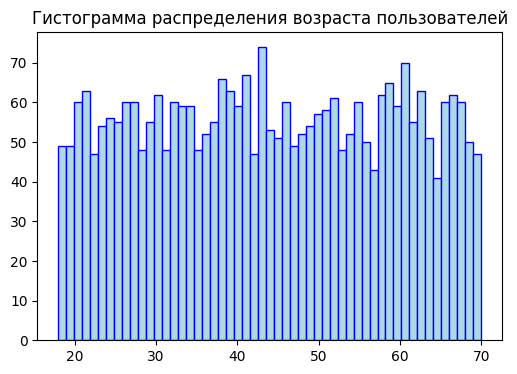

In [59]:
# Гистограмма распределения возраста пользователей
plt.figure(figsize=(6, 4))
plt.hist(df_users_ab_split['age'], bins=df_users_ab_split['age'].max()-df_users_ab_split['age'].min()+1, color='lightblue', edgecolor='blue')
plt.title('Гистограмма распределения возраста пользователей')
plt.show()

count       253.000000
mean      16662.851225
std       22063.460290
min         218.820000
1%          229.547600
25%        2808.960000
50%        8455.000000
75%       21953.740000
95%       54931.232000
99%       94312.570800
max      168032.340000
Name: total_price, dtype: float64

'total_price <= 0:'

np.int64(0)

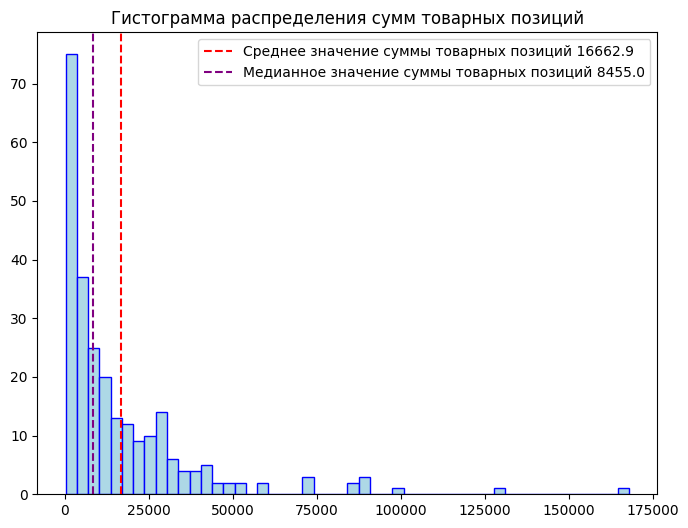

In [60]:
display(df_orders_ab_split['total_price'].describe(
    percentiles=[.01, .25, .5, .75, .95, .99]))
display('total_price <= 0:', (df_orders_ab_split['total_price'] <= 0).sum())
# Гистограмма распределения сумм заказов
plt.figure(figsize=(8, 6))
plt.hist(df_orders_ab_split['total_price'], bins=50, color='lightblue', edgecolor='blue')
plt.title('Гистограмма распределения сумм товарных позиций')
plt.axvline(df_orders_ab_split['total_price'].mean(), color='red', ls='--',
            label=f"Среднее значение суммы товарных позиций {df_orders_ab_split['total_price'].mean():.1f}")
plt.axvline(df_orders_ab_split['total_price'].median(), color='purple', ls='--',
            label=f"Медианное значение суммы товарных позиций {df_orders_ab_split['total_price'].median():.1f}")
plt.legend()
plt.show()

In [61]:
periods_ab_split = {
    'users_ab_split.registration_date': df_users_ab_split['registration_date'],
    'orders_ab_split.order_date': df_orders_ab_split['order_date'],

}
for name, s in periods_ab_split.items():
    display(f"{name}: {s.min()} - {s.max()} | дней: {(s.max()-s.min()).days}")

'users_ab_split.registration_date: 2025-01-01 00:05:00 - 2025-01-26 23:41:00 | дней: 25'

'orders_ab_split.order_date: 2025-01-01 11:57:43 - 2025-01-26 20:39:35 | дней: 25'

#### Вывод по предобработке данных эксперимента

Для анализа эксперимента используются три таблицы: `users_AB`, `orders_AB` и `AB_split_users`. Таблицы событий и сессий в расчете метрик не участвуют.

- Данные содержали как экспериментальную, так и историческую выборку. Историческая часть отсечена внутренним объединением с таблицей распределения по группам (`AB_split_users`) - для анализа оставлены только 2968 пользователей эксперимента.
- Все участники эксперимента присутствуют в витрине `users_AB` (потерь нет), канал привлечения у всех - TikTok, что соответствует дизайну.
- В заказах обнаружено 2 неявных дубликата (та же особенность логирования, что в исторических данных) - удалены.
- Пропусков и нулевых/отрицательных сумм заказов нет. Распределение сумм правостороннее (медиана ~8 тыс. руб при среднем ~16,5 тыс.), аномалий и мусорных значений не выявлено.
- Временной диапазон слегка превышает заявленный

Данные корректны и готовы к проверке эксперимента.

### Проверка корректности проведения эксперимента

Перед расчетом метрик необходимо убедиться, что эксперимент проведен корректно: группы сопоставимы, распределение честное, период адекватен. Проверяются:

1. Баланс групп (равномерность сплита)
2. Отсутствие пересечения групп (один пользователь - одна группа)
3. Однородность групп по ключевым атрибутам (device, os, region)
4. Период эксперимента и равномерность набора


In [62]:
# Баланс групп
users_by_group = df_split_users_ab.groupby('group')['user_id'].nunique().reset_index(name='users')
users_by_group['share'] = round(100 * users_by_group['users'] / users_by_group['users'].sum(), 2)
users_by_group

,group,users,share
0,control,1503,50.64
1,treatment,1465,49.36


In [63]:
# SRM: значимо ли отклонение сплита от 50/50
n_ctrl = (df_split_users_ab['group'] == 'control').sum()
n_total = len(df_split_users_ab)

srm_p = st.binomtest(n_ctrl, n_total, 0.5).pvalue   # для scipy < 1.7: st.binom_test(...)
display(f"control: {n_ctrl}, treatment: {n_total - n_ctrl}, ожидалось по {n_total / 2:.0f}")
display(f"p-value биномиального теста на равенство долей: {srm_p:.3f}")

'control: 1503, treatment: 1465, ожидалось по 1484'

'p-value биномиального теста на равенство долей: 0.497'

In [64]:
flawed_users = df_split_users_ab.groupby('user_id')['group'].nunique()
display(f"Пользователей в нескольких группах: {(flawed_users > 1).sum()}")

'Пользователей в нескольких группах: 0'

Всего 2968 пользователей эксперимента: 1503 (50,64%) в контрольной группе и 1465 (49,36%) в тестовой. Отклонение от равного сплита статистически незначимо (p = 0,497), то есть SRM (Sample Ratio Mismatch) отсутствует - механизм распределения не отдает предпочтения одной из групп. Пересечений между группами нет: ни один пользователь не попал в обе.

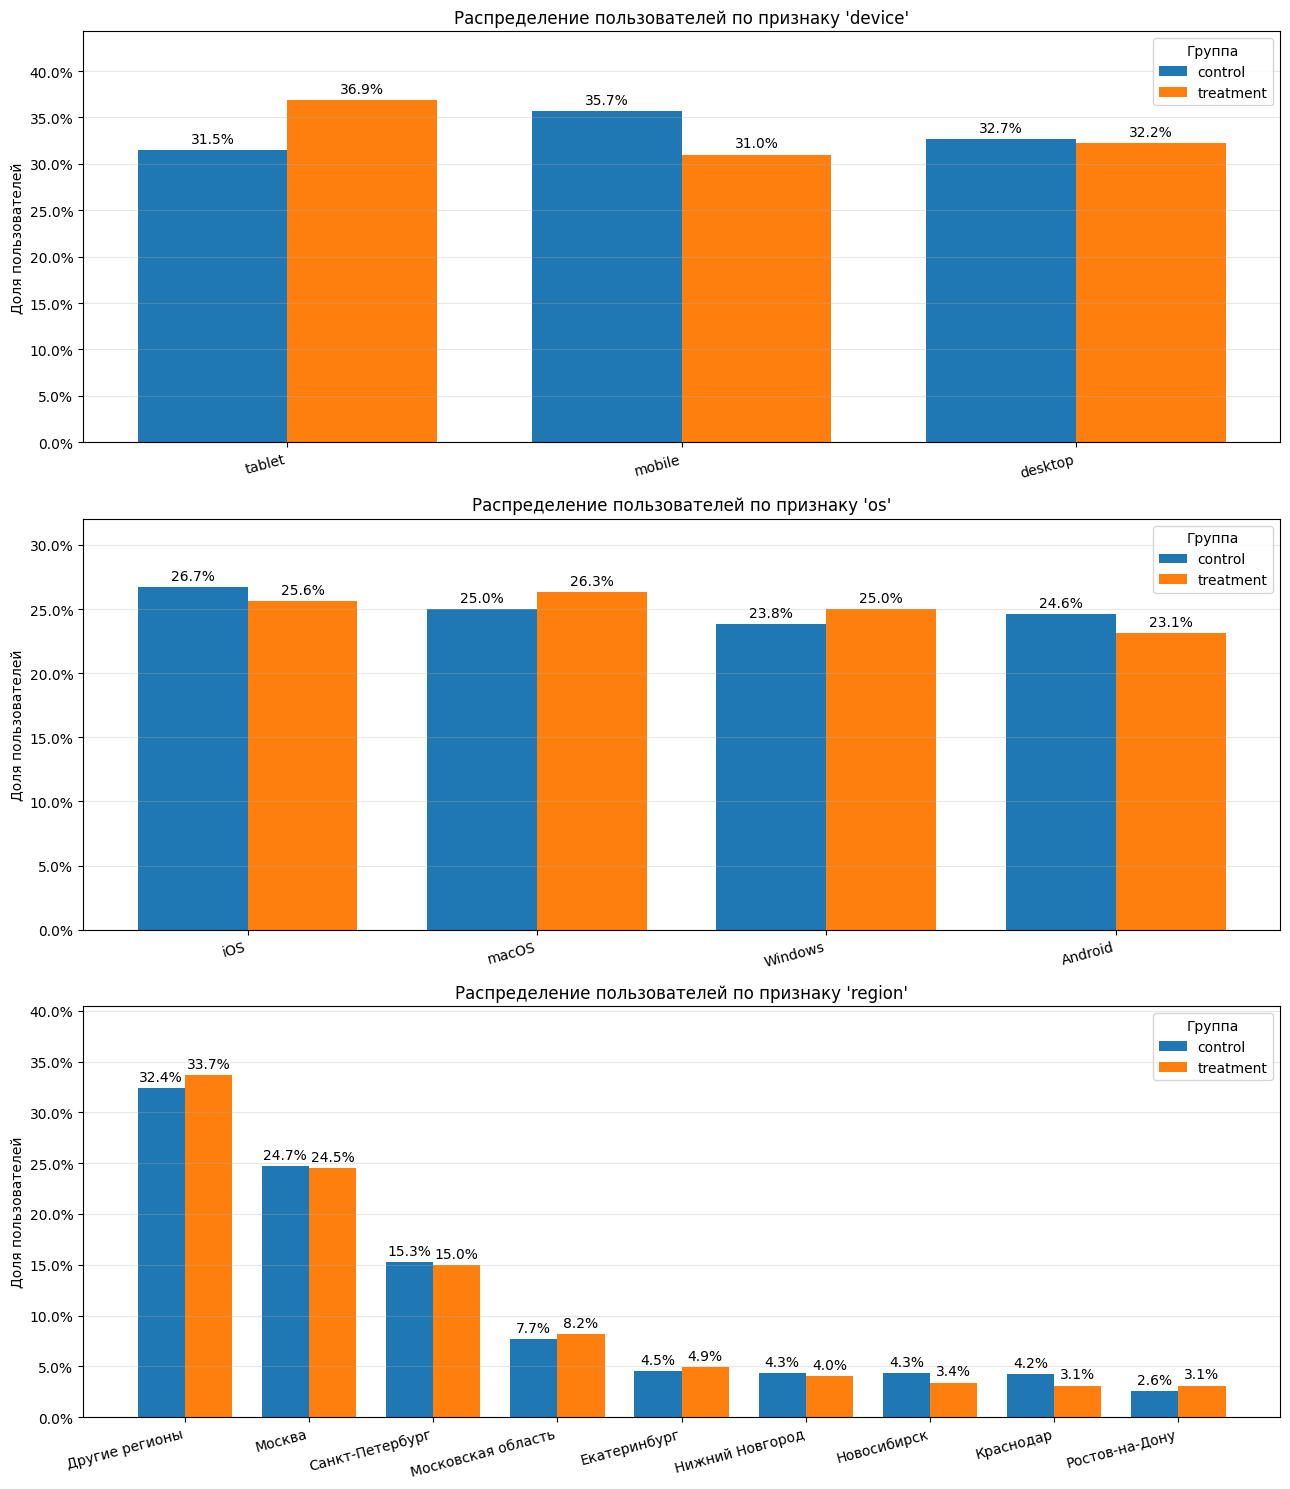

In [65]:
# Распределение пользователей по ключевым атрибутам
columns = ['device', 'os', 'region']
groups = ['control', 'treatment']

fig, axes = plt.subplots(len(columns), 1, figsize=(13, 15))

for ax, col in zip(axes, columns):
    tab = (df_users_ab_split
           .groupby('group')[col]
           .value_counts(normalize=True)
           .unstack()
           .reindex(index=groups)
           .fillna(0)
           .round(3) * 100)

    # категории по убыванию средней доли - чтобы крупные слева
    tab = tab[tab.mean().sort_values(ascending=False).index]

    categories = tab.columns.tolist()
    x = np.arange(len(categories))
    width = 0.38

    for i, g in enumerate(tab.index):
        offset = (i - (len(tab.index) - 1) / 2) * width
        bars = ax.bar(x + offset, tab.loc[g].values, width, label=g)
        add_bar_labels(ax, bars)

    ax.set_title(f"Распределение пользователей по признаку '{col}'")
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=15, ha='right')
    ax.set_ylabel('Доля пользователей')
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set_ylim(0, tab.values.max() * 1.2)
    ax.legend(title='Группа')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
# Однородность групп по атрибутам: хи-квадрат вместо визуальной оценки
for col in ['device', 'os', 'region']:
    cont = pd.crosstab(df_users_ab_split['group'], df_users_ab_split[col])
    chi2, p, dof, _ = st.chi2_contingency(cont)
    display(f"{col}: chi2 = {chi2:.2f}, dof = {dof}, p-value = {p:.3f}")

'device: chi2 = 11.22, dof = 2, p-value = 0.004'

'os: chi2 = 1.88, dof = 3, p-value = 0.599'

'region: chi2 = 5.53, dof = 8, p-value = 0.700'

In [67]:
# Где именно сидит расхождение и насколько оно сильное
cont = pd.crosstab(df_users_ab_split['group'], df_users_ab_split['device'])
chi2, p, dof, expected = st.chi2_contingency(cont)

display('Наблюдаемые частоты:')
display(cont)
display('Остатки Пирсона (наблюдаемое - ожидаемое) / sqrt(ожидаемое):')
display(((cont - expected) / np.sqrt(expected)).round(2))

n = cont.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(cont.shape) - 1)))
display(f"Cramer's V = {cramers_v:.3f}")

'Наблюдаемые частоты:'

device,desktop,mobile,tablet
group,,,
control,492,537,474
treatment,471,454,540


'Остатки Пирсона (наблюдаемое - ожидаемое) / sqrt(ожидаемое):'

device,desktop,mobile,tablet
group,,,
control,0.2,1.57,-1.74
treatment,-0.2,-1.59,1.77


"Cramer's V = 0.061"

In [68]:
# Решающая проверка: предсказывает ли device конверсию внутри контрольной группы
buyers = set(df_orders_ab_split['user_id'])

u_check = df_users_ab_split[['user_id', 'group', 'device']].copy()
u_check['converted'] = u_check['user_id'].isin(buyers).astype(int)

ctrl = u_check[u_check['group'] == 'control']
display(ctrl.groupby('device')['converted'].agg(
    buyers='sum', users='count', cr='mean').round(4))

cont_dev = pd.crosstab(ctrl['device'], ctrl['converted'])
chi2_dev, p_dev, dof_dev, exp_dev = st.chi2_contingency(cont_dev)
display(f"минимальная ожидаемая частота: {exp_dev.min():.1f}")
display(f"device vs конверсия (контроль): chi2 = {chi2_dev:.2f}, dof = {dof_dev}, p-value = {p_dev:.3f}")

,buyers,users,cr
device,,,
desktop,4,492,0.0081
mobile,5,537,0.0093
tablet,7,474,0.0148


'минимальная ожидаемая частота: 5.0'

'device vs конверсия (контроль): chi2 = 1.15, dof = 2, p-value = 0.562'

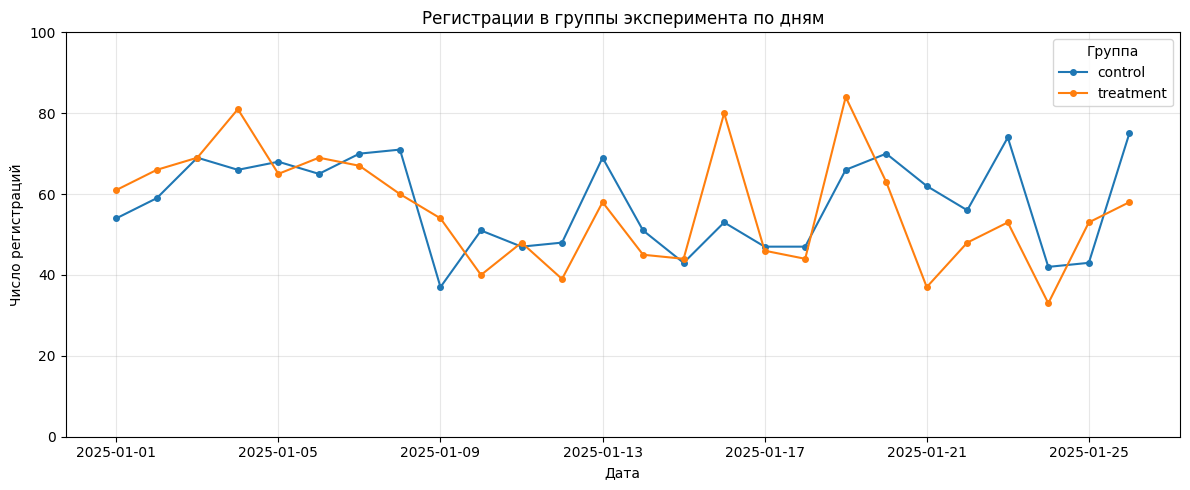

In [69]:
# Распределение регистраций пользователей в группы эксперимента по дням
reg_by_day = (df_users_ab_split
              .groupby([df_users_ab_split['registration_date'].dt.date, 'group'])['user_id']
              .nunique().reset_index(name='registrations')
              )

plt.figure(figsize=(12,5))
for g in groups:
    df_plot = reg_by_day[reg_by_day['group'] == g]
    plt.plot(df_plot['registration_date'], df_plot['registrations'], marker='o', ms=4, label=g)
plt.title('Регистрации в группы эксперимента по дням')
plt.xlabel('Дата')
plt.ylabel('Число регистраций')
plt.ylim(0, 100)
plt.legend(title='Группа')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Вывод по корректности проведения эксперимента

**Распределение по группам честное.** В эксперименте 2968 пользователей: 1503 (50,64%) в контрольной группе и 1465 (49,36%) в тестовой. Отклонение от равного сплита статистически незначимо (биномиальный тест, p = 0,497), то есть SRM (Sample Ratio Mismatch) отсутствует - механизм распределения не отдает систематического предпочтения одной из групп. Пересечений нет: ни один пользователь не попал в обе группы одновременно. Все 2968 участников присутствуют в витрине `users_AB`, канал привлечения у всех - TikTok, что соответствует дизайну эксперимента.

**Однородность групп по атрибутам подтверждена для `os` и `region`, но нарушена для `device`.** Критерий хи-квадрат дает p = 0,599 для `os` и p = 0,700 для `region` - распределения групп по этим признакам неразличимы. По `device` расхождение значимо: chi2 = 11,22 при 2 степенях свободы, p = 0,004. Поправка на множественность проверок (три теста) ситуацию не меняет: скорректированное значение 0,012 остается ниже порога.

Остатки Пирсона локализуют расхождение. Доля desktop совпадает практически точно (остатки +-0,2), весь перекос сосредоточен в паре mobile/tablet и симметричен: в контроле избыток mobile (+1,57) и недостаток tablet (-1,74), в тестовой группе зеркально (-1,59 и +1,77). В абсолютных числах это около 5 п.п. в каждую сторону.

**Величина связи при этом пренебрежимо мала.** Коэффициент Cramer's V равен 0,061. Показатель хи-квадрат растет пропорционально размеру выборки, поэтому при n = 2968 значимым становится и практически несущественное расхождение; Cramer's V от размера выборки не зависит и показывает силу связи как таковую - 0,061 соответствует очень слабой связи.

**Поправок в расчет метрик дисбаланс не требует.** Несбалансированная ковариата угрожает валидности сравнения только в том случае, если она сама предсказывает целевую метрику: тогда перекос в ее распределении переносится в различие исходов. Для `device` такой связи не обнаружено. В разделе сегментации воронка была построена в разрезе устройств и операционных систем на полном объеме исторических данных: конверсия на всех шагах совпадала у desktop, mobile и tablet с точностью до 1-2 процентных пунктов, то есть тип устройства не влияет на поведение пользователя в продукте. Проверка связи `device` с конверсией внутри контрольной группы эксперимента значимого результата также не дала (chi2 = 1,15, p = 0,562), однако при 16 покупателях в контроле ее чувствительность невелика, поэтому основанием служат исторические данные, а не она.

Таким образом, дисбаланс по `device` фиксируется как замечание к качеству механизма рандомизации, но на сопоставимость групп по целевой метрике не влияет: группы различаются по признаку, который с конверсией не связан. Стратификация или пост-стратификация по устройству не требуется.

**Набор выборки шел равномерно.** Регистрации в обе группы идут непрерывно на всем периоде: пропущенных дней нет, провалов до нуля и обрывов не наблюдается. Дневной объем колеблется примерно от 35 до 85 человек в группу без выраженного тренда - это обычный дневной шум трафика, а не систематическое затухание или разгон набора.

Линии групп на всем периоде переплетаются, ни одна из них устойчиво не превосходит другую. Вероятность попадания в тестовую группу, таким образом, не зависела от даты регистрации: сплит отработал равномерно во времени, а не сместился на отдельном отрезке периода. Для сплит-роллинга это ключевое свойство - при дрейфе соотношения групп во времени они могли бы различаться по составу через дату регистрации даже при корректном итоговом балансе.

**Фактический период набора превышает заявленный.** Дизайн фиксирует длительность эксперимента в 3 недели, фактические регистрации идут с 01.01.2025 по 26.01.2025 включительно - 26 календарных дней. Расхождение трактуется как донабор выборки: набор продолжили сверх протокольного срока, что при низкой конверсии канала логично объясняется стремлением увеличить размер групп. Данные последних дней не отсекаются - обрезка периода до заявленных трех недель сократила бы выборку и ухудшила бы и без того ограниченную чувствительность эксперимента, а признаков смены условий проведения теста в этот период нет: набор идет тем же темпом и с тем же соотношением групп. Само отклонение от протокола фиксируется как замечание к дисциплине проведения эксперимента, но основанием для отбрасывания наблюдений не является.

**Итог.** Эксперимент проведен корректно по всем проверенным аспектам: сплит честный по объему и стабильный во времени, группы сопоставимы, пересечений и потерь участников нет. Зафиксированы два замечания, ни одно из которых не препятствует расчету метрик: слабый дисбаланс по не связанному с конверсией признаку `device` и превышение заявленной длительности набора на 5 дней.

Прямое следствие роллинг-набора - разная длительность наблюдения у пользователей: зарегистрировавшиеся в начале периода имели на первую покупку существенно больше времени, чем пришедшие в последние дни.

### Анализ результатов A/B эксперимента

#### Основная метрика: Конверсия в первую покупку

Конверсия в первую покупку - доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку

Цель: увеличить конверсию с помощью бонуса

Критерий успеха: статистически значимый рост конверсии в тестовой группе


Гипотеза для проверки:

**H0:** Конверсия в первую покупку в контрольной группе не ниже, чем в тестовой (p_a >= p_b)

**H1:** Конверсия в первую покупку в контрольной группе ниже, чем в тестовой (p_a < p_b)

In [70]:
# Проверка: любая покупка участника эксперимента является для него первой
ord_check = df_orders_ab_split.merge(
    df_users_ab_split[['user_id', 'registration_date']], on='user_id', how='left')

no_reg = ord_check['registration_date'].isna()
display(f"строк заказов без даты регистрации: {no_reg.sum()}")

delta_h = ((ord_check.loc[~no_reg, 'order_date']
            - ord_check.loc[~no_reg, 'registration_date']).dt.total_seconds() / 3600)
display(f"заказов раньше регистрации: {(delta_h < 0).sum()}")
display('Часов от регистрации до заказа:')
display(delta_h.describe().round(1))

'строк заказов без даты регистрации: 0'

'заказов раньше регистрации: 0'

'Часов от регистрации до заказа:'

count    253.0
mean     188.9
std      133.4
min        0.0
25%       73.7
50%      177.6
75%      277.4
max      573.9
dtype: float64

Заказов, датированных ранее регистрации пользователя, не обнаружено; строк заказов без сопоставленной даты регистрации нет. Следовательно, наличие у участника эксперимента хотя бы одного заказа равносильно совершению им первой покупки, и конверсия в первую покупку вычисляется как доля пользователей группы, имеющих хотя бы один заказ.

Распределение времени от регистрации до заказа: медиана 177,6 часа (7,4 дня), верхняя квартиль 277,4 часа (11,6 дня), максимум 573,9 часа (23,9 дня). Типичный путь до первой покупки занимает около недели, тогда как у пользователей, зарегистрированных в последние дни периода, остаточное окно наблюдения меньше этого срока. Такие пользователи не успевают дойти до покупки к моменту среза данных и учитываются в знаменателе конверсии, но не в числителе. Это занижает как конверсию последних когорт набора, так и общий уровень метрики по эксперименту.

Метрика измеряется на уровне пользователя, то есть единица наблюдения совпадает с единицей рандомизации. Это позволяет применить стандартный z-тест для долей без линеаризации: каждый пользователь дает ровно одно независимое наблюдение - 0 или 1.

In [71]:
df_users_ab_split['buyer'] = df_users_ab_split['user_id'].isin(df_orders_ab_split['user_id'])
conv_df_ab =  df_users_ab_split.groupby('group').agg(buyers=('buyer', 'sum'),
                                                     users=('user_id', 'nunique'))
conv_df_ab['cr'] = conv_df_ab['buyers'] / conv_df_ab['users']
# Изменение метрики в абсолютном значении
conv_diff = conv_df_ab.loc['treatment', 'cr'] - conv_df_ab.loc['control', 'cr']
# Изменение метрики в относительном значении
conv_uplift = (conv_df_ab.loc['treatment', 'cr'] - conv_df_ab.loc['control', 'cr'])/conv_df_ab.loc['control', 'cr']

display(conv_df_ab)
display(f"Конверсия в первый заказ в контрольной группе: {conv_df_ab.loc['control', 'cr']:.2%}")
display(f"Конверсия в первый заказ в тестовой группе: {conv_df_ab.loc['treatment', 'cr']:.2%}")
display(f"Разница между группами (абсолютное изменение): {100*conv_diff:.2f} пп.")
display(f"Разница между группами (относительное изменение): {conv_uplift:.2%}")

,buyers,users,cr
group,,,
control,16,1503,0.010645
treatment,110,1465,0.075085


'Конверсия в первый заказ в контрольной группе: 1.06%'

'Конверсия в первый заказ в тестовой группе: 7.51%'

'Разница между группами (абсолютное изменение): 6.44 пп.'

'Разница между группами (относительное изменение): 605.33%'

In [72]:
p_a = conv_df_ab.loc['control', 'cr']
p_b = conv_df_ab.loc['treatment', 'cr']
n_a = conv_df_ab.loc['control', 'users']
n_b = conv_df_ab.loc['treatment', 'users']
m_a = conv_df_ab.loc['control', 'buyers']
m_b = conv_df_ab.loc['treatment', 'buyers']

# Предпосылка Z-теста для долей: достаточный размер выборок
if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    display('Предпосылка о достаточном количестве данных выполняется!')
else:
    display('Предпосылка о достаточном количестве данных НЕ выполняется!')

# Z-тест для долей   
alpha = 0.05 
    
stat_ztest, p_value_ztest = proportions_ztest(
        [m_a, m_b],
        [n_a, n_b],
        alternative='smaller' # так как H_1: p_a < p_b
    )

if p_value_ztest < alpha:
    display(f'p-value = {p_value_ztest:.6f} < {alpha}: отвергаем H₀ — '
            f'Конверсия в первую покупку в контрольной группе статистически значимо НИЖЕ, чем в тестовой ')
            
else:
    display(f'p-value = {p_value_ztest:.6f} ≥ {alpha}: не отвергаем H₀ — '
            f'Оснований утверждать, что Конверсия в первую покупку в контрольной группе ниже, чем в тестовой , нет')

'Предпосылка о достаточном количестве данных выполняется!'

'p-value = 0.000000 < 0.05: отвергаем H₀ — Конверсия в первую покупку в контрольной группе статистически значимо НИЖЕ, чем в тестовой '

Разница составляет +6,44 п.п. в абсолютном выражении и +605% в относительном. Предпосылка о достаточном размере выборок для нормального приближения выполняется (число успехов и неудач в обеих группах превышает 10). Односторонний z-тест для долей дает p-value < 0,001, что существенно ниже уровня значимости 0,05.

**H0 отвергается: конверсия в первую покупку в тестовой группе статистически значимо выше, чем в контрольной.** Критерий успеха, заданный дизайном эксперимента, достигнут.

#### Вспомогательная метрика: ARPU (средняя выручка на пользователя TikTok) 

Гипотезы для проверки:

**H0:** ARPU в контрольной группе не ниже, чем в тестовой (arpu_control >= arpu_treatment)

**H1:** ARPU в контрольной группе ниже, чем в тестовой (arpu_control < arpu_treatment)


In [73]:
# Выручка площадки - 5% комиссии, как и в исторической части
df_orders_ab_split['revenue'] = df_orders_ab_split['total_price'] * 0.05

rev_by_user = df_orders_ab_split.groupby('user_id')['revenue'].sum().reset_index()

arpu_df = pd.merge(df_users_ab_split[['user_id', 'group']], rev_by_user, on='user_id', how='left')
arpu_df['revenue'] = arpu_df['revenue'].fillna(0)   

arpu_tab = (arpu_df.groupby('group')['revenue']
            .agg(arpu='mean', std='std', users='count')
            .reindex(groups))
display(arpu_tab.round(2))
# Изменение ARPU в абсолютном значении
arpu_diff = arpu_tab.loc['treatment', 'arpu'] - arpu_tab.loc['control', 'arpu']
# Изменение ARPU в относительном значении
arpu_uplift = (arpu_tab.loc['treatment', 'arpu'] - arpu_tab.loc['control', 'arpu'])/arpu_tab.loc['control', 'arpu']

display(f"Значение ARPU в контрольной группе: {arpu_tab.loc['control', 'arpu']:.2f}")
display(f"Значение ARPU в тестовой группе: {arpu_tab.loc['treatment', 'arpu']:.2f}")
display(f"Разница между группами (абсолютное изменение): {arpu_diff:.2f} руб.")
display(f"Разница между группами (относительное изменение): {arpu_uplift:.2%}")


,arpu,std,users
group,,,
control,12.59,143.04,1503
treatment,130.97,754.75,1465


'Значение ARPU в контрольной группе: 12.59'

'Значение ARPU в тестовой группе: 130.97'

'Разница между группами (абсолютное изменение): 118.38 руб.'

'Разница между группами (относительное изменение): 940.47%'

In [74]:
arpu_control = arpu_df.loc[arpu_df['group'] == 'control', 'revenue']
arpu_treatment = arpu_df.loc[arpu_df['group'] == 'treatment', 'revenue']

alpha = 0.05 

# t-тест Уэлча  
stat_ttest, p_value_ttest = ttest_ind(
    arpu_control, 
    arpu_treatment, 
    alternative='less',
    equal_var=False        # поправка Уэлча из-за тяжелых хвостов
) 
if p_value_ttest < alpha:
    display(f'p-value = {p_value_ttest:.6f} < {alpha}: отвергаем H₀ — '
            f'ARPU в контрольной группе статистически значимо НИЖЕ, чем в тестовой'
            f'(в тестовой: {arpu_treatment.mean():.1f}, в контрольной: {arpu_control.mean():.1f})')
else:
    display(f'p-value = {p_value_ttest:.6f} ≥ {alpha}: не отвергаем H₀ — '
            f'Оснований утверждать, что ARPU в контрольной группе ниже, чем в тестовой, нет')


'p-value = 0.000000 < 0.05: отвергаем H₀ — ARPU в контрольной группе статистически значимо НИЖЕ, чем в тестовой(в тестовой: 131.0, в контрольной: 12.6)'

Метрика считается по всем пользователям группы: непокупатели входят в расчет с нулевой выручкой, поэтому единица наблюдения совпадает с единицей рандомизации и линеаризация не требуется.

Разница составляет +118,38 руб на пользователя, или +940,5% в относительном выражении. Односторонний t-тест Уэлча (поправка на неравные дисперсии из-за тяжелых хвостов) дает p-value < 0,000001 при alpha = 0,05.

**H0 отвергается: ARPU в тестовой группе статистически значимо выше, чем в контрольной.**


#### Вспомогательная метрика: ARPPU (средняя выручка на покупателя TikTok) 

Гипотезы для проверки:

**H0:** ARPPU в контрольной группе не ниже, чем в тестовой (arppu_control >= arppu_treatment)

**H1:** ARPPU в контрольной группе ниже, чем в тестовой (arppu_control < arppu_treatment)


In [75]:
# ARPPU - выручка на покупателя. Знаменатель - только совершившие покупку
arppu_df = arpu_df[arpu_df['revenue'] > 0].copy()

arppu_tab = (arppu_df.groupby('group')['revenue']
             .agg(arppu='mean', median='median', std='std', buyers='count')
             .reindex(groups))
display(arppu_tab.round(2))

# Изменение ARPPU в абсолютном значении
arppu_diff = arppu_tab.loc['treatment', 'arppu'] - arppu_tab.loc['control', 'arppu']
# Изменение ARPPU в относительном значении
arppu_uplift = (arppu_tab.loc['treatment', 'arppu'] - arppu_tab.loc['control', 'arppu'])/arppu_tab.loc['control', 'arppu']

display(f"Значение ARPPU в контрольной группе: {arppu_tab.loc['control', 'arppu']:.2f}")
display(f"Значение ARPPU в тестовой группе: {arppu_tab.loc['treatment', 'arppu']:.2f}")
display(f"Разница между группами (абсолютное изменение): {arppu_diff:.2f} руб.")
display(f"Разница между группами (относительное изменение): {arppu_uplift:.2%}")


,arppu,median,std,buyers
group,,,,
control,1182.42,981.39,757.26,16
treatment,1744.24,827.56,2193.48,110


'Значение ARPPU в контрольной группе: 1182.42'

'Значение ARPPU в тестовой группе: 1744.24'

'Разница между группами (абсолютное изменение): 561.82 руб.'

'Разница между группами (относительное изменение): 47.52%'

In [76]:
arppu_control = arppu_df.loc[arppu_df['group'] == 'control', 'revenue']
arppu_treatment = arppu_df.loc[arppu_df['group'] == 'treatment', 'revenue']

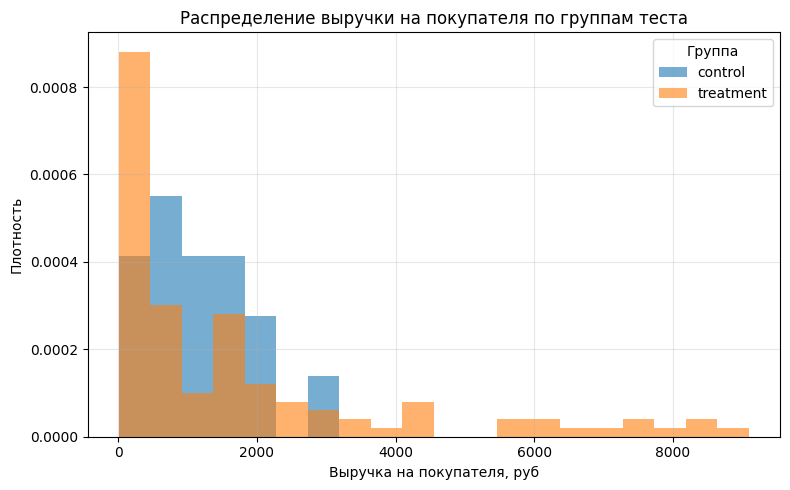

In [77]:
bins = np.histogram_bin_edges(
    np.concatenate([arppu_control.values, arppu_treatment.values]), bins=20)

plt.figure(figsize=(8, 5))
plt.hist(arppu_control, bins=bins, alpha=0.6, label='control', density=True)
plt.hist(arppu_treatment, bins=bins, alpha=0.6, label='treatment', density=True)
plt.title('Распределение выручки на покупателя по группам теста')
plt.xlabel('Выручка на покупателя, руб')
plt.ylabel('Плотность')
plt.legend(title='Группа')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Распределение выручки на покупателя тяжелохвостое, а размеры групп различаются на порядок (16 против 110). В такой ситуации один критерий дает неполную картину, поэтому применяются два теста, отвечающие на разные вопросы:

- **t-тест Уэлча** сравнивает средние. Он чувствителен к хвосту распределения: несколько крупных заказов сдвигают среднее и влияют на результат. Поправка Уэлча учитывает неравенство дисперсий в группах.
- **Тест Манна-Уитни** проверяет сдвиг распределения целиком, опираясь на ранги, а не на величины. К выбросам он практически нечувствителен.

Совпадение результатов означало бы, что эффект однороден. Расхождение также информативно: оно локализует эффект - показывает, создается ли различие основной массой наблюдений или только хвостом. Оба теста заявлены до расчета, выбор между ними по факту полученных p-value не производится.

In [78]:
# t-тест Уэлча  
stat_ttest, p_value_ttest = ttest_ind(
    arppu_control, 
    arppu_treatment, 
    alternative='less',
    equal_var=False        # поправка Уэлча из-за тяжелых хвостов
) 
if p_value_ttest < alpha:
    display(f'p-value = {p_value_ttest:.6f} < {alpha}: отвергаем H₀ — '
            f'ARPPU в контрольной группе статистически значимо НИЖЕ, чем в тестовой'
            f'(в тестовой: {arppu_treatment.mean():.1f}, в контрольной: {arppu_control.mean():.1f})')
else:
    display(f'p-value = {p_value_ttest:.6f} ≥ {alpha}: не отвергаем H₀ — '
            f'Оснований утверждать, что ARPPU в контрольной группе ниже, чем в тестовой, нет')


# Тест на сдвиг распределения - не зависит от хвоста
stat_mw, p_value_mw = st.mannwhitneyu(
    arppu_control,
    arppu_treatment,
    alternative='less')
display(f"Манна-Уитни (сдвиг распределения): U = {stat_mw:.0f}, p-value = {p_value_mw:.4f}")

'p-value = 0.025436 < 0.05: отвергаем H₀ — ARPPU в контрольной группе статистически значимо НИЖЕ, чем в тестовой(в тестовой: 1744.2, в контрольной: 1182.4)'

'Манна-Уитни (сдвиг распределения): U = 950, p-value = 0.6973'

Разница средних составляет +561,82 руб (+47,5%). Односторонний t-тест Уэлча дает p-value = 0,0254 при alpha = 0,05, то есть формально H0 отвергается. Однако прочие показатели этот вывод не поддерживают.

**Медиана в тестовой группе не выросла, а снизилась:** 827,56 против 981,39 руб. Типичный покупатель тестовой группы тратит меньше типичного покупателя контроля. Тест Манна-Уитни, проверяющий сдвиг распределения и устойчивый к выбросам, различий не обнаруживает (p = 0,6973).

Гистограмма объясняет расхождение критериев. Распределение контрольной группы компактно и целиком укладывается в диапазон до 3 тыс. руб. Тестовая группа имеет одновременно более высокую плотность в области малых сумм и протяженный правый хвост до 9 тыс. руб, полностью отсутствующий в контроле. То есть бонус изменил распределение в обе стороны: добавил и мелкие покупки, и крупные. Среднее выросло за счет второй составляющей, медиана снизилась за счет первой.

**Итог по метрике: рост среднего есть, но он создается верхней частью распределения, а не смещением основной массы покупателей.** Утверждать, что бонус повышает выручку с покупателя, на этих данных нельзя. Более точная формулировка: бонус привел покупателей с более разнородными чеками, среди которых типичный чек ниже, чем у органических.

ARPPU относится к вспомогательным метрикам: решение по эксперименту принимается по основной метрике и барьерной. Диагностическая ценность результата в том, что он снимает опасение о привлечении исключительно маржинальных покупателей - средняя выручка с покупателя не упала, - но и подтверждения роста качества покупателей не дает.

#### Вспомогательная метрика: AOV (средний чек TikTok)

**Метрика требует линеаризации**. AOV - отношение суммы заказов к их числу, то есть знаменатель метрики измеряется в заказах, тогда как рандомизация проводилась по пользователям. Один пользователь может совершить несколько заказов, и его заказы не являются независимыми наблюдениями: они принадлежат одному человеку с общим уровнем трат. Прямое сравнение средних по заказам занижает дисперсию и завышает вероятность ложного срабатывания, поскольку число независимых наблюдений в действительности равно числу пользователей, а не заказов.

Линеаризация сводит отношение к линейной метрике на уровне пользователя. Для каждого пользователя считается:

`aov_linearized = сумма его заказов - global_aov_new * число его заказов`

где `global_aov_new` - глобальный средний чек, рассчитанный по контрольной группе. Содержательно линеаризованное значение показывает, насколько траты пользователя отличаются от трат условного пользователя контрольной группы с тем же числом заказов. Величина считается по одному значению на пользователя, поэтому к ней применим обычный t-тест.

Заказ, как и в исторической части, определяется связкой `user_id` + `order_date`: поле `order_id` нумерует товарные позиции, а не заказы целиком.

Гипотезы для проверки:

**H0:** AOV в контрольной группе не ниже, чем в тестовой (aov_control >= aov_treatment)

**H1:** AOV в контрольной группе ниже, чем в тестовой (aov_control < aov_treatment)


In [79]:
full_orders_ab = df_orders_ab_split.groupby(['user_id', 'order_date', 'group'])['total_price'].sum().reset_index(name='order_sum')
aov_df = full_orders_ab.groupby(['user_id', 'group'])['order_sum'].agg(orders='count', total_sum='sum').reset_index()
# Рассчитываем глобальное среднее по данным контрольной группы
global_aov_new = aov_df[aov_df['group'] == 'control']['total_sum'].sum() / aov_df[aov_df['group'] == 'control']['orders'].sum()
# Для каждой строчки проводим линеаризацию метрики
aov_df['aov_linearized'] = aov_df['total_sum'] - global_aov_new * aov_df['orders']

aov_tab = (aov_df.groupby('group')
           .agg(buyers=('user_id', 'nunique'),
                orders=('orders', 'sum'),
                total_sum=('total_sum', 'sum'),
                lin_mean=('aov_linearized', 'mean'))
           .reindex(groups))
aov_tab['aov'] = aov_tab['total_sum'] / aov_tab['orders']
aov_tab['orders_per_buyer'] = aov_tab['orders'] / aov_tab['buyers']
display(aov_tab.round(2))

# Изменение AOV в абсолютном значении
aov_diff = aov_tab.loc['treatment', 'aov'] - aov_tab.loc['control', 'aov']
# Изменение AOV в относительном значении
aov_uplift = (aov_tab.loc['treatment', 'aov'] - aov_tab.loc['control', 'aov'])/aov_tab.loc['control', 'aov']


display(f"Значение AOV в контрольной группе: {aov_tab.loc['control', 'aov']:.2f}")
display(f"Значение AOV в тестовой группе: {aov_tab.loc['treatment', 'aov']:.2f}")
display(f"Разница между группами (абсолютное изменение): {aov_diff:.2f} руб.")
display(f"Разница между группами (относительное изменение): {aov_uplift:.2%}")


,buyers,orders,total_sum,lin_mean,aov,orders_per_buyer
group,,,,,,
control,16,18,378372.90,-0.00,21020.72,1.12
treatment,110,118,3837328.46,12335.31,32519.73,1.07


'Значение AOV в контрольной группе: 21020.72'

'Значение AOV в тестовой группе: 32519.73'

'Разница между группами (абсолютное изменение): 11499.02 руб.'

'Разница между группами (относительное изменение): 54.70%'

In [80]:
aov_control = aov_df.loc[aov_df['group'] == 'control', 'aov_linearized']
aov_treatment = aov_df.loc[aov_df['group'] == 'treatment', 'aov_linearized']

# t-тест Уэлча  
stat_ttest, p_value_ttest = ttest_ind(
    aov_control, 
    aov_treatment, 
    alternative='less',
    equal_var=False        # поправка Уэлча из-за тяжелых хвостов
) 
if p_value_ttest < alpha:
    display(f'p-value = {p_value_ttest:.6f} < {alpha}: отвергаем H₀ — '
            f'AOV в контрольной группе статистически значимо НИЖЕ, чем в тестовой'
            )
else:
    display(f'p-value = {p_value_ttest:.6f} ≥ {alpha}: не отвергаем H₀ — '
            f'Оснований утверждать, что AOV в контрольной группе ниже, чем в тестовой, нет')


'p-value = 0.023597 < 0.05: отвергаем H₀ — AOV в контрольной группе статистически значимо НИЖЕ, чем в тестовой'

Разница составляет +11 499,02 руб (+54,7%). Метрика линеаризована: сравнение проводится по линеаризованному значению на уровне пользователя, что приводит единицу измерения в соответствие с единицей рандомизации. Односторонний t-тест Уэлча по линеаризованной метрике дает p-value = 0,0236 при alpha = 0,05.

**H0 отвергается: AOV в тестовой группе статистически значимо выше, чем в контрольной.**

#### Барьерная метрика: общая выручка от пользователей TikTok

Дизайн задает барьерной метрикой суммарную выручку от пользователей TikTok. В таком виде метрика статистической проверке не поддается: сумма по группе есть единственное число, у него нет выборочного распределения, а следовательно нет ни стандартной ошибки, ни p-value. Тестировать нечего.

Однако сумма не является независимой величиной. Она раскладывается на константу и случайную часть:

`общая выручка = число пользователей в группе x ARPU`

Число пользователей задано дизайном эксперимента и случайной величиной не является, вся изменчивость сосредоточена в ARPU. Умножение на константу не меняет ни знак разницы, ни ее значимость, поэтому проверка гипотезы о суммарной выручке тождественна проверке гипотезы об ARPU, выполненной выше: p-value < 0,000001, выручка в тестовой группе значимо выше.

Дополнительно: прямое сравнение сумм некорректно и по другой причине - группы различаются по численности (1503 против 1465). Разница сумм примерно в 2,5% возникла бы даже при полностью идентичном поведении пользователей. Нормировка на пользователя устраняет этот артефакт, и именно поэтому метрики следует задавать на единицу рандомизации, а не в абсолютных величинах.

**Замечание к дизайну эксперимента.** Барьерная метрика в исходной формулировке нетестируема и дублирует вспомогательную ARPU. Корректная постановка барьерной метрики требует, во-первых, задания на единицу рандомизации, во-вторых - содержательной независимости от ключевой метрики: барьер должен отслеживать риск, которого ключевая метрика не видит. Здесь же рост конверсии автоматически тянет за собой рост выручки, поэтому такой барьер не способен зафиксировать ухудшение и защитной функции не выполняет.

**Главная проблема.** Стоимость бонуса в данных отсутствует: поле `total_price` содержит суммы заказов без вычета скидки. Величина выданных бонусов неизвестна, поэтому вопрос, ради которого барьерная метрика, вероятно, вводилась ("Не съел ли бонус прирост выручки"), на имеющихся данных не решается в принципе.

In [81]:
rev_total = (arpu_df.groupby('group')
             .agg(users=('user_id', 'nunique'), revenue=('revenue', 'sum'))
             .reindex(groups))
rev_total['arpu'] = rev_total['revenue'] / rev_total['users']
display(rev_total.round(2))

display(f"Общее значение выручки в контрольной группе: {rev_total.loc['control', 'revenue']:,.0f}")
display(f"Общее значение выручки в тестовой группе: {rev_total.loc['treatment', 'revenue']:,.0f}")
display(f"отношение: {rev_total.loc['treatment', 'revenue'] / rev_total.loc['control', 'revenue']:.1f}x")

,users,revenue,arpu
group,,,
control,1503,18918.64,12.59
treatment,1465,191866.42,130.97


'Общее значение выручки в контрольной группе: 18,919'

'Общее значение выручки в тестовой группе: 191,866'

'отношение: 10.1x'

Выручка тестовой группы превышает контрольную в 10,1 раза, тогда как ARPU - в 10,4 раза. Расхождение иллюстрирует изложенный выше аргумент: тестовая группа меньше контрольной на 2,5% (1465 против 1503), и абсолютная сумма занижает эффект ровно на эту величину. Содержательным различием между группами это расхождение не является.

**Барьер не нарушен: выручка от пользователей TikTok выросла, а не снизилась.** Значимость этого роста установлена тестом по ARPU (p-value < 0,000001). При этом, как отмечено выше, вывод касается выручки, а не чистого дохода: расходы на бонусы в данных отсутствуют и из выручки не вычтены.

## Выводы по эксперименту

### Главное

**Бонус на первую покупку работает: конверсия пользователей TikTok выросла с 1,06% до 7,51%, и покупатели тестовой группы приносят больше, а не меньше.** Это ответ на ключевой вопрос эксперимента: можно ли повлиять на трафик TikTok продуктовой механикой или канал непригоден по своей природе. Трафик управляем - при финансовом стимуле пользователи, практически не конвертировавшиеся в органике, доходят до покупки, причем без падения средней выручки с покупателя.

**Однако рекомендовать внедрение по итогам этого эксперимента нельзя.** Стоимость бонуса в данных отсутствует: выгрузка содержит суммы заказов без вычета предоставленной скидки, а размер выданных бонусов неизвестен. Измерен эффект механики, но не ее цена, поэтому экономический результат - основной вопрос при принятии решения - не вычисляется ни в каком виде. Вывод эксперимента следует читать как "механика влияет на поведение", а не как "механику следует раскатывать".

### Результаты по метрикам

| Метрика | Контроль | Тест | Изменение | p-value | Вердикт |
|---|---|---|---|---|---|
| **CR в первую покупку** (основная) | 1,06% | 7,51% | +6,44 п.п. | < 0,000001 | H0 отвергается |
| ARPU | 12,59 руб | 130,97 руб | +118,38 руб | < 0,000001 | H0 отвергается |
| ARPPU | 1 182,42 руб | 1 744,24 руб | +561,82 руб | 0,0254 | H0 отвергается, вывод неустойчив |
| AOV (линеаризован) | 21 020,72 руб | 32 519,73 руб | +11 499,02 руб | 0,0236 | H0 отвергается |
| Выручка от TikTok (барьер) | 18 919 руб | 191 866 руб | x10,1 | см. ARPU | барьер не нарушен |

**Основная метрика дает однозначный результат.** Рост конверсии в семь раз при p-value ниже одной миллионной не оставляет сомнений в наличии и направлении эффекта. Критерий успеха, заданный дизайном эксперимента, достигнут.

**ARPU растет как следствие конверсии.** Прирост в 10,4 раза складывается из роста числа покупателей в 7,05 раза и роста выручки с покупателя примерно в 1,47 раза: основной вклад дает увеличение числа платящих, дополнительный - более высокие суммы их покупок.

**ARPPU и AOV показывают рост среднего, но не сдвиг основной массы покупателей.** Средний чек вырос на 54,7%, выручка с покупателя - на 47,5%, оба различия формально значимы. При этом медиана выручки на покупателя в тестовой группе не выросла, а снизилась (827,56 против 981,39 руб), и тест Манна-Уитни сдвига распределения не обнаруживает (p = 0,6973). Прирост средних создается верхней частью распределения тестовой группы: бонус привел покупателей с более разнородными чеками, среди которых встречаются заметно более крупные заказы, чем в контроле. Обе метрики вспомогательные и решающего значения не имеют; их роль диагностическая - они снимают опасение, что стимул приводит исключительно маржинальных покупателей с мелкими корзинами.

**Частота покупок не изменилась.** Число заказов на покупателя составляет 1,13 в контроле и 1,07 в тесте. Бонус действует ровно на то, для чего предназначен - на первую покупку, - и повторные заказы не стимулирует. Это ожидаемое поведение механики, а не недостаток.

**Барьерная метрика не нарушена:** выручка от пользователей TikTok выросла более чем в десять раз, значимость подтверждается тестом по ARPU.

### Ограничения оценки

**Отсутствует статья затрат.** Расходы на бонусы в данных не представлены, поэтому окупаемость механики не рассчитывается. Все приведенные суммы описывают выручку, а не чистый доход площадки, и являются оценкой сверху. Косвенный ориентир при этом настораживает: стоимость привлечения пользователя TikTok составляет 437 руб (расчет в разделе сегментации), тогда как ARPU тестовой группы за период эксперимента - 131 руб, то есть привлечение не окупается втрое даже при условно бесплатном бонусе. Сопоставление индикативное: горизонт наблюдения здесь короче, чем при расчете LTV по историческим когортам, и часть выручки лежит за пределами среза. Тем не менее оно показывает масштаб задачи - для выхода канала в окупаемость роста конверсии в семь раз может оказаться недостаточно.

**Горизонт наблюдения покрывает только первую покупку.** Период эксперимента составляет 26 дней, за которые измерен факт совершения первого заказа. Удержание стимулированных пользователей, их повторные покупки и поведение после прекращения бонуса не наблюдались. Утверждение, что бонус превращает трафик TikTok в качественную аудиторию, данными не подтверждено: подтвержден только факт первой покупки. Ключевая проблема канала, установленная при сегментации, состояла не только в низкой конверсии, но и в слабом удержании - этот аспект эксперимент не проверял.

**Часть пользователей не имела полного окна на покупку.** При роллинг-наборе зарегистрировавшиеся в последние дни периода не успевали дойти до покупки: медианный путь до первого заказа составляет 7,4 дня. Такие пользователи входят в знаменатель конверсии, но не в числитель, что занижает уровень метрики в обеих группах. На сравнение групп это не влияет, поскольку сплит равномерен во времени, но снижает чувствительность и делает абсолютные значения конверсии заниженными.

### Замечания к дизайну эксперимента

Дизайн-документ прямо фиксирует, что эксперимент запускался в срочном порядке без предварительного расчета мощности и MDE. Два следствия этого стоит отметить, ни одно из них на итоговый вывод не повлияло.

Во-первых, при базовой конверсии около 1% и фактических размерах групп эксперимент был способен зафиксировать только очень крупный эффект. Фактический эффект оказался существенно крупнее этого порога, поэтому результат получен, однако при более скромном воздействии тест такого размера значимости бы не показал.

Во-вторых, барьерная метрика задана в нетестируемой форме. Суммарная выручка по группе есть единственное число без выборочного распределения; ее статистическая проверка сводится к проверке ARPU, уже входящей в состав вспомогательных метрик. Корректно поставленный барьер должен, во-первых, задаваться на единицу рандомизации, во-вторых - отслеживать риск, невидимый для ключевой метрики. Здесь же рост конверсии автоматически влечет рост выручки, поэтому такой барьер не способен зафиксировать ухудшение и защитной функции не выполняет. Барьером, отвечающим замыслу, была бы чистая выручка за вычетом стоимости бонусов - но именно этих данных в выгрузке нет.

### Риски финансового стимулирования

Результат эксперимента не учитывает эффектов, проявляющихся за пределами периода наблюдения:

- **Привыкание к скидке.** Аудитория, приученная покупать по промо, склонна откладывать покупки до следующего предложения. Конверсия без бонуса после его отмены может оказаться ниже исходной.
- **Каннибализация.** Часть стимулированных заказов совершили бы и без бонуса. Верхняя оценка этой доли задается органической конверсией канала: 1,06% в контрольной группе, до 3-4% по историческим данным на 30-дневном окне. Даже по верхней границе это малая часть от 7,51% в тестовой группе, то есть подавляющее большинство стимулированных покупок без бонуса не состоялось бы. Риск для данного канала невелик, но при расчете окупаемости бонус все равно будет выплачен и той части покупателей, которая купила бы и так.
- **Злоупотребления.** Бонус на первую покупку создает прямой стимул к созданию повторных аккаунтов. Требуется контроль мультиаккаунтов по устройству, платежным реквизитам и адресу доставки, иначе часть бюджета уйдет на обслуживание одних и тех же пользователей.
- **Отбор аудитории, реагирующей только на промо.** Механика привлекает не пользователей, заинтересованных в продукте, а пользователей, заинтересованных в скидке. Их долгосрочная ценность может оказаться низкой независимо от успешной первой покупки.

### Рекомендации

**Не раскатывать механику по итогам этого эксперимента, а достроить измерение.** Эффект на поведение установлен надежно, экономический эффект не установлен вовсе, и именно он определяет решение.

Для получения ответа требуется:

1. **Получить стоимость бонуса** в разрезе пользователя и пересчитать выручку за вычетом скидок. Это минимально необходимое условие для любого вывода об окупаемости.
2. **Продлить наблюдение** за участниками эксперимента на 2-3 месяца, чтобы измерить удержание, повторные покупки и поведение после прекращения действия бонуса. Ключевой вопрос - остаются ли стимулированные пользователи в продукте или совершают одну покупку и уходят.
3. **Сопоставить полученный LTV с CAC канала** (437 руб). Решение о сохранении TikTok в структуре привлечения принимается по этому сопоставлению, а не по конверсии.
4. **Сравнить экономику механики с альтернативой** - перераспределением того же бюджета в окупаемые каналы (Affiliate, Google Ads), рекомендованным по итогам сегментации. Бонус имеет смысл, если он выводит TikTok в окупаемость дешевле, чем стоит замещение канала.

До получения этих данных корректная формулировка результата такова: **бонус на первую покупку способен многократно повысить конверсию трафика TikTok, но достаточно ли этого для окупаемости канала - на имеющихся данных неизвестно.**